# Assignment 4: DEM, Silo Discharge and the Beverloo Law

**6EMA02 Particle-based Simulations, 2026-2027 edition**
Discrete element method · contacts and friction · granular flow

## How this assignment is assessed: read this first

This notebook is both the assignment text and your report. Task cells
(like this one) are the assignment text and are marked read-only. Jupyter
enforces that; some editors (VS Code among them) do not, so simply leave
them untouched either way: hand-ins are checked against the released
notebook, and modified task cells are flagged. You write your answers in
the cells below each task and hand in this same notebook, **executed**,
together with an HTML export, your code, and the data files the notebook
loads (layout at the end of this notebook).

Your report is **not graded on its content**. Its result is determined in
the individual oral examination at the end of the quartile: the exam is a
conversation about *your* code and *your* results, with this notebook on
screen. Write it as your defence dossier: concise, bullet answers are
fine, every claim something you can stand behind. A report you never hand
in scores 0 for its weight in the final grade; a handed-in report's
result *is* your oral grade.

**AI and sources.** You may use AI assistants (ChatGPT, Claude, Copilot,
…) freely in this course, for code, analysis, and text. Declare the use
briefly in the *Sources* section below, along with any other external
sources: anything in your submission (code, text, data, results) that
your group did not produce itself. Declared sources are never penalised:
nobody grades the text of your report or the style of your code. The oral
examination assesses what *you* understand about the simulation you hand
in. Anything in your submission is fair game, and "we didn't write that
part" is not an available answer. Presenting undeclared external work as
your own is academic misconduct and is treated as such.

## Group

- **Group ID:** A4_8
- **Members:** Tomas Dadikozyan (1959123), Shree Patil (1966723)

<a id="glance"></a>

## Results at a glance

One row per sub-task; the block (figures, formulas, code, Oral prep at the end of each part) is one click away. Values as $x \pm \mathrm{d}x$ (stat) or (syst); an explanation that we did not test starts with *Hypothesis, untested:* in the blocks.

| Block | Headline result | Value |
|---|---|---|
| [A1](#A1) particle-wall | restitution recovered at $\Delta t = t_c/20$ | $e = 0.848$ (tabulated 0.85), error $-0.14$ to $-0.24\,\%$ |
| [A2](#A2) two particles | restitution recovered at $\Delta t = t_c/20$ | $e = 0.919$ (tabulated 0.92), error $-0.01$ to $-0.07\,\%$ |
| [time step](#Adt) | steps per contact for 1 % at all three speeds | 10 (A1 worst 0.90 %); $t_c/20$: worst 0.24 %; single collisions up to $+1.47\,\%$ ([phase](#Aphase)) |
| [B1](#B1) onset | slope angle at which the bed starts to move | $\theta_c = 12^\circ \pm 0.6^\circ$ (syst, threshold), 11.7° at 20 °/s, 12.1° at 10 °/s |
| [B2](#B2) prediction | block sliding on the floor, $\arctan\mu_w$ | 24.2°: the bed fails at half of it |
| [B3](#B3) bottom layer | speed ratio bottom layer / bed above at 19.8° | 0.57 (rolling 0.5, sliding 1) |
| [C1](#C1) cylinder | wall code against a brute-force closest point | 685 455 random particles, 0 failures |
| [C2](#C2) edge of the hole | discharge without the edge | $16 \pm 2\,\%$ faster (5 seeds) |
| [C3](#C3) fill | kinetic energy at $t_\mathrm{open}$ | $3.9\times10^{-9}$ J, $5.6\times10^{-7}$ of its maximum |
| [C4](#C4) packing | $\phi$, $\rho_b$, $Z$; layering at the wall | $\phi = 0.597 \pm 0.005$ (stat), $-0.013$ (syst); $\rho_b = 1493 \pm 12$ (stat), $-34$ (syst) kg/m³; $Z = 4.51$; period $0.86 \pm 0.01\,d_p$, range $3.5\,d_p$ |
| [D1](#D1) flow | where the material flows, who leaves first | one column at 23 mm/s, funnel over the orifice, stagnant corners; bottom grains of the central column first |
| [D2](#D2) rate | discharge rate, $D = 7\,d_p$ | $Q = 2804 \pm 18$ particles/s $= 29.33 \pm 0.18$ g/s; halves 2842 / 2800 /s ($-1.5\,\%$; water tank $-18\,\%$) |
| [D3](#D3) Beverloo | fitted $k$ and $C$ (literature about 1.5 and 0.58) | $k = 1.59 \pm 0.05$, $C = 0.518 \pm 0.015$ ($-4.2\,\sigma$); $\chi^2 = 1.39$ for 2 dof |
| [D3](#D3) cost | silo twice as wide, four runs | 3.4 h ($\times13.7$); bounds 1.0 h to 3.9 h |
| [D4](#D4) small orifice | $D = 3\,d_p$ | blocked: 8 of 7500 grains in 0.8 s (fitted law: about 78) |

## The physics: granular matter is its own state

Sand pours like a liquid, holds a slope like a solid, and sprays like a
gas, sometimes within one second and one apparatus. Two features of the
grains explain almost all of it, and both are absent from A2 and A3.

**Contacts are dissipative.** Two grains that collide do not bounce back
with the same speed: energy goes into deformation, sound and heat. The
loss is quantified by the **coefficient of restitution**
$e = v_\mathrm{after}/v_\mathrm{before}$, which is 0.92 for our
particles: nearly elastic, and still enough that an unstirred granular
system comes to rest. There is no temperature worth speaking of, because
thermal energy is utterly negligible against $m g d_p$ for a millimetre
grain. Without external driving, granular matter simply stops.

**Contacts are frictional, and they remember.** A grain resting on a
slope is held by static friction. Friction is not a function of the
current positions alone: it depends on how much the contact has been
loaded *since it formed*. That is why the code carries a **tangential
displacement per contact** and why contact history has to survive from
step to step. It is the deepest structural difference from your MD code,
where a pair interaction depends only on the current separation.

**How the forces are modelled.** There is no interaction potential here.
Two particles interact only when they geometrically overlap, and the
model is a **spring and dashpot** in the normal direction, plus a
tangential spring limited by the Coulomb condition
$|\mathbf{F}_t| \le \mu |\mathbf{F}_n|$ (the Cundall-Strack model). The
spring gives the elastic rebound, the dashpot the dissipation, and the
Coulomb limit turns sticking into sliding. Two consequences you will meet
directly:

- The spring and dashpot constants are not free parameters you set. They
  are **derived** from a restitution coefficient and a contact time, and
  Part A verifies that the model gives back the restitution it was built
  from.
- The contact time sets the time step: you need many steps per collision
  to resolve it, so $\Delta t$ is tied to the contact duration and not to
  anything about the flow.

**The physics you will actually test.** A silo is a beautiful case
because it violates the intuition trained on liquids. A draining water
tank slows down as it empties, since the pressure at the outlet falls
with the head of liquid. A silo does not: its discharge rate is
**independent of the fill height**. The reason is that grains transmit
stress through force chains that push outward on the walls, so wall
friction carries most of the weight and the pressure near the bottom
saturates once the filling is more than about a diameter deep. This is
Janssen's classic result, and it is why the outflow depends on the
orifice and not on how much is above it.

What is left is a dimensional argument. If the flow is set by grains
falling freely from an arch of the order of the orifice size, the
velocity scales as $\sqrt{gD}$ and the area as $D^2$, so the mass flow
goes as $\rho_b \sqrt{g} D^{5/2}$. Grains cannot pass within one radius
of the rim, which turns $D$ into an effective $D - k d_p$. That is the
**Beverloo correlation**

$$Q = C\,\rho_b\,\sqrt{g}\,(D - k\,d_p)^{5/2},$$

with $Q$ the mass discharge rate, $\rho_b$ the bulk density of the
packed bed, $d_p$ the particle diameter, and $C$ and $k$ empirical
constants: typically $C \approx 0.58$ (reported values 0.55 to 0.65)
and $k \approx 1.5$. Your job in Part D is to test it quantitatively on
your own simulated silo. At small orifices the same physics turns
against the flow: an arch that forms across the opening can be strong
enough to hold, and the silo clogs. That is task D4.

## The model: particles, walls and parameters

| | Normal restitution | Tangential restitution | Friction |
|---|---|---|---|
| Particle-particle | 0.92 | 0.33 | 0.50 |
| Particle-wall (all walls) | 0.85 | 0.33 | 0.45 |

- Particle diameter $d_p = 2.0$ mm (radii uniform between 0.975 and
  1.024 mm), material density $\rho_p = 2500\ \mathrm{kg/m^3}$,
  mean particle mass $1.046 \times 10^{-5}$ kg.
- Contact time $t_c = 0.219$ ms, the same for a particle-particle and a
  particle-wall contact; time step $\Delta t = t_c/20 = 1.095 \times
  10^{-5}$ s.
- The silo, for Parts C and D: 7500 particles in a cylinder of radius
  $R_\mathrm{cyl} = 17.7$ mm (a diameter of 17.7 $d_p$), bottom plate at
  $z_\mathrm{silo} = 53.1$ mm above the floor of the box, settled fill
  about 58 mm high. All of this is already set in
  `set_silo_geometry`: you do not size anything yourself.

## The code, and how to work with it

The starting code is `DEM_student_v7.1.0.zip` under Files ▸ Code. It has
the same structure as your MD code, so most of it will be familiar.
Unpack it into `code/` in your working directory.

**Every piece of code you write already exists** as a function that
compiles, runs, and is called from the right place; the `\todo` inside
it says exactly what to fill in. Open `html/index.html` from the zip: its
*todo list* has them all. In short:

| Part | function, file | what you write |
|---|---|---|
| A | `initialise_collision`, initialise.c | one particle at the wall, or two head-on |
| B | `update_parameters`, setparameters.c | rotate gravity from $t_\mathrm{tilt}$ on |
| C1 | `cylinder_wall`, walls.c | the silo wall |
| C2 | `silo_bottom_wall`, walls.c; `update_parameters` | the edge of the hole in the plate (the flat plate is given), and opening the orifice at $t_\mathrm{open}$ |
| C3 | `initialise_positions_silo`, initialise.c | the fill: a loose lattice inside the cylinder |
| D2 | `count_in_silo`, walls.c | the number of particles above the plate |

That is all the C you write. **All analysis is done in Python**, from the
table the program prints and from the trajectory file.

**Choosing a run.** The macro `RUN` at the top of `setparameters.c`
selects the set-up: 1 is the test collision of Part A, 2 the tilted bed
of Part B, 3 the silo of Parts C and D. It and the other settings you
vary (`NUM_TEST`, `V_IMPACT`, `DT_FRACTION`, `TILT_RATE`, `D_ORIFICE`,
`T_DISCHARGE`) have defaults there and can be given on the command line,
so every run is one command you can copy into your build log:

```
gcc -O3 -DRUN=1 -DNUM_TEST=2 -DV_IMPACT=1.0 *.c -o dem -lm    # Part A, two particles head-on
gcc -O3 -DRUN=2 *.c -o dem -lm                                # Part B
gcc -O3 -DRUN=3 -DD_ORIFICE=8 -DT_DISCHARGE=1.0 *.c -o dem -lm  # Part D, orifice of 8 d_p
./dem > run.dat
```

(Linux and macOS; on Windows use MSYS2. For debugging:
`gcc -g -Wall -Wextra *.c -o dem_debug -lm`.)

**Output.** Every run prints a table: step, time, coordination number
$Z$ (contacts per particle), potential, kinetic and total energy, and
`N_silo`, the number of particles in the silo. The first line, starting
with `# run`, records the geometry and the time step. Redirect the table
to a file and load it with `numpy.loadtxt`, which skips the `#` lines.
Every run also writes `trajectories.xyz`, a frame every 0.022 s.

**Each run in its own directory.** Every run writes `trajectories.xyz`
and `restart.dat` into the directory it runs in, so two runs in one
directory overwrite each other. Make a directory per run, e.g.
`mkdir -p runs/D8 && cd runs/D8 && ../../code/dem > run.dat`. Runs in
different directories can go in parallel on different cores.

**Visualisation.** Open `trajectories.xyz` in OVITO: the file states the
box, the radii and the speed itself, so no column mapping is needed.
Colour by speed (*Add modification ▸ Color coding ▸* `speed`), and to see
inside the silo add *Slice* (normal (0, 1, 0), slab width 4 mm, through
the centre of the box). Without the slice you only see the particles
against the wall.

**Reading a trajectory in Python.** A frame is a line with the number of
particles, a line with the box and the time, then one line per particle:
`C x y z radius speed`, in SI units. This reads all frames:

```python
import numpy as np, re
def read_xyz(path):
    frames, times = [], []
    with open(path) as f:
        while (line := f.readline()):
            n = int(line)
            times.append(float(re.search(r"Time=(\S+)", f.readline()).group(1)))
            rows = [f.readline() for _ in range(n)]
            frames.append(np.loadtxt(rows, usecols=(1, 2, 3, 4, 5)))
    return np.array(times), frames      # each frame: columns x, y, z, radius, speed
```

Do not hand in trajectories (a silo run writes 20 to 60 MB). Save the one
frame you analyse, e.g. with `np.savetxt`, and the images you make.

**What you do not need to do.** No restart files: every run settles from
the same random seed, so the bed at $t_\mathrm{tilt}$ or
$t_\mathrm{open}$ is identical in every run of a kind. No analysis code
in C. No sizing of the silo. No hunting for the right run length: the
table below gives it.

**Python environment:** the same `pbs-env` as in the earlier
assignments, from `requirements.txt`; `nb2html.py` for the HTML you hand
in and `check_my_submission.py` before you submit. See the Canvas page
*Working on the assignments*.

## The runs, at a glance

Times are for one core of a reference workstation; a laptop may take two
or three times longer. Apart from the 24 tiny runs of Part A, seven runs in
all, about 15 minutes of computing on the reference machine.

| task | command (`gcc -O3 … *.c -o dem -lm`) | simulated | CPU |
|---|---|---|---|
| A | `-DRUN=1 -DNUM_TEST=1` or `2`, `-DV_IMPACT=0.1`, `0.3`, `1.0`, `-DDT_FRACTION=0.2`, `0.1`, `0.05`, `0.025`: 24 runs, a shell loop | 2 ms | < 1 s each |
| B | `-DRUN=2` (20 °/s) and `-DRUN=2 -DTILT_RATE=10` | 1.5 s, 2.7 s | 25 s, 45 s |
| C, D1, D2, D3 | `-DRUN=3` ($D = 7 d_p$, the default) | 2.3 s | 4 min |
| D3 | `-DRUN=3 -DD_ORIFICE=6 -DT_DISCHARGE=1.5`, `=8 … =1.0`, `=9 … =0.8` | 1.1 to 1.8 s | 2 to 3 min each |
| D4 | `-DRUN=3 -DD_ORIFICE=3 -DT_DISCHARGE=0.8` | 1.1 s | 2 min |

Long runs are done in the terminal, never from the notebook; let the
notebook load their output from `data/`.

## Code map: fill in as you go

The examiner uses this table in the oral to jump straight to your code,
so **make the entries clickable links**: a markdown link with a path
relative to this notebook, for example

```
| C1 cylinder wall | [`cylinder_wall`](code/walls.c) | [D7.dat](data/D7.dat) |
```

Relative paths only (`code/…`, `data/…`); everything you link to must be
inside the zip you hand in. `check_my_submission.py` verifies this.

| Task | File / function(s) | Data files |
|------|--------------------|------------|
| A test collision | [`initialise_collision`](code/initialise.c), [`run_a.sh`](code/run_a.sh), [`run_a_scan.sh`](code/run_a_scan.sh), [`analyse_a.py`](code/analyse_a.py) | [A_restitution.csv](data/A_restitution.csv), [A_phase_scan.csv](data/A_phase_scan.csv), [A_A1_v0.3.dat](data/A_A1_v0.3.dat), [A_A2_v0.3.dat](data/A_A2_v0.3.dat) |
| B rotating gravity | [`update_parameters`](code/setparameters.c) (RUN_SLOPE branch), [`extract_frame.py`](code/extract_frame.py) | [B_rate20.dat](data/B_rate20.dat), [B_rate10.dat](data/B_rate10.dat), [B_frame_20deg.dat](data/B_frame_20deg.dat) |
| C1 cylinder wall | [`cylinder_wall`](code/walls.c), [`wall_check.c`](code/tests/wall_check.c) | [D7.dat](data/D7.dat), [C_wall_check.txt](data/C_wall_check.txt) |
| C2 orifice wall | [`silo_bottom_wall`](code/walls.c), [`update_parameters`](code/setparameters.c) (RUN_SILO branch), [`wall_check.c`](code/tests/wall_check.c), [`run_c_noedge.sh`](code/run_c_noedge.sh), [`run_c_seeds.sh`](code/run_c_seeds.sh), [`analyse_c.py`](code/analyse_c.py) (`seeds`, `crossing`) | [C_wall_check.txt](data/C_wall_check.txt), [C_noedge_D7.dat](data/C_noedge_D7.dat), [C_edge_seeds.csv](data/C_edge_seeds.csv), [C_crossing_edge.csv](data/C_crossing_edge.csv), [C_crossing_noedge.csv](data/C_crossing_noedge.csv), [C_seed1_edge.dat](data/C_seed1_edge.dat), [C_seed1_noedge.dat](data/C_seed1_noedge.dat), [C_seed2_edge.dat](data/C_seed2_edge.dat), [C_seed2_noedge.dat](data/C_seed2_noedge.dat), [C_seed3_edge.dat](data/C_seed3_edge.dat), [C_seed3_noedge.dat](data/C_seed3_noedge.dat), [C_seed4_edge.dat](data/C_seed4_edge.dat), [C_seed4_noedge.dat](data/C_seed4_noedge.dat) |
| C3 fill (and C4 packing) | [`initialise_positions_silo`](code/initialise.c), [`extract_frame.py`](code/extract_frame.py), [`render_ovito.py`](code/render_ovito.py), [`analyse_c.py`](code/analyse_c.py) (`settling`) | [D7.dat](data/D7.dat), [C_frame_before_open.dat](data/C_frame_before_open.dat), [C_settling_frames.csv](data/C_settling_frames.csv), [C_snapshot_settled.png](data/C_snapshot_settled.png) |
| D1 discharge snapshots | [`render_ovito.py`](code/render_ovito.py), [`analyse_d.py`](code/analyse_d.py) (exit order, speed map) | [D_D7_early.png](data/D_D7_early.png), [D_D7_middle.png](data/D_D7_middle.png), [D_D7_late.png](data/D_D7_late.png), [D_exit_D7.csv](data/D_exit_D7.csv), [D_speedmap_D7.csv](data/D_speedmap_D7.csv) |
| D2 particles in the silo; discharge rate | [`count_in_silo`](code/walls.c) (written in Part C; explained in Part D); the fit is in the hidden code cell of [D2](#D2) | [D7.dat](data/D7.dat) |
| D3 Beverloo | [`run_d.sh`](code/run_d.sh), [`collect_times.sh`](code/collect_times.sh); the fit is in the hidden code cell of [D3](#D3) | [D6.dat](data/D6.dat), [D7.dat](data/D7.dat), [D8.dat](data/D8.dat), [D9.dat](data/D9.dat), [D_walltimes.csv](data/D_walltimes.csv) |
| D4 small orifice | [`run_d.sh`](code/run_d.sh), [`analyse_d.py`](code/analyse_d.py) (`--stats`), [`render_ovito.py`](code/render_ovito.py) | [D3.dat](data/D3.dat), [D_speedstats_D3.csv](data/D_speedstats_D3.csv), [D_D3_blocked.png](data/D_D3_blocked.png) |

## Sources

**AI tools used:** … / none.
**Used for:** … .
**Other external sources** (code, text, data, or results not produced by
us): … / none.
**Parts of the submission with substantial external content:** … .
**What we did ourselves to verify these parts:** … .

## Build & run log

Exact compile and run commands, machine, and approximate wall-clock time
for each production run whose output sits in `data/`:

**Machine and build.** Windows 11, 20 cores, gcc 14.2 (MSYS2 ucrt64). Every run is its own compilation with the settings as `-D` flags, in its own directory `runs/<name>/` (not handed in), run from `Assignment_4/`; `export PATH=/c/msys64/ucrt64/bin:$PATH` first for gcc in bash.

**Part A** (all runs: `RUN=1`, 2 ms simulated, about 0.04 s per run, so the wall-clock is almost all compilation):

| script | what | wall-clock | output |
|---|---|---|---|
| `bash code/run_a.sh` | 24 runs, one per `NUM_TEST` $\in\{1,2\}$, `V_IMPACT` $\in\{0.1,0.3,1.0\}$, `DT_FRACTION` $\in\{0.2,0.1,0.05,0.025\}$. Each run: `mkdir -p runs/A_<test>_v<v>_f<frac> && gcc -O3 -Wall -Wextra -DRUN=1 -DNUM_TEST=<test> -DV_IMPACT=<v> -DDT_FRACTION=<frac> code/*.c -o runs/A_<test>_v<v>_f<frac>/dem.exe -lm && (cd runs/A_<test>_v<v>_f<frac> && ./dem.exe > run.dat)` | 43 s in total, sequential | `python code/analyse_a.py` gives [A_restitution.csv](data/A_restitution.csv), [A_A1_v0.3.dat](data/A_A1_v0.3.dat), [A_A2_v0.3.dat](data/A_A2_v0.3.dat) (the 0.3 m/s, $t_c/20$ runs, for Figure 1) |
| `bash code/run_a_scan.sh` | 248 runs of the same form (`runs/A_scan_<test>_f<frac>_v<v>/`): both tests, the four `DT_FRACTION`, `V_IMPACT` = 0.10 to 1.00 in steps of 0.03 (31 values), 16 in parallel | 50 s in total | `python code/analyse_a.py` gives [A_phase_scan.csv](data/A_phase_scan.csv) (Figure 2) |

The time step and the contact time follow from the code: $t_c=0.2189$ ms, $\Delta t=$ `DT_FRACTION` $\cdot\, t_c$ ($1.095\times10^{-5}$ s at 0.05).

**Part B** (`RUN=2`, 2000 particles, run from `Assignment_4/`; the two runs went in parallel, one core each; the tables of a second run were bit-identical):

| run | command | simulated | wall-clock | output |
|---|---|---|---|---|
| 20 °/s | `mkdir -p runs/B_rate20 && gcc -O3 -Wall -Wextra -DRUN=2 code/*.c -o runs/B_rate20/dem.exe -lm && (cd runs/B_rate20 && time ./dem.exe > run.dat)` | 1.5 s (about 137 000 steps) | 29 s | `cp runs/B_rate20/run.dat data/B_rate20.dat` ([B_rate20.dat](data/B_rate20.dat)) |
| 10 °/s | `mkdir -p runs/B_rate10 && gcc -O3 -Wall -Wextra -DRUN=2 -DTILT_RATE=10 code/*.c -o runs/B_rate10/dem.exe -lm && (cd runs/B_rate10 && time ./dem.exe > run.dat)` | 2.7 s (about 247 000 steps) | 52 s | `cp runs/B_rate10/run.dat data/B_rate10.dat` ([B_rate10.dat](data/B_rate10.dat)) |
| frame at 20° | `python code/extract_frame.py runs/B_rate20/trajectories.xyz data/B_frame_20deg.dat --time 1.3` | (frame 59, $t = 1.2917$ s, slope 19.83°) | 0.5 s | [B_frame_20deg.dat](data/B_frame_20deg.dat) |

The trajectories (7.7 MB and 14 MB) stay in `runs/`.

**Part C** (`RUN=3`, 7500 particles, 2.3 s = about 210 000 steps of $\Delta t = 1.095\times10^{-5}$ s; run from `Assignment_4/`; `python -m pip install ovito` installed ovito 3.17.0 for the snapshot):

| run | command | simulated | wall-clock | output |
|---|---|---|---|---|
| smoke run | `mkdir -p runs/C_smoke && gcc -O3 -Wall -Wextra -DRUN=3 -DT_DISCHARGE=0.0 code/*.c -o runs/C_smoke/dem.exe -lm && (cd runs/C_smoke && time ./dem.exe > run.dat)` | 0.3 s (settling only) | 27 s | not kept: no NaN, `N_silo` = 7500, $E_\mathrm{kin}$ = 4e-9 J at $t_\mathrm{open}$ |
| **D7** (production, $D = 7\,d_p$, defaults) | `mkdir -p runs/D7 && gcc -O3 -Wall -Wextra -DRUN=3 code/*.c -o runs/D7/dem.exe -lm && (cd runs/D7 && time ./dem.exe > run.dat)` | 2.3 s | 3 min 54 s (other jobs were running) | `cp runs/D7/run.dat data/D7.dat` ([D7.dat](data/D7.dat)); `trajectories.xyz` (45 MB) stays in `runs/` |
| frame before $t_\mathrm{open}$ | `python code/extract_frame.py runs/D7/trajectories.xyz data/C_frame_before_open.dat --frame 13` | frame 13, $t = 0.2846$ s | < 1 s | [C_frame_before_open.dat](data/C_frame_before_open.dat) |
| OVITO snapshot | `python code/render_ovito.py runs/D7/trajectories.xyz data/C_snapshot_settled.png --time 0.286 --zrange 51 113 --xhalf 20 --vmax 0.001 --size 800 1000` | same frame | 6 s | [C_snapshot_settled.png](data/C_snapshot_settled.png) |
| wall check | `gcc -O2 -Wall -Wextra -Icode code/tests/wall_check.c code/walls.c -o runs/_check/wall_check.exe -lm && runs/_check/wall_check.exe > data/C_wall_check.txt` | (685 455 random particles against brute force, plus the flat-plate checks) | 30 s | [C_wall_check.txt](data/C_wall_check.txt) |
| run without the edge of the hole | `bash code/run_c_noedge.sh` (copies the sources to `runs/C_noedge/src`, adds an early `return false` in the edge branch of the copy, compiles with `-DRUN=3` and runs) | 2.3 s | 4 min 45 s | `cp runs/C_noedge/run.dat data/C_noedge_D7.dat` ([C_noedge_D7.dat](data/C_noedge_D7.dat)) |
| **follow-up:** seeds 1 to 4, edge on and off (8 runs) | `bash code/run_c_seeds.sh` (all 8 started together; per run: `mkdir -p runs/C_seed<s>_<edge or noedge>/src`, copy the sources, `sed` the seed into the copy's `constants.h` and, for `noedge`, the early `return false` into its `walls.c`, `gcc -O3 -DRUN=3 runs/C_seed<s>_<edge or noedge>/src/*.c -o runs/C_seed<s>_<edge or noedge>/dem.exe -lm`, run in that directory with `time`) | 2.3 s each | 24 min 38 s to 26 min 4 s each (8 in parallel, about six times slower per run than one run alone) | `cp runs/C_seed<s>_<edge or noedge>/run.dat data/C_seed<s>_<edge or noedge>.dat`, for $s = 1$ to 4 ([C_seed1_edge.dat](data/C_seed1_edge.dat) and so on) |
| rates of the ten runs | `python code/analyse_c.py seeds data/C_edge_seeds.csv` | (the five seeds, edge on and off) | 1 s | [C_edge_seeds.csv](data/C_edge_seeds.csv) |
| settling frames | `python code/analyse_c.py settling runs/D7/trajectories.xyz data/D7.dat data/C_settling_frames.csv` | frames 7 to 13 ($t = 0.153$ to 0.285 s) | 1 s | [C_settling_frames.csv](data/C_settling_frames.csv) |
| crossing radii | `python code/analyse_c.py crossing runs/D7/trajectories.xyz data/D7.dat data/C_crossing_edge.csv` and the same with `runs/C_noedge/trajectories.xyz` for `data/C_crossing_noedge.csv` | all frames | 2 s each | [C_crossing_edge.csv](data/C_crossing_edge.csv), [C_crossing_noedge.csv](data/C_crossing_noedge.csv) |

**Part D** (`RUN=3`, 7500 particles; the four runs D6, D8, D9, D3 were started together by `bash code/run_d.sh`, one core each, in parallel; D7 is the run of Part C. The wall-clock times are for that parallel load; machine, build and directory layout as above):

| run | command (from `Assignment_4/`) | simulated | wall-clock | output |
|---|---|---|---|---|
| **D6** ($D = 6\,d_p$) | `mkdir -p runs/D6 && gcc -O3 -Wall -Wextra -DRUN=3 -DD_ORIFICE=6 -DT_DISCHARGE=1.5 code/*.c -o runs/D6/dem.exe -lm && (cd runs/D6 && time ./dem.exe > run.dat)` | 1.8 s (164 400 steps) | 4 min 30 s | `cp runs/D6/run.dat data/D6.dat` ([D6.dat](data/D6.dat)) |
| **D8** ($D = 8\,d_p$) | same with `-DD_ORIFICE=8 -DT_DISCHARGE=1.0` in `runs/D8` | 1.3 s (118 600 steps) | 3 min 22 s | `cp runs/D8/run.dat data/D8.dat` ([D8.dat](data/D8.dat)) |
| **D9** ($D = 9\,d_p$) | same with `-DD_ORIFICE=9 -DT_DISCHARGE=0.8` in `runs/D9` | 1.1 s (100 400 steps) | 2 min 56 s | `cp runs/D9/run.dat data/D9.dat` ([D9.dat](data/D9.dat)) |
| **D3** ($D = 3\,d_p$, D4) | same with `-DD_ORIFICE=3 -DT_DISCHARGE=0.8` in `runs/D3` | 1.1 s (100 400 steps) | 3 min 15 s | `cp runs/D3/run.dat data/D3.dat` ([D3.dat](data/D3.dat)) |
| wall-clock table | `bash code/collect_times.sh` (reads `runs/D*/time.txt` and the last line of each `run.dat`; D7: 3 min 54 s from Part C) | | < 1 s | [D_walltimes.csv](data/D_walltimes.csv) |
| exit order and speed map of D7 | `python code/analyse_d.py runs/D7/trajectories.xyz D7 --z-silo 0.0530997` | 106 frames | 2 s | [D_exit_D7.csv](data/D_exit_D7.csv), [D_speedmap_D7.csv](data/D_speedmap_D7.csv) |
| speeds of D3 per frame | `python code/analyse_d.py runs/D3/trajectories.xyz D3 --z-silo 0.0530997 --stats` | 51 frames | 1 s | [D_speedstats_D3.csv](data/D_speedstats_D3.csv) |
| snapshots of D7 (90 %, 60 %, 30 % left) | `python code/render_ovito.py runs/D7/trajectories.xyz data/D_D7_early.png --time 0.5824 --vmax 0.1 --zrange 25 110 --xhalf 22 --size 640 1000`; the same with `--time 1.3815` (`_middle`) and `--time 2.1762` (`_late`) | frames 27, 63, 99 ($t$ = 0.5911, 1.3793, 2.1674 s) | 6 s each | [D_D7_early.png](data/D_D7_early.png), [D_D7_middle.png](data/D_D7_middle.png), [D_D7_late.png](data/D_D7_late.png) |
| snapshot of the blocked orifice | `python code/render_ovito.py runs/D3/trajectories.xyz data/D_D3_blocked.png --time 0.70 --vmax 0.001 --zrange 45 77 --xhalf 16 --size 900 900 --slab 4` | frame 32 ($t$ = 0.7006 s) | 6 s | [D_D3_blocked.png](data/D_D3_blocked.png) |

The trajectories of the five runs stay in `runs/` (about 1.3 MB for D3, 44 MB for D7). The three snapshot times are those at which the table shows $N$ = 90 %, 60 %, 30 % of 7500 (6747, 4497, 2246 left at $t$ = 0.582, 1.381, 2.176 s); the frames used are the nearest ones.

**Notebook export** (no simulation; `make_html.py` and `html_template/` sit in `Assignment_4/`, outside `code/`, and are not part of the zip):

| command | what | wall-clock | output |
|---|---|---|---|
| `python make_html.py A4.ipynb` | `nbconvert --to html --embed-images` with the template `html_template/collapse` (every code cell tagged `hide-input` becomes a closed "Show code" block), then the formulas become MathML as in the course script `nb2html.py`, whose functions it imports | 7 s | `A4.html` |


## Part A: Verification, restitution

*In the oral you should be able to:* explain where the spring and dashpot
constants come from and why the time step is tied to the contact time;
explain why recovering the restitution coefficient closes the loop on the
contact model; explain why wall and particle-particle collisions need
different constants.

This is verification in its purest form: the code derives its constants
from a number, so the simulation must give that number back. If it does
not, nothing later in this assignment can be trusted.

Write `initialise_collision` (`RUN=1`). Gravity is off in this run and
the impact is head-on, so the particles do not spin and all the energy
is translational: then $e^2 = E_\mathrm{kin,after}/E_\mathrm{kin,before}$,
and both are in the table, which this run prints every time step. No
other output is needed.

### A1) Particle-wall collision

One particle onto the bottom wall (`NUM_TEST=1`), against the
tabulated 0.85.

### A2) Two-particle collision

Two particles head-on (`NUM_TEST=2`), against the tabulated 0.92.

Deliver for both:

- a **figure** of $E_\mathrm{kin}$ and $E_\mathrm{pot}$ against time
  through one collision (0.3 m/s), with the contact marked;
- a **table** of the measured $e$ at impact speeds 0.1, 0.3 and 1.0 m/s
  and at $\Delta t / t_c$ = 0.2, 0.1, 0.05 and 0.025, next to the
  tabulated value. The model is a *linear* spring and dashpot, for which
  the exact $e$ does not depend on the impact speed at all. So a spread of
  $e$ over the three speeds is an error of the time integration, and it is
  the clearest sign of a time step that is too large: one speed alone can
  look right by luck;
- a statement of the **time step dependence**: how many steps per
  contact do you need before $e$ is within 1 % of the prescribed value at
  all three speeds? Is $t_c/20$, the value the code uses, enough? Do not
  expect the error to shrink smoothly with $\Delta t$: look at the
  dashpot force at the moment a contact begins, and say why.

Then explain in two sentences why the particle-wall and
particle-particle cases need different spring and dashpot constants
(`set_parameters`) even though both contacts last $t_c$.

In [1]:
# Part A setup: imports, figure style, data, table helper (no output)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from IPython.display import Markdown, display

BLUE, RED, GREEN, ORANGE = "#0072B2", "#D55E00", "#009E73", "#E69F00"   # colour-blind-safe; same colours in all parts
plt.rcParams.update({"figure.figsize": (8, 4.5), "font.size": 10, "axes.titlesize": 11, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.prop_cycle": cycler(color=[BLUE, RED, GREEN, ORANGE])})


def show_table(title, header, rows):
    """Show a captioned markdown pipe table (LaTeX is allowed in the header and in the cells)."""
    lines = [f"**{title}**", "", "| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


res = pd.read_csv("data/A_restitution.csv")      # 24 runs: test (1 wall, 2 pair) x speed x steps per contact
scan = pd.read_csv("data/A_phase_scan.csv")      # 248 runs: both tests x 4 time steps x 31 impact speeds

<a id="A1"></a>

### A1 Particle-wall collision (tabulated $e = 0.85$)

Files: [`initialise_collision`](code/initialise.c), [`run_a.sh`](code/run_a.sh), [`analyse_a.py`](code/analyse_a.py), [A_restitution.csv](data/A_restitution.csv); the numbers below are in Table A.1 and Figure 1.

One particle falls onto the bottom wall (`NUM_TEST=1`), head-on, without gravity and without spin, so all energy is translational. The restitution coefficient follows from the energies in the table that the run prints every time step:

$$e = \sqrt{\frac{E_\mathrm{kin,after}}{E_\mathrm{kin,before}}}$$

where $E_\mathrm{kin,before}$ is the table value at the last step before the first step with $E_\mathrm{pot}>0$, and $E_\mathrm{kin,after}$ the value at the first step after the last step with $E_\mathrm{pot}>0$. The contact is the run of steps with $E_\mathrm{pot}>0$ (grey band in Figure 1).

**Key numbers** at $\Delta t = t_c/20$ (Table A.1 below):

- $e = 0.8481,\ 0.8488,\ 0.8479$ at 0.1, 0.3, 1.0 m/s, against the tabulated 0.85.
- Error $-0.14$ to $-0.24\,\%$; spread over the three speeds 0.0009.

In [2]:
# Table A.1: e at dt = t_c/20 for the three impact speeds, both tests (from data/A_restitution.csv)
rows = []
for k, name in [(1, "A1 particle-wall"), (2, "A2 two particles")]:
    g = res[(res.num_test == k) & (res.steps_per_contact == 20)].sort_values("v_impact")
    rows.append([name, f"{g.e_tabulated.iloc[0]:.2f}"] + [f"{e:.4f}" for e in g.e]
                + [f"{100 * g.rel_error.min():+.2f} to {100 * g.rel_error.max():+.2f}", f"{g.e.max() - g.e.min():.4f}"])
show_table("Table A.1: $e$ at $\\Delta t=t_c/20$", ["", "tabulated", "$e$, 0.1 m/s", "0.3 m/s", "1.0 m/s", "error of $e$ (%)", "spread"], rows)

**Table A.1: $e$ at $\Delta t=t_c/20$**

|  | tabulated | $e$, 0.1 m/s | 0.3 m/s | 1.0 m/s | error of $e$ (%) | spread |
|---|---|---|---|---|---|---|
| A1 particle-wall | 0.85 | 0.8481 | 0.8488 | 0.8479 | -0.24 to -0.14 | 0.0009 |
| A2 two particles | 0.92 | 0.9194 | 0.9199 | 0.9193 | -0.07 to -0.01 | 0.0006 |

A1: contact 20 steps = 0.219 ms (t_c = 0.219 ms); E_kin before 0.437 uJ, peak E_pot 0.365 uJ
A2: contact 20 steps = 0.219 ms (t_c = 0.219 ms); E_kin before 0.874 uJ, peak E_pot 0.797 uJ


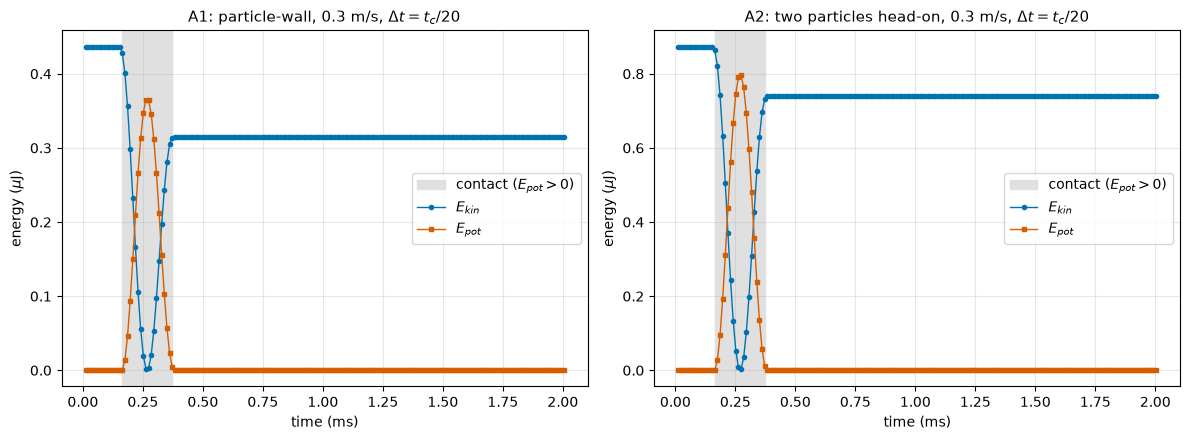

In [3]:
# Figure 1: E_kin and E_pot through one collision at 0.3 m/s, dt = t_c/20; contact = steps with E_pot > 0
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name, title in zip(axes, ["A1", "A2"], ["A1: particle-wall", "A2: two particles head-on"]):
    d = np.loadtxt(f"data/A_{name}_v0.3.dat")
    t, epot, ekin = d[:, 1] * 1e3, d[:, 3] * 1e6, d[:, 4] * 1e6      # ms, microjoule
    touching = np.flatnonzero(epot > 0)
    t0, t1 = t[touching[0]], t[touching[-1]]
    ax.axvspan(t0, t1, color="0.88", label="contact ($E_{pot}>0$)")
    ax.plot(t, ekin, "o-", ms=3, lw=1, color=BLUE, label="$E_{kin}$")
    ax.plot(t, epot, "s-", ms=3, lw=1, color=RED, label="$E_{pot}$")
    ax.set_xlabel("time (ms)")
    ax.set_ylabel("energy ($\\mu$J)")
    ax.set_title(f"{title}, 0.3 m/s, $\\Delta t=t_c/20$")
    ax.legend(loc="center right")
    print(f"{name}: contact {len(touching)} steps = {t1 - t0 + t[1] - t[0]:.3f} ms (t_c = 0.219 ms); E_kin before "
          f"{ekin[touching[0] - 1]:.3f} uJ, peak E_pot {epot.max():.3f} uJ")
plt.tight_layout()
plt.show()

**Figure 1.** One collision at 0.3 m/s: $E_\mathrm{kin}$ falls while $E_\mathrm{pot}$ rises and returns to 0. Left: A1, right: A2 (explained in [A2](#A2)).

- The contact lasts 20 steps $=0.219$ ms $=t_c$.
- $E_\mathrm{pot}$ peaks below $E_\mathrm{kin,before}$ (A1: 0.365 against 0.437 $\mu$J; A2: 0.797 against 0.874 $\mu$J) because the dashpot already takes energy on the way in.

<a id="A2"></a>

### A2 Two-particle collision (tabulated $e = 0.92$)

Files: same as [A1](#A1) (`NUM_TEST=2`); the numbers are in Table A.1 and Figure 1 (right).

Two particles head-on, each with the impact speed, otherwise as in A1 (same $e$ formula).

**Key numbers** at $\Delta t = t_c/20$:

- $e = 0.9194,\ 0.9199,\ 0.9193$ at 0.1, 0.3, 1.0 m/s, against the tabulated 0.92.
- Error $-0.01$ to $-0.07\,\%$; spread 0.0006.
- So the contact model gives back the restitution it was built from, for the wall and for the pair, and the same at every speed, as the linear model demands.

<a id="Adt"></a>

### Time step: how many steps per contact?

Files: [`run_a.sh`](code/run_a.sh), [`analyse_a.py`](code/analyse_a.py), [A_restitution.csv](data/A_restitution.csv); 24 runs, numbers in Tables A.2 and A.3.

The code takes $n = 20$ steps per contact (`DT_FRACTION` = 0.05):

$$\Delta t = \frac{t_c}{n}, \qquad t_c = \sqrt{\frac{m_\mathrm{eff}\,(\pi^2+\ln^2 e)}{k_n}}$$

where $m_\mathrm{eff}$ is the effective mass of the contact and $k_n$ the normal spring constant. We ran $n = 5, 10, 20, 40$ at 0.1, 0.3 and 1.0 m/s, for A1 and A2.

**Where $t_c$ comes from.** In the normal direction a contact is a linear spring and dashpot acting on the overlap $x$:

$$m_\mathrm{eff}\,\ddot x + \eta\,\dot x + k_n x = 0 \quad\Rightarrow\quad \ddot x + 2\beta\,\dot x + \omega_0^2 x = 0, \qquad \beta = \frac{\eta}{2m_\mathrm{eff}},\ \omega_0^2 = \frac{k_n}{m_\mathrm{eff}}$$

With $x(0)=0$, $\dot x(0)=v$ and weak damping ($\beta<\omega_0$) the solution is

$$x(t) = \frac{v}{\omega_d}\, e^{-\beta t} \sin(\omega_d t), \qquad \omega_d = \sqrt{\omega_0^2-\beta^2}$$

1. The particles separate when the overlap is back to zero, the first time $\sin(\omega_d t)=0$: $t_c = \pi/\omega_d$.
2. The rebound speed there is $\dot x(t_c) = -v\,e^{-\beta t_c}$, so $e = e^{-\beta\pi/\omega_d}$, i.e. $\beta/\omega_d = -\ln e/\pi$.
3. Insert this in $\omega_0^2 = \omega_d^2 + \beta^2 = \omega_d^2\,(1+\ln^2 e/\pi^2)$, so $\omega_d^2 = \omega_0^2\,\pi^2/(\pi^2+\ln^2 e)$.
4. Then $t_c = \pi/\omega_d = \sqrt{(\pi^2+\ln^2 e)/\omega_0^2}$, which is the formula above.

Step 2 also gives the dashpot: $\beta = -\ln e/t_c$, so $\eta = 2m_\mathrm{eff}\beta = -2\ln e\; m_\mathrm{eff}/t_c$ (used in [Wall against pair constants](#Awall)). So $e$ and $t_c$ are inputs, and $k_n$ and $\eta$ follow from them. The result does not depend on $v$ because the model is linear.

**Key numbers**

- **How many steps for 1 %?** From **10 steps** ($\Delta t=t_c/10$) all three speeds are within 1 % (largest error A1 0.90 %, A2 0.41 %). At 5 steps they are not (A1 up to 4.97 %, A2 up to 1.45 %). We did not test 6 to 9 steps, and 10 is marginal for A1.
- **Is $t_c/20$ enough?** For these three speeds yes: largest error 0.24 % (A1) and 0.07 % (A2). Careful: this is not a guarantee for every impact speed, see [the next block](#Aphase).
- **The error is not smooth in $\Delta t$.** A1 at 0.1 m/s: $-0.85\,\%$, $-0.22\,\%$, $+0.70\,\%$ for 10, 20, 40 steps. At 40 steps the spread over speed (A1: 0.0068) is *larger* than at 20 (0.0009).

In [4]:
# Tables A.2 and A.3: e and its error against impact speed and steps per contact (from data/A_restitution.csv)
w1, w2 = (res[res.num_test == k].set_index(["v_impact", "steps_per_contact"]) for k in (1, 2))
show_table("Table A.2: measured $e$ (tabulated 0.85 for A1, 0.92 for A2)",
           ["$v$ (m/s)", "steps per contact $n$", "A1 $e$", "A1 error (%)", "A1 phase $\\varphi$", "A2 $e$", "A2 error (%)"],
           [[f"{v:g}", n, f"{w1.e.loc[(v, n)]:.4f}", f"{100 * w1.rel_error.loc[(v, n)]:+.2f}", f"{w1.phase.loc[(v, n)]:.3f}",
             f"{w2.e.loc[(v, n)]:.4f}", f"{100 * w2.rel_error.loc[(v, n)]:+.2f}"] for v, n in w1.index])
rows = []
for n in (5, 10, 20, 40):
    g1, g2 = (res[(res.num_test == k) & (res.steps_per_contact == n)] for k in (1, 2))
    rows.append([n, f"{100 * g1.rel_error.abs().max():.2f}", f"{g1.e.max() - g1.e.min():.4f}",
                 f"{100 * g2.rel_error.abs().max():.2f}", f"{g2.e.max() - g2.e.min():.4f}"])
show_table("Table A.3: worst case over the three speeds",
           ["steps per contact $n$", "A1 max error (%)", "A1 spread of $e$", "A2 max error (%)", "A2 spread of $e$"], rows)

**Table A.2: measured $e$ (tabulated 0.85 for A1, 0.92 for A2)**

| $v$ (m/s) | steps per contact $n$ | A1 $e$ | A1 error (%) | A1 phase $\varphi$ | A2 $e$ | A2 error (%) |
|---|---|---|---|---|---|---|
| 0.1 | 5 | 0.8861 | +4.24 | 0.866 | 0.9266 | +0.71 |
| 0.1 | 10 | 0.8428 | -0.85 | 0.733 | 0.9166 | -0.37 |
| 0.1 | 20 | 0.8481 | -0.22 | 0.466 | 0.9194 | -0.06 |
| 0.1 | 40 | 0.8560 | +0.70 | 0.931 | 0.9196 | -0.04 |
| 0.3 | 5 | 0.8483 | -0.20 | 0.289 | 0.9241 | +0.45 |
| 0.3 | 10 | 0.8445 | -0.65 | 0.578 | 0.9178 | -0.24 |
| 0.3 | 20 | 0.8488 | -0.14 | 0.155 | 0.9199 | -0.01 |
| 0.3 | 40 | 0.8492 | -0.10 | 0.310 | 0.9198 | -0.02 |
| 1 | 5 | 0.8922 | +4.97 | 0.887 | 0.9333 | +1.45 |
| 1 | 10 | 0.8424 | -0.90 | 0.773 | 0.9163 | -0.41 |
| 1 | 20 | 0.8479 | -0.24 | 0.547 | 0.9193 | -0.07 |
| 1 | 40 | 0.8493 | -0.08 | 0.093 | 0.9199 | -0.02 |

**Table A.3: worst case over the three speeds**

| steps per contact $n$ | A1 max error (%) | A1 spread of $e$ | A2 max error (%) | A2 spread of $e$ |
|---|---|---|---|---|
| 5 | 4.97 | 0.0439 | 1.45 | 0.0092 |
| 10 | 0.90 | 0.0021 | 0.41 | 0.0015 |
| 20 | 0.24 | 0.0009 | 0.07 | 0.0006 |
| 40 | 0.70 | 0.0068 | 0.04 | 0.0002 |

<a id="Aphase"></a>

### Why the error is not smooth: the phase of the contact onset

Files: [`run_a_scan.sh`](code/run_a_scan.sh), [`analyse_a.py`](code/analyse_a.py), [A_phase_scan.csv](data/A_phase_scan.csv) (248 runs); numbers in Table A.4, Figure 2 and the two printed lines.

**Why: the force is switched on at full dashpot strength.** We printed the normal force of the first contact steps (temporary debug print in a scratch copy of the code, removed; the code in `code/` is unchanged).

- At the first step with overlap the dashpot force is always $\eta v$, the full approach speed, whatever the overlap: for 0.3 m/s and $t_c/20$ it is 4.3 mN against a spring force of only 1.0 mN (overlap $0.155\,v\Delta t$).
- At the last overlap step the dashpot force ($-3.7$ mN) is almost as large as the spring force (4.2 mN), and at the next step the whole force is gone.
- So the force *jumps* at both ends of the contact, and a grid of fixed $\Delta t$ samples that jump at an arbitrary moment. The surfaces touch at $t=0.05R/v$, which lies anywhere between two grid points.

We call **phase** $\varphi$ the fraction of a time step by which the first grid time with overlap lies after the first touch:

$$\varphi = \frac{\text{overlap at the first step with overlap}}{v\,\Delta t}$$

(formula in `analyse_a.py`, checked against the first overlap step of every run).

**Check that it fits.** The scan varies only the impact speed (31 values, 0.10 to 1.00 m/s, 4 time steps, A1 and A2). The exact $e$ does not depend on the speed, so $v$ acts only through $\varphi$.

- Figure 2: $e$ is a smooth, nearly linear function of $\varphi$ plus one jump. Where the contact loses one overlap step (e.g. 20 $\to$ 19 at $t_c/20$) the error jumps up (A1, $t_c/20$: $-0.32$ to $-0.11\,\%$ with 20 overlap steps, $+1.32$ to $+1.47\,\%$ with 19).
- All 24 runs of Table A.2 sit on these curves: the five runs with one overlap step fewer than $t_c/\Delta t$ have errors from $+0.70$ to $+4.97\,\%$, the other 19 runs lie between $-0.90$ and $+0.45\,\%$. Changing $\Delta t$ at fixed $v$ moves $\varphi$ around arbitrarily, hence no smooth convergence.

**Why the jump.** The simulation only sees the collision at the grid times, and the force acts only at grid times with overlap. A contact lasts a little less than $n$ steps, so depending on the phase the last grid time either still falls inside the contact or just misses it. That last sample matters: at the end of the contact the dashpot is still braking the separating particles, and the next step the force is gone. When the last sample is lost, one braking push is missing, the particles leave slightly faster, and $e$ jumps up. That push is about $1/n$ of the whole collision, so the jump shrinks with finer steps (A1: $7.8,\ 3.4,\ 1.6,\ 0.8\,\%$ for $n = 5,\ 10,\ 20,\ 40$).

**Consequence** (Table A.4). Over all scanned speeds at $t_c/20$ the error of $e$ lies between $-0.32$ and $+1.47\,\%$ (A1) and $-0.13$ and $+0.77\,\%$ (A2); the mean over phases is $+0.09\,\%$ and $-0.02\,\%$. A single collision can thus be off by more than 1 % (A1: 19 % of the speeds), but on average over random impact phases, as in a flow, $e$ is right. At 40 steps all scanned errors are below 0.8 %.

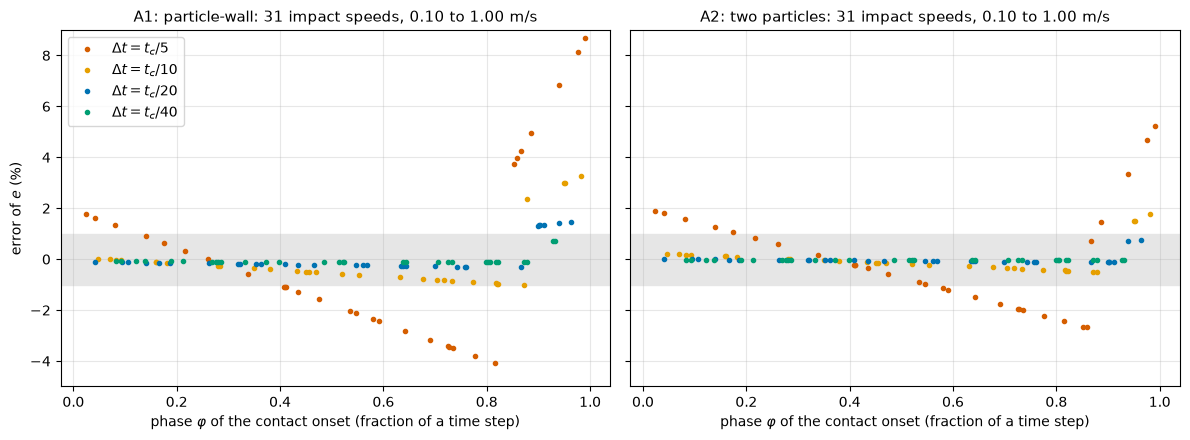

**Table A.4: error of $e$ over the 31 speeds**

| test | $n$ | min (%) | max (%) | mean (%) | share with error above 1 % |
|---|---|---|---|---|---|
| A1 | 5 | -4.09 | +8.70 | +0.24 | 84 % |
| A1 | 10 | -1.02 | +3.28 | -0.07 | 16 % |
| A1 | 20 | -0.32 | +1.47 | +0.09 | 19 % |
| A1 | 40 | -0.13 | +0.70 | -0.05 | 0 % |
| A2 | 5 | -2.68 | +5.22 | -0.01 | 65 % |
| A2 | 10 | -0.50 | +1.78 | +0.01 | 10 % |
| A2 | 20 | -0.13 | +0.77 | -0.02 | 0 % |
| A2 | 40 | -0.04 | -0.02 | -0.03 | 0 % |

A1, t_c/20, 20 overlap steps: phase 0.04 to 0.87, error -0.32 to -0.11 %
A1, t_c/20, 19 overlap steps: phase 0.90 to 0.96, error +1.32 to +1.47 %
24 runs: 5 with one overlap step fewer: +0.70 to +4.97 %; other 19: -0.90 to +0.45 %


In [5]:
# Figure 2 and Table A.4: error of e against the phase of the contact onset, 31 impact speeds (data/A_phase_scan.csv)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, k, title in zip(axes, [1, 2], ["A1: particle-wall", "A2: two particles"]):
    for frac, c in zip([0.2, 0.1, 0.05, 0.025], [RED, ORANGE, BLUE, GREEN]):
        g = scan[(scan.num_test == k) & (scan.dt_fraction == frac)]
        ax.plot(g.phase, 100 * g.rel_error, ".", color=c, label=f"$\\Delta t=t_c/{round(1 / frac)}$")
    ax.axhspan(-1, 1, color="0.9", zorder=0)
    ax.set_xlabel("phase $\\varphi$ of the contact onset (fraction of a time step)")
    ax.set_title(f"{title}: 31 impact speeds, 0.10 to 1.00 m/s")
    ax.set_ylim(-5, 9)
axes[0].set_ylabel("error of $e$ (%)")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

grp = scan.groupby(["num_test", "dt_fraction"]).rel_error
show_table("Table A.4: error of $e$ over the 31 speeds",
           ["test", "$n$", "min (%)", "max (%)", "mean (%)", "share with error above 1 %"],
           [[f"A{k}", round(1 / f), f"{100 * grp.min()[k, f]:+.2f}", f"{100 * grp.max()[k, f]:+.2f}", f"{100 * grp.mean()[k, f]:+.2f}",
             f"{100 * grp.apply(lambda x: (x.abs() > 0.01).mean())[k, f]:.0f} %"] for k in (1, 2) for f in (0.2, 0.1, 0.05, 0.025)])
g = scan[(scan.num_test == 1) & (scan.dt_fraction == 0.05)]
for m in (20, 19):
    h = g[g.steps_with_overlap == m]
    print(f"A1, t_c/20, {m} overlap steps: phase {h.phase.min():.2f} to {h.phase.max():.2f}, error {100 * h.rel_error.min():+.2f} to {100 * h.rel_error.max():+.2f} %")
short = res.steps_with_overlap < res.steps_per_contact
print(f"24 runs: {short.sum()} with one overlap step fewer: {100 * res[short].rel_error.min():+.2f} to {100 * res[short].rel_error.max():+.2f} %; "
      f"other {(~short).sum()}: {100 * res[~short].rel_error.min():+.2f} to {100 * res[~short].rel_error.max():+.2f} %")

<a id="Awall"></a>

### Wall against pair constants

Files: [`set_parameters`](code/setparameters.c) (`k_n_pw`, `eta_n_pw`, `k_n_pp`, `eta_n_pp`).

A wall acts as a particle of infinite mass, so a wall contact oscillates with the effective mass $m$ and a pair with the reduced mass $m/2$:

$$m_\mathrm{eff}^\mathrm{wall} = m, \qquad m_\mathrm{eff}^\mathrm{pair} = \frac{m}{2}$$

To get the same contact time $t_c$ the wall needs twice the stiffness ($k_\mathrm{pw}/k_\mathrm{pp}=2.00$). The dashpot also depends on the restitution (0.85 for the wall, 0.92 for the pair), so the wall dashpot is 3.9 times larger:

$$\eta = \frac{-2\ln e\; m_\mathrm{eff}}{t_c}$$

<details>
<summary><b>Oral prep</b> (click to open)</summary>

- **Q: Where do the spring and dashpot constants come from, and why is $\Delta t$ tied to $t_c$?**  
  A: In a contact the overlap is a damped harmonic oscillator; half its period is the contact time and the damping fixes $e=\exp(-\pi\gamma/\omega_d)$. [`set_parameters`](code/setparameters.c) runs this backwards: we choose $k_n=1000$ N/m, and with the prescribed $e$ it gives $t_c=\sqrt{m_\mathrm{eff}(\pi^2+\ln^2 e)/k_n}=0.219$ ms and $\eta=-2\ln e\,m_\mathrm{eff}/t_c$. The contact is the fastest process in the model and must be resolved, so $\Delta t=t_c/20$ (`DT_FRACTION`); our table shows 5 steps already give errors of 5 %.
- **Q: Why does recovering $e$ close the loop?**  
  A: $e$ is only an input to the constants; the run measures it independently from the energies, so getting 0.85 and 0.92 back (and the same at all speeds, as the linear model demands) shows that constants, force routine, integrator and time step agree with the analytic derivation. It does not test the tangential and friction part (no spin here), which later parts rely on.
- **Q: Why do wall and particle-particle collisions need different constants?**  
  A: Same $t_c$ but different effective mass (wall: $m$, pair: $m/2$), so the wall spring is twice as stiff; and different $e$ (0.85 against 0.92), so the dashpot differs (3.9 times larger for the wall). See `k_n_pw`, `eta_n_pw` and `k_n_pp`, `eta_n_pp` in `set_parameters`.

</details>

## Part B: Validation, granular slope stability

*In the oral you should be able to:* explain why rotating gravity is
equivalent to tilting the floor; explain the angle you found from the
way the particles move; explain what static friction requires of the
contact model, and what would happen to this test without the stored
tangential displacement.

The bed of the starting code (2000 particles, about five layers on the
flat bottom wall, periodic sides) settles under vertical gravity until
$t_\mathrm{tilt} = 0.3$ s. Then gravity rotates about the $y$ axis at a
constant rate, which tilts the bed without moving any wall. Write
`update_parameters` (`RUN=2`).

**Before you run, predict:** if the bed slides over the floor as one
block, at which angle does it start to move? (Only one friction
coefficient matters for that.)

Deliver:

- a **figure** of $E_\mathrm{kin}$ (log scale) against slope angle, for
  the two tilt rates of the run table on one plot, with the onset angle
  $\theta_c$ marked. The kinetic energy creeps up before the bed really
  goes: define your onset (for example the angle where $E_\mathrm{kin}$
  passes $10^{-6}$ J, a mean speed of about 1 cm/s) and state the
  definition;
- a **number**: $\theta_c$, and whether it depends on the tilt rate;
- a **comparison** with your prediction.

Do not be alarmed if the bed fails far below your prediction: that is
the point of this task, not an error in your code. Find out why. Take a
frame of the trajectory at a slope of about 20° and compare the mean
speed of the bottom layer (centres less than 2 mm above the floor) with
the mean speed of the particles above it. What ratio would you expect if
the bottom layer rolled, without slipping, under a bed that slides over
it? What does your measured ratio say about how the bed fails, and why is
the friction coefficient then not what sets $\theta_c$?

In [6]:
# Part B setup: imports, figure style, data, helpers (no output)
import re
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler
from IPython.display import Markdown, display

BLUE, RED, GREEN, ORANGE = "#0072B2", "#D55E00", "#009E73", "#E69F00"   # colour-blind-safe; same colours in all parts
plt.rcParams.update({"figure.figsize": (8, 4.5), "font.size": 10, "axes.titlesize": 11, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.prop_cycle": cycler(color=[BLUE, RED, GREEN, ORANGE])})


def show_table(title, header, rows):
    """Show a captioned markdown pipe table (LaTeX is allowed in the header and in the cells)."""
    lines = [f"**{title}**", "", "| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


T_TILT, E_ONSET = 0.3, 1e-6                 # s; onset threshold on E_kin in J
MU_W = 0.45                                 # particle-wall friction coefficient of the model table
runs = {20: "data/B_rate20.dat", 10: "data/B_rate10.dat"}   # tilt rate in deg/s -> table of the run
colour = {20: BLUE, 10: RED}


def onset_angle(rate, t, ekin, thr=E_ONSET):
    """Angle rate*(t - t_tilt) at the first table line after t_tilt with E_kin > thr."""
    i = np.argmax((t > T_TILT) & (ekin > thr))
    return rate * (t[i] - T_TILT)


tab, theta_c = {}, {}
for rate, path in runs.items():
    d = np.loadtxt(path)                    # columns: step time Z Epot Ekin Etot N_silo
    tab[rate] = (d[:, 1], d[:, 4])
    theta_c[rate] = onset_angle(rate, *tab[rate])
sens = {r: [onset_angle(r, *tab[r], thr) for thr in (5e-7, 1e-6, 2e-6)] for r in runs}
theta_pred = np.degrees(np.arctan(MU_W))

# frame at about 20 degrees: x y z radius speed (z = 0 is the floor)
with open("data/B_frame_20deg.dat") as f:
    t_frame = float(re.search(r"at t = (\S+) s", f.readline()).group(1))
z, speed = np.loadtxt("data/B_frame_20deg.dat", usecols=(2, 4)).T
angle_frame = 20 * (t_frame - T_TILT)
bottom = z < 2e-3                           # centres less than 2 mm above the floor
v_bot, v_up = speed[bottom].mean(), speed[~bottom].mean()

<a id="B0"></a>

### B0 Prediction (written before any run)

Files: [`update_parameters`](code/setparameters.c) (RUN_SLOPE branch); the predicted angle is drawn in Figure B1.

If the whole bed slides as one block over the floor, the force balance along the slope gives

$$m g\sin\theta = \mu\, m g\cos\theta \qquad\Rightarrow\qquad \tan\theta_c = \mu$$

**Which $\mu$.** The surface that slips is bottom layer against floor, so $\mu$ is the **particle-wall** friction coefficient of the model table, $\mu_w = 0.45$:

$$\theta_c = \arctan \mu_w = \arctan 0.45 = 24.2^\circ$$

The particle-particle value 0.50 ($26.6^\circ$) would only matter if two layers of the bed slid over each other; in a rigid block the particle-particle contacts do not slip.

**Note.** The ramp of the run ends at $24^\circ$, just below $24.2^\circ$: if the bed behaved like this block, it would not have started to move in our run.

<a id="B1"></a>

### B1 Onset angle

Files: [`update_parameters`](code/setparameters.c), [B_rate20.dat](data/B_rate20.dat), [B_rate10.dat](data/B_rate10.dat); numbers in Table B.1 and Figure B1.

The bed settles under vertical gravity until $t_\mathrm{tilt} = 0.3$ s, then gravity rotates about the $y$ axis at the constant rate $\dot\theta$ (20 °/s and 10 °/s). Rotating $\mathbf g$ tilts the bed without moving any wall:

$$\theta = \dot\theta\,(t - t_\mathrm{tilt}), \qquad \mathbf g = g\,(\sin\theta,\ 0,\ -\cos\theta)$$

**Definition of the onset.** The kinetic energy creeps up before the bed really goes, so we fix a threshold: $t_\mathrm{onset}$ is the first table line after $t_\mathrm{tilt}$ with $E_\mathrm{kin} > 10^{-6}$ J (about 1 cm/s mean speed), and

$$\theta_c = \dot\theta\,(t_\mathrm{onset} - t_\mathrm{tilt})$$

The settled bed has $E_\mathrm{kin} = 2.9\times10^{-8}$ J at $t_\mathrm{tilt}$, well below the threshold.

**Key numbers** (Table B.1)

- $\theta_c = 11.7^\circ$ at 20 °/s and $12.1^\circ$ at 10 °/s. Thresholds of $5\times10^{-7}$ to $2\times10^{-6}$ J move each by $-0.5^\circ/+0.6^\circ$. So **$\theta_c \approx 12^\circ \pm 0.6^\circ$** (syst., threshold).
- **Rate dependence.** The 10 °/s run starts $0.4^\circ$ later (+0.37, +0.37, +0.31° at the three thresholds): the same sign each time, but the size of the threshold effect, and we have one run per rate. So at most a 3 % effect; we do not claim more. Between $10^\circ$ and $15^\circ$ the two curves lie nearly on top of each other.
- **Where the rise starts.** $E_\mathrm{kin}$ leaves its noise floor at 9 to $10^\circ$ ($10^{-7}$ J is passed at $10.4^\circ$ and $10.1^\circ$); the definition fixes the number, not the shape.

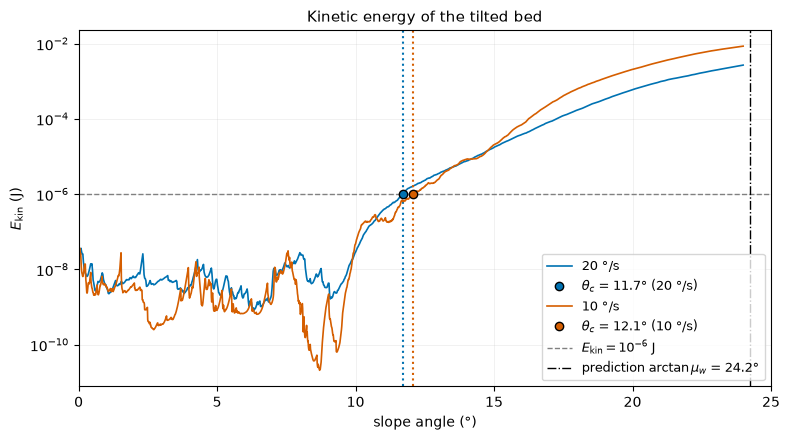

**Table B.1: onset angle $\theta_c$ (°) for several thresholds on $E_\mathrm{kin}$**

| tilt rate | $5\times10^{-7}$ J | $10^{-6}$ J (definition) | $2\times10^{-6}$ J | $10^{-7}$ J |
|---|---|---|---|---|
| 20 °/s | 11.23 | 11.71 | 12.32 | 10.38 |
| 10 °/s | 11.60 | 12.08 | 12.63 | 10.12 |

prediction: arctan(0.45) = 24.2°, arctan(0.50) = 26.6°; the ramp ends at 24°
10 °/s minus 20 °/s:+0.37, +0.37, +0.31 ° at 1e-6, 5e-7, 2e-6 J; E_kin at t_tilt: 2.9e-08 J


In [7]:
# Figure B1 and Table B.1: E_kin against slope angle for both tilt rates, onset angle for several thresholds
fig, ax = plt.subplots()
for rate in runs:
    t, ek = tab[rate]
    m = t >= T_TILT
    ax.semilogy(rate * (t[m] - T_TILT), ek[m], color=colour[rate], lw=1.2, label=f"{rate} °/s")
    ax.axvline(theta_c[rate], color=colour[rate], ls=":", lw=1.5)
    ax.plot(theta_c[rate], E_ONSET, "o", color=colour[rate], mec="k", zorder=5,
            label=rf"$\theta_c$ = {theta_c[rate]:.1f}° ({rate} °/s)")
ax.axhline(E_ONSET, color="grey", ls="--", lw=1, label=r"$E_\mathrm{kin}=10^{-6}$ J")
ax.axvline(theta_pred, color="k", ls="-.", lw=1, label=rf"prediction $\arctan\mu_w$ = {theta_pred:.1f}°")
ax.set_xlim(0, 25)
ax.set_xlabel("slope angle (°)")
ax.set_ylabel(r"$E_\mathrm{kin}$ (J)")
ax.set_title("Kinetic energy of the tilted bed")
ax.legend(fontsize=9, loc="lower right")
ax.grid(alpha=0.3, which="both", lw=0.4)
plt.tight_layout()
plt.show()

show_table("Table B.1: onset angle $\\theta_c$ (°) for several thresholds on $E_\\mathrm{kin}$",
           ["tilt rate", "$5\\times10^{-7}$ J", "$10^{-6}$ J (definition)", "$2\\times10^{-6}$ J", "$10^{-7}$ J"],
           [[f"{r} °/s", f"{sens[r][0]:.2f}", f"{sens[r][1]:.2f}", f"{sens[r][2]:.2f}", f"{onset_angle(r, *tab[r], 1e-7):.2f}"] for r in runs])
print(f"prediction: arctan({MU_W}) = {theta_pred:.1f}°, arctan(0.50) = {np.degrees(np.arctan(0.5)):.1f}°; the ramp ends at 24°")
print(f"10 °/s minus 20 °/s:{sens[10][1] - sens[20][1]:+.2f}, {sens[10][0] - sens[20][0]:+.2f}, {sens[10][2] - sens[20][2]:+.2f} ° "
      f"at 1e-6, 5e-7, 2e-6 J; E_kin at t_tilt: {tab[20][1][tab[20][0] <= T_TILT][-1]:.1e} J")

**Figure B1.** $E_\mathrm{kin}$ against slope angle for both tilt rates. Dots and dotted vertical lines: $\theta_c$ of each rate, where its curve crosses the dashed $10^{-6}$ J threshold. Dash-dotted: the block prediction $24.2^\circ$ from [B0](#B0), far to the right of both onsets.

<a id="B2"></a>

### B2 Comparison with the prediction

$\theta_c \approx 12^\circ$ is **half** of the predicted $24.2^\circ$ ($\tan 12^\circ = 0.21$, against $\mu_w = 0.45$). A block sliding on the floor would not have moved at all within our $24^\circ$ ramp, so the bed does not fail that way. The next block says how it does fail.

<a id="B3"></a>

### B3 Bottom layer at $19.8^\circ$

Files: [`extract_frame.py`](code/extract_frame.py), [B_frame_20deg.dat](data/B_frame_20deg.dat) (frame at $t = 1.292$ s of the 20 °/s run; $z = 0$ is the floor, the lowest centre is at 0.97 mm, one radius); numbers in Table B.2 and Figure B3.

We compare the mean speed of the bottom layer (centres less than 2 mm above the floor) with that of the particles above it. If the bottom layer rolls without slipping, its contact point with the floor is at rest, so the top of a sphere moves at twice its centre speed $v_c$. A bed carried on the tops moves at $2v_c$:

$$\frac{\bar v_\mathrm{bottom}}{\bar v_\mathrm{above}} = \frac{v_c}{2\,v_c} = 0.5 \quad (\mathrm{rolling}), \qquad \frac{\bar v_\mathrm{bottom}}{\bar v_\mathrm{above}} = 1 \quad (\mathrm{bed\ sliding\ over\ the\ floor})$$

**Key numbers** (Table B.2)

- **Measured.** Bottom layer: 361 particles, mean speed 0.137 m/s. Above: 1639 particles, 0.240 m/s. Both have a spread (std) of 0.017 m/s. **Ratio 0.57** (0.57, 0.57, 0.58 for cuts at 1.5, 2.0, 2.5 mm).
- **Above the layer** the speed is nearly uniform: 0.233 to 0.250 m/s in 1 mm slices, +7 % over 8 mm. The upper bed moves as one block.

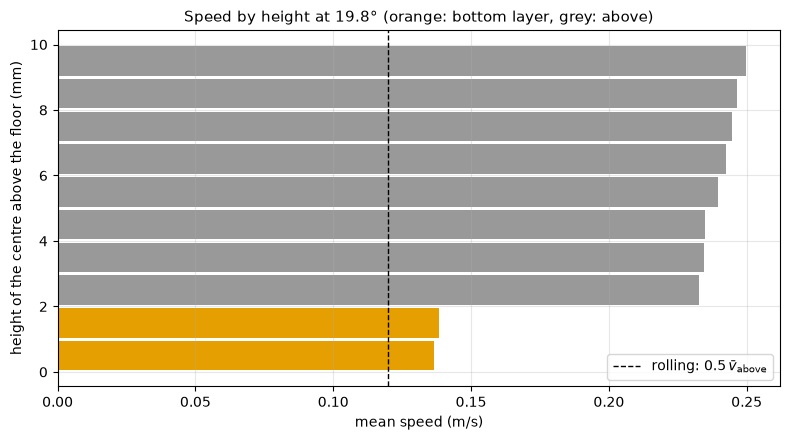

**Table B.2: frame at $t$ = 1.2917 s, slope 19.83°, 2000 particles**

| group | particles | mean speed (m/s) | std (m/s) |
|---|---|---|---|
| bottom layer ($z<2$ mm) | 361 | 0.1374 | 0.017 |
| above | 1639 | 0.2397 | 0.017 |

ratio bottom/above = 0.574 (rolling 0.5, sliding 1); cuts at 1.5, 2.0, 2.5 mm: 0.574, 0.574, 0.584
mean speed in 1 mm slices above 2 mm: 0.233 to 0.250 m/s (+7 %)


In [8]:
# Figure B3 and Table B.2: speed by height in the frame at 19.8 degrees, bottom layer against the bed above it
edges = np.arange(0, 10.5e-3, 1e-3)         # speed profile in 1 mm height slices
mid = 0.5 * (edges[:-1] + edges[1:]) * 1e3
prof = np.array([speed[(z >= a) & (z < b)].mean() if ((z >= a) & (z < b)).any() else np.nan for a, b in zip(edges[:-1], edges[1:])])
fig, ax = plt.subplots()
ax.barh(mid, prof, height=0.9, color=np.where(mid < 2, ORANGE, "#999999"))
ax.axvline(0.5 * v_up, color="k", ls="--", lw=1, label=r"rolling: $0.5\,\bar v_\mathrm{above}$")
ax.set_xlabel("mean speed (m/s)")
ax.set_ylabel("height of the centre above the floor (mm)")
ax.set_title(f"Speed by height at {angle_frame:.1f}° (orange: bottom layer, grey: above)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

show_table(f"Table B.2: frame at $t$ = {t_frame:.4f} s, slope {angle_frame:.2f}°, {len(z)} particles",
           ["group", "particles", "mean speed (m/s)", "std (m/s)"],
           [["bottom layer ($z<2$ mm)", bottom.sum(), f"{v_bot:.4f}", f"{speed[bottom].std():.3f}"],
            ["above", (~bottom).sum(), f"{v_up:.4f}", f"{speed[~bottom].std():.3f}"]])
print(f"ratio bottom/above = {v_bot / v_up:.3f} (rolling 0.5, sliding 1); cuts at 1.5, 2.0, 2.5 mm: "
      + ", ".join(f"{speed[z < c].mean() / speed[z >= c].mean():.3f}" for c in (1.5e-3, 2.0e-3, 2.5e-3)))
print(f"mean speed in 1 mm slices above 2 mm: {np.nanmin(prof[2:10]):.3f} to {np.nanmax(prof[2:10]):.3f} m/s "
      f"(+{100 * (np.nanmax(prof[2:10]) / np.nanmin(prof[2:10]) - 1):.0f} %)")

**Figure B3.** Mean speed in 1 mm slices of the height of the centre. The bottom layer (orange, below 2 mm) is much slower than the bed above and close to the rolling value (dashed line: half of the speed above).

- **What the ratio says.** 0.57 is close to 0.5 and far from 1: the bottom layer rolls on the floor and the bed above rides on it. A little more than 0.5 is plausible, since the bed above touches the spheres off their tops. *Hypothesis, untested:* the off-top contact. The trajectory file has no spins, so rolling is inferred from the speeds.
- **Why $\mu$ does not set $\theta_c$.** $\tan\theta = \mu_w$ needs the floor contacts to slide, i.e. to reach the Coulomb cap $\mu_w F_n$. A rolling contact point is at rest: static friction only holds it, below the cap. The contact model has no rolling resistance, and a single sphere with static friction rolls down a slope at any angle. So the finite $\theta_c$ must come from the spheres around it, i.e. from the packing and not from $\mu_w$. *Hypothesis, untested:* we did not vary $\mu_w$; this is what fits the data, not a tested result.

<details>
<summary><b>Oral prep</b> (click to open)</summary>

- **Q:** Why is rotating gravity equivalent to tilting the floor?  
  **A:** Contact forces depend only on relative positions and velocities, so only the direction of $\mathbf g$ relative to the floor matters: along the floor $g\sin\theta$, normal to it $g\cos\theta$, in both pictures. We set $\mathbf g = g(\sin\theta, 0, -\cos\theta)$ in [`update_parameters`](code/setparameters.c). The sides are periodic, so there are no side walls to move, and the floor stays the plane $z = 0$. Rotating $\mathbf g$ in a fixed frame also adds no fictitious forces.
- **Q:** Explain the angle you found from the way the particles move.  
  **A:** We find $\theta_c \approx 12^\circ$, half of $\arctan\mu_w = 24.2^\circ$. At $19.8^\circ$ the bottom layer moves at 0.57 of the speed of the bed above it (0.137 against 0.240 m/s): near the rolling value 0.5, far from 1. The bottom layer rolls and the bed rides on it, so the floor contacts do not slide and $\mu_w$ does not set the onset.
- **Q:** What does static friction require of the contact model, and what would happen to this test without it?  
  **A:** A tangential spring acting on a displacement stored per contact, kept for as long as the contact lasts (neighbour list in [`nbrlist.c`](code/nbrlist.c), used in [`calculate_forces_pp` and `_pw`](code/forces.c)), so the force is nonzero at rest, plus the Coulomb cap $|F_t| \le \mu |F_n|$ that switches from sticking to sliding. Without the stored displacement friction would only act on the sliding speed: zero for a bed at rest, so the bed could not be held and would creep at any angle.

</details>

## Part C: Building the silo

*In the oral you should be able to:* state the wall-function contract and
walk through your cylinder implementation and your edge of the hole,
including why your point is the closest one; explain why the fill needs no separate randomisation; interpret
your packing profile and the bulk density you use for Beverloo.

All of Part C runs inside the one silo run of the run table (`RUN=3`,
$D = 7\,d_p$): the fill settles on the closed plate until
$t_\mathrm{open} = 0.3$ s, after which the orifice opens. Parts C3 and C4
use the part before $t_\mathrm{open}$, Part D the part after.

### C1) Cylindrical wall

Write `cylinder_wall`. The contract (overlap test, $\mathbf{r}_{iw}$
from the closest wall point to the particle centre, $\mathbf{v}_w$) is
documented at the top of `walls.c`; compare with `bottom_wall`.

### C2) Bottom plate with a circular orifice

The flat plate is given in `silo_bottom_wall`; it shows the wall contract
at work. What is missing is the **edge of the hole**: a particle whose
centre is over the open hole, but within one radius of the plane of the
plate, can still touch the plate where the hole begins. Work out which
point of the plate is then closest to the particle centre, and complete
`silo_bottom_wall` with that contact. Open the orifice at
$t_\mathrm{open}$ in `update_parameters`.

Deliver, in the results cell: the **closest wall point** and
$\mathbf{r}_{iw}$ for a centre over the hole, as a formula, with a
sketch or one sentence that shows why it is the closest point; and how
you convinced yourself that your implementation is right. Without the
edge the code still runs and the silo still empties: say what a particle
at the edge of the hole would do then.

### C3) Filling and settling

Write `initialise_positions_silo`: a loose lattice clipped to the
cylinder, as the `\todo` describes. Gravity and the closed plate do the
rest.

Deliver a **figure** of $E_\mathrm{kin}$ and the coordination number
$Z$ against time for $t < t_\mathrm{open}$, showing that the fill has
come to rest before the orifice opens, and a **snapshot** of the settled
bed (OVITO, sliced).

### C4) The packing

From the last trajectory frame before $t_\mathrm{open}$, deliver:

- a **number**: the bulk solids volume fraction $\phi$ and the bulk
  density $\rho_b = \phi \rho_p$, which you need for Beverloo. Use a core
  region away from the walls: centres closer than $R_\mathrm{cyl} - 2d_p$
  to the axis, and between $2d_p$ above the plate and $3d_p$ below the
  highest particle. $\phi$ is the summed volume of the particles whose
  centre is in the core, divided by the core volume;
- a **number**: the coordination number $Z$ of the settled packing (the
  table has it);
- a **figure** of the radial profile of the particle centres: the number
  of centres per volume in thin cylindrical shells (0.2 mm) over the core
  height, times the mean particle volume. Near the wall this is *not* a
  local volume fraction, and it can exceed 0.74: the centres of a layer
  of spheres against a wall all sit at one distance from it.

Then discuss: why does the profile oscillate near the wall, and over how
many particle diameters? What does that imply for how wide a silo has to
be, compared with its orifice?

In [9]:
# Part C setup: imports, figure style, data of the silo run and of the last frame before t_open, helpers (no output)
import re
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler
from IPython.display import Image, Markdown, display
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.spatial import cKDTree
from scipy.stats import chi2 as chi2_dist

BLUE, RED, GREEN, ORANGE = "#0072B2", "#D55E00", "#009E73", "#E69F00"   # colour-blind-safe; edge on = blue, edge off = red
plt.rcParams.update({"figure.figsize": (8, 4.5), "font.size": 10, "axes.titlesize": 11, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.prop_cycle": cycler(color=[BLUE, RED, GREEN, ORANGE])})


def show_table(title, header, rows):
    """Show a captioned markdown pipe table (LaTeX is allowed in the header and in the cells)."""
    lines = [f"**{title}**", "", "| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


# the table of the silo run (D = 7 d_p) and the last frame before t_open
header = open("data/D7.dat").readline()
par = lambda key: float(re.search(key + r"\s+(\S+)", header).group(1))
R_cyl, z_silo, t_open, R_o = par("R_cyl"), par("z_silo"), par("t_open"), par("R_orifice")
axis = 0.5 * par("box")                   # the box is square, the axis is in its middle
d_p, rho_p = 2.0e-3, 2500.0               # mean particle diameter 2.0 mm (task text), particle density
tab = np.loadtxt("data/D7.dat")           # step, time, Z, Epot, Ekin, Etot, N_silo
t, Z, Ekin, Nsilo = tab[:, 1], tab[:, 2], tab[:, 4], tab[:, 6]
pre = t < t_open
k_open = np.flatnonzero(pre)[-1]          # last table line before t_open
t_frame = float(re.search(r"t = (\S+) s", open("data/C_frame_before_open.dat").readline()).group(1))
x, y, z, R, speed = np.loadtxt("data/C_frame_before_open.dat").T
rc = np.hypot(x - axis, y - axis)         # distance of the centres to the axis
Vp = 4.0 / 3.0 * np.pi * R**3             # particle volumes
z_top = z.max()                           # the highest particle centre


def core(m_r=2.0, m_lo=2.0, m_hi=3.0):
    """phi in the core: centres closer than R_cyl - m_r d_p to the axis, between z_silo + m_lo d_p and z_top - m_hi d_p."""
    r_max, z_lo, z_hi = R_cyl - m_r * d_p, z_silo + m_lo * d_p, z_top - m_hi * d_p
    sel = (rc < r_max) & (z > z_lo) & (z < z_hi)
    V = np.pi * r_max**2 * (z_hi - z_lo)
    return Vp[sel].sum() / V, sel, V, r_max, z_lo, z_hi


phi, sel, V_core, r_max, z_lo, z_hi = core()
rho_b = phi * rho_p
ang = np.arctan2(y - axis, x - axis)
phi_sector = np.array([Vp[sel & (ang >= -np.pi + k * np.pi / 2) & (ang < -np.pi / 2 + k * np.pi / 2)].sum() / (V_core / 4) for k in range(4)])
phi_stat = phi_sector.std(ddof=1) / 2     # statistical error: standard error of the four azimuthal quarters

<a id="C1"></a>

### C1 Cylindrical wall

Files: [`cylinder_wall`](code/walls.c), [`wall_check.c`](code/tests/wall_check.c), [C_wall_check.txt](data/C_wall_check.txt); the check below covers C1 and the edge of C2.

All of Part C uses the silo run of the run table (`RUN=3`, $D = 7\,d_p$): the fill settles on the closed plate until $t_\mathrm{open} = 0.3$ s, after which the orifice opens. C3 and C4 use the part before $t_\mathrm{open}$, Part D the part after.

**The wall contract** (top of `walls.c`). A wall function returns true if the sphere overlaps the wall, and then sets the vector from the closest wall point to the particle centre, and the wall velocity there:

$$\mathbf r_{iw} = \mathbf r - \mathbf r_w, \qquad \mathrm{overlap} = R - |\mathbf r_{iw}|$$

where $\mathbf r$ is the centre, $\mathbf r_w$ the closest wall point and $R$ the radius. [`forces.c`](code/forces.c) takes overlap, normal $\mathbf r_{iw}/|\mathbf r_{iw}|$ and $\mathbf v - \mathbf v_w$ from it and knows nothing else of the wall.

**Cylinder.** Above the plate only: contact if $r_c > R_\mathrm{cyl} - R$, where $r_c$ is the distance of the centre to the axis. The closest point is at the same height and azimuth on the cylinder:

$$\mathbf r_{iw} = (r_c - R_\mathrm{cyl})\,\mathbf e_r, \qquad \mathbf v_w = 0$$

so $\mathbf r_{iw}$ is horizontal and points inwards. The axis never passes the test, so $1/r_c$ is never evaluated.

**Checked** against a brute-force closest point ([`wall_check.c`](code/tests/wall_check.c), details in [C_wall_check.txt](data/C_wall_check.txt)): random particles near the cylinder, near the rim and the axis of the hole (three hole sizes), and below the plate. Same contact flag, $\mathbf r_{iw}$ continuous across the rim, closed and outer plate exactly flat. Very near the axis a search cannot resolve the azimuth, so only $|\mathbf r_{iw}|$ is compared there.

In [10]:
# C1/C2: summary of the numerical check of walls.c (tests/wall_check.c; the full output is data/C_wall_check.txt)
txt = open("data/C_wall_check.txt").read()
tests = [l for l in txt.splitlines() if re.search(r"\bn=\s*\d+", l)]
count = lambda key: sum(int(re.search(key + r"=\s*(\d+)", l).group(1)) for l in tests)
dev = max(float(m) for m in re.findall(r"max\|riw-brute\|=(\S+) R", txt))
print(next(l for l in txt.splitlines() if "CHECKS" in l))
print(f"{len(tests)} test lines, {count('n')} random particles: flag mismatches {count('flag mismatches')}, "
      f"not-closest {count('not-closest')}, NaN/vw errors {count('NaN/vw errors')}")
print(f"largest |r_iw - brute force| = {dev:.1e} R; flat-plate checks (closed, open): "
      + ", ".join(re.search(r"deviations from the flat plane = (\d+)", l).group(1) for l in txt.splitlines() if "flat plane" in l and "plate" in l))

ALL CHECKS PASSED (0 failed checks)
8 test lines, 685455 random particles: flag mismatches 0, not-closest 0, NaN/vw errors 0
largest |r_iw - brute force| = 9.7e-08 R; flat-plate checks (closed, open): 0, 0


**Result of the check.** 685 455 random particles in the eight comparison lines, 0 mismatches of the contact flag, 0 points where the code's point was not the closest, $\mathbf r_{iw}$ within $10^{-7}$ radii of the brute-force point; 0 deviations in the flat-plate checks.

<a id="C2"></a>

### C2 Bottom plate with a circular orifice: the edge of the hole

Files: [`silo_bottom_wall`](code/walls.c); `orifice_open = 1` from $t_\mathrm{open}$ in [`update_parameters`](code/setparameters.c); check: [`wall_check.c`](code/tests/wall_check.c), [C_wall_check.txt](data/C_wall_check.txt) (see C1).

A particle with $r_c < R_\mathrm{orifice}$ over the open hole, within one radius of the plane of the plate ($|z - z_\mathrm{silo}| < R$), can still touch the plate where the hole begins. The plate is the half-plane $z = z_\mathrm{silo}$, $r_c' \ge R_\mathrm{orifice}$. The closest plate point is the rim point in the particle's azimuth,

$$P = (\mathrm{axis} + R_\mathrm{orifice}\,\mathbf e_r,\ z_\mathrm{silo})$$

so that

$$\mathbf r_{iw} = \mathbf r - P = \big((r_c - R_\mathrm{orifice})\,\mathbf e_r,\ z - z_\mathrm{silo}\big), \qquad r_{iw}^2 = (R_\mathrm{orifice} - r_c)^2 + (z - z_\mathrm{silo})^2 .$$

Contact if $r_{iw} < R$; $\mathbf v_w = 0$.

**Why this is the closest point** (sketch below). All plate points have the same vertical distance. The horizontal distance from the centre (at distance $r_c$ from the axis) to a plate point at $r_c' \ge R_\mathrm{orifice}$ is bounded by the triangle inequality:

$$|\mathbf r_c - \mathbf r_c'| \ \ge\ |\mathbf r_c'| - |\mathbf r_c| \ \ge\ R_\mathrm{orifice} - r_c$$

with equality only at the rim in the same azimuth. On the axis all rim points are equally close; the code takes $\hat{\mathbf x}$.

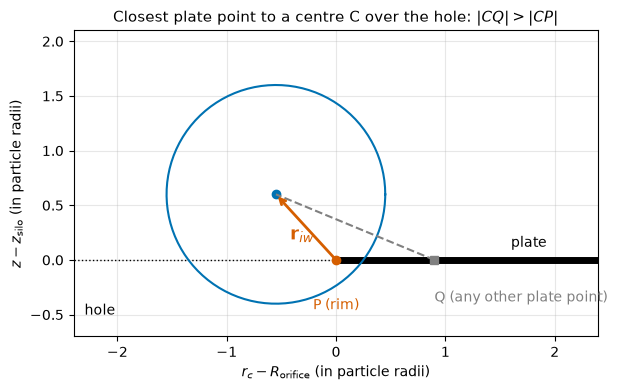

In [11]:
# C2: sketch of the closest plate point (cross-section through the axis, lengths in particle radii)
fig, ax = plt.subplots(figsize=(7, 4))
C, P, Q = np.array([-0.55, 0.6]), np.array([0.0, 0.0]), np.array([0.9, 0.0])
phi_ = np.linspace(0, 2 * np.pi, 200)
ax.plot([0, 2.4], [0, 0], "k-", lw=5, solid_capstyle="butt")
ax.plot([-2.4, 0], [0, 0], "k:", lw=1)
ax.plot(C[0] + np.cos(phi_), C[1] + np.sin(phi_), color=BLUE)
ax.plot(*C, "o", color=BLUE)
ax.annotate("", xy=C, xytext=P, arrowprops=dict(arrowstyle="->", color=RED, lw=2))
ax.plot(*P, "o", color=RED)
ax.plot([Q[0], C[0]], [Q[1], C[1]], "--", color="gray")
ax.plot(*Q, "s", color="gray")
ax.text(-0.42, 0.18, r"$\mathbf{r}_{iw}$", color=RED, fontsize=13)
ax.text(0.0, -0.45, "P (rim)", color=RED, fontsize=10, ha="center")
ax.text(0.9, -0.38, "Q (any other plate point)", color="gray", fontsize=10, ha="left")
ax.text(-2.3, -0.5, "hole", fontsize=10)
ax.text(1.6, 0.12, "plate", fontsize=10)
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-0.7, 2.1)
ax.set_aspect("equal")
ax.set_xlabel(r"$r_c - R_\mathrm{orifice}$ (in particle radii)")
ax.set_ylabel(r"$z - z_\mathrm{silo}$ (in particle radii)")
ax.set_title("Closest plate point to a centre C over the hole: $|CQ| > |CP|$")
plt.tight_layout()
plt.show()

**Figure C2a.** The centre C (blue circle: the particle) over the hole. The red arrow $\mathbf r_{iw}$ points from the rim point P to C; any other plate point Q is farther away.

**Without the edge** (what a particle at the edge of the hole would do). A centre with $r_c < R_\mathrm{orifice}$ falls through even while the sphere overlaps the plate: the centres may use radius $R_\mathrm{orifice}$ instead of $R_\mathrm{orifice} - R$, and the silo empties too fast. We measured how much too fast with the edge switched off in a scratch copy of `walls.c` ([`run_c_noedge.sh`](code/run_c_noedge.sh), [`run_c_seeds.sh`](code/run_c_seeds.sh), [`analyse_c.py`](code/analyse_c.py), [C_edge_seeds.csv](data/C_edge_seeds.csv)), for five seeds (12345 is the shipped one; a seed changes the radii and the shifts of the lattice sites). $Q$ is in particles/s as defined in [D2](#D2). For each seed $s$ the ratio is

$$R_s = \frac{Q_{\mathrm{no\ edge},\,s}}{Q_{\mathrm{edge},\,s}}$$

and we quote the mean and the standard deviation over the five seeds (Table C.1).

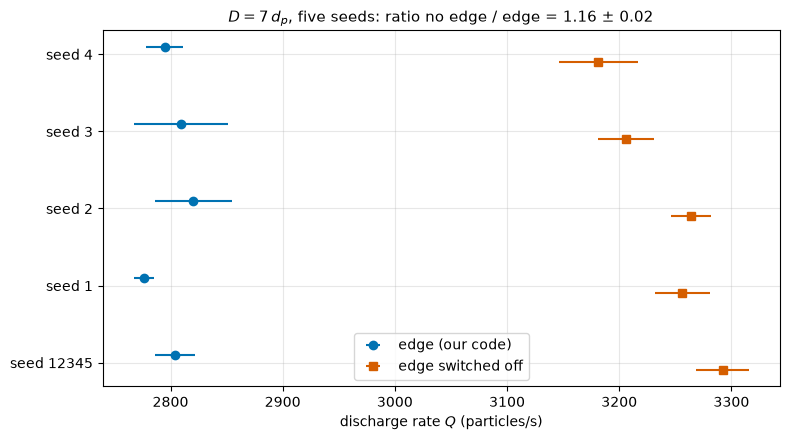

**Table C.1: $Q$ (particles/s) of the five seeds, window 10 % to 60 % gone**

| seed | $Q$ edge | $Q$ no edge | ratio $R_s$ |
|---|---|---|---|
| 12345 | 2804 ± 18 | 3292 ± 24 | 1.174 ± 0.011 |
| 1 | 2776 ± 9 | 3256 ± 25 | 1.173 ± 0.010 |
| 2 | 2820 ± 35 | 3264 ± 18 | 1.157 ± 0.016 |
| 3 | 2809 ± 42 | 3206 ± 25 | 1.141 ± 0.019 |
| 4 | 2795 ± 17 | 3181 ± 35 | 1.138 ± 0.014 |

ratio: mean 1.157, std 0.017, standard error 0.008, range 1.138 to 1.174; 16 % +- 2 % faster
Q_edge: mean 2801/s, std over seeds 17/s (0.6 %); error within a run 24/s
chi2 of the five Q_edge about their mean: 7.8 for 4 dof (p = 0.10); error of Q(D7) in D2: 18/s
naive estimate (hole wider by d_p, Q ~ (D - k d_p)^(5/2)): 1.47 (k = 1) to 1.58 (k = 2)


In [12]:
# Table C.1 and Figure C2b: Q with and without the edge, five seeds (data/C_edge_seeds.csv; runs: code/run_c_seeds.sh)
sd = np.loadtxt("data/C_edge_seeds.csv", delimiter=",")      # seed edge(1 = on) Q sQ t10 gone_end N_end Z_open Ekin_open
order = [12345, 1, 2, 3, 4]                                  # 12345 is the seed of the shipped code (D7)
on = {int(r[0]): r for r in sd if r[1] == 1}
off = {int(r[0]): r for r in sd if r[1] == 0}
Q_on, sQ_on = np.array([on[s][2] for s in order]), np.array([on[s][3] for s in order])
Q_off, sQ_off = np.array([off[s][2] for s in order]), np.array([off[s][3] for s in order])
ratio = Q_off / Q_on
sratio = ratio * np.hypot(sQ_on / Q_on, sQ_off / Q_off)      # error of each ratio from the errors of its two rates

fig, ax = plt.subplots()
ax.errorbar(Q_on, np.arange(5) + 0.1, xerr=sQ_on, fmt="o", color=BLUE, label="edge (our code)")
ax.errorbar(Q_off, np.arange(5) - 0.1, xerr=sQ_off, fmt="s", color=RED, label="edge switched off")
ax.set_yticks(range(5))
ax.set_yticklabels([f"seed {s}" for s in order])
ax.set_xlabel("discharge rate $Q$ (particles/s)")
ax.set_title(f"$D = 7\\,d_p$, five seeds: ratio no edge / edge = {ratio.mean():.2f} $\\pm$ {ratio.std(ddof=1):.2f}")
ax.legend()
plt.tight_layout()
plt.show()

show_table("Table C.1: $Q$ (particles/s) of the five seeds, window 10 % to 60 % gone",
           ["seed", "$Q$ edge", "$Q$ no edge", "ratio $R_s$"],
           [[s, f"{Q_on[k]:.0f} ± {sQ_on[k]:.0f}", f"{Q_off[k]:.0f} ± {sQ_off[k]:.0f}", f"{ratio[k]:.3f} ± {sratio[k]:.3f}"] for k, s in enumerate(order)])
print(f"ratio: mean {ratio.mean():.3f}, std {ratio.std(ddof=1):.3f}, standard error {ratio.std(ddof=1) / np.sqrt(5):.3f}, "
      f"range {ratio.min():.3f} to {ratio.max():.3f}; {100 * (ratio.mean() - 1):.0f} % +- {100 * ratio.std(ddof=1):.0f} % faster")
chi2_seeds = np.sum(((Q_on - Q_on.mean()) / sQ_on) ** 2)
print(f"Q_edge: mean {Q_on.mean():.0f}/s, std over seeds {Q_on.std(ddof=1):.0f}/s ({100 * Q_on.std(ddof=1) / Q_on.mean():.1f} %); "
      f"error within a run {sQ_on.mean():.0f}/s")
print(f"chi2 of the five Q_edge about their mean: {chi2_seeds:.1f} for 4 dof (p = {chi2_dist.sf(chi2_seeds, 4):.2f}); "
      f"error of Q(D7) in D2: {sQ_on[0]:.0f}/s")
print(f"naive estimate (hole wider by d_p, Q ~ (D - k d_p)^(5/2)): {(7 / 6) ** 2.5:.2f} (k = 1) to {(6 / 5) ** 2.5:.2f} (k = 2)")

**Figure C2b.** $Q$ with the edge (blue) and with it switched off (red), one row per seed; the bars are the errors of $Q$ (scatter of 4 pieces of the window, see [D2](#D2)). The red points sit to the right of the blue ones in every row.

**Key numbers** (Table C.1)

- **Without the edge** the discharge is $16 \pm 2\,\%$ faster (5 seeds). Mean ratio $\bar R = 1.157$, standard deviation over the seeds $0.017$, standard error $0.008$; the 17 % of the first seed (12345) was the top of the range.
- **With the edge**, $Q = 2801 \pm 17$ /s over the seeds (0.6 %): as large as the Part D error of $Q(\mathrm{D7})$ (18 /s) and the mean error within a run (24 /s), $\chi^2 = 7.8$ for 4 degrees of freedom, so no excess scatter.

**Why not 47 to 58 %?** That is the naive estimate (hole wider by $d_p$, $Q \propto (D - kd_p)^{5/2}$, printed above), three times too large. To see where the extra grains come from we followed the grains of seed 12345 across the plane of the plate. The crossing radius is interpolated between frames 0.022 s apart, so it is good to about a radius ([C_crossing_edge.csv](data/C_crossing_edge.csv), [C_crossing_noedge.csv](data/C_crossing_noedge.csv)); the window is that of D2 (0.58 to 1.92 s). Table C.2 and Figure C2c show the result: of the 632 extra grains in the window, 84 % cross at $r > 5$ mm, and for $r < 5$ mm the count changes by $+4\,\%$.

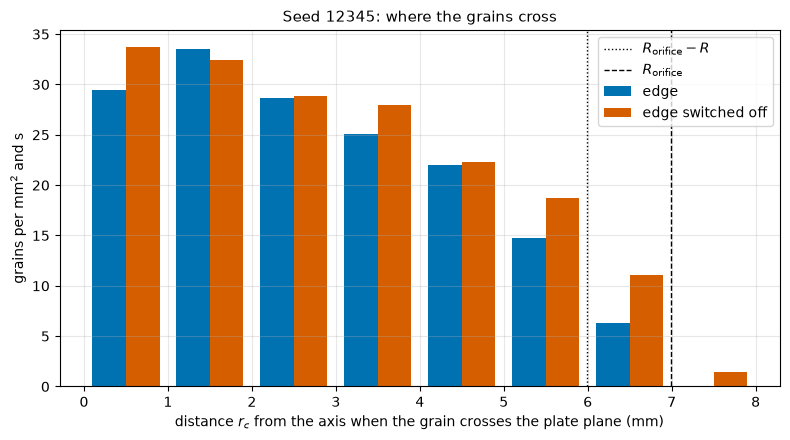

**Table C.2: crossings between 0.58 and 1.92 s, by ring of $r_c$**

| ring (mm) | grains, edge | grains, no edge | per mm$^2$ s, edge | per mm$^2$ s, no edge |
|---|---|---|---|---|
| 0 to 1 | 124 | 142 | 29.5 | 33.7 |
| 1 to 2 | 423 | 410 | 33.5 | 32.5 |
| 2 to 3 | 603 | 607 | 28.6 | 28.8 |
| 3 to 4 | 739 | 823 | 25.1 | 27.9 |
| 4 to 5 | 835 | 844 | 22.0 | 22.3 |
| 5 to 6 | 685 | 865 | 14.8 | 18.7 |
| 6 to 7 | 346 | 608 | 6.3 | 11.1 |
| 7 to 8 | 0 | 88 | 0.0 | 1.4 |

extra grains without the edge: 632, of them 530 (84 %) at r > 5 mm
for r < 5 mm: 2826 grains against 2724 (+4 %)
uniform flux per area: the area for the centres is 36 % larger (R_orifice against R_orifice - R)
crossings beyond R_orifice - R = 6.0 mm (error of r_c): with the edge 9 %, without 16 %


In [13]:
# Table C.2 and Figure C2c: where the grains cross the plane of the plate (code/analyse_c.py crossing; seed 12345 only)
# r_c at the crossing is interpolated between frames 0.022 s apart: an estimate, good to about a radius.
t0w, t1w = 0.58, 1.92                                        # the D2 window of the D7 run
cr = {}
for tag in ("edge", "noedge"):
    c_ = np.loadtxt(f"data/C_crossing_{tag}.csv", delimiter=",")      # particle, t_frame, r_cross
    cr[tag] = c_[(c_[:, 1] > t0w) & (c_[:, 1] < t1w), 2]
rings = np.arange(0.0, 8.01e-3, 1e-3)
area_mm2 = 1e6 * np.pi * (rings[1:] ** 2 - rings[:-1] ** 2)
cnt = {tag: np.histogram(cr[tag], bins=rings)[0] for tag in cr}
flux = {tag: cnt[tag] / area_mm2 / (t1w - t0w) for tag in cr}        # grains per mm^2 and second

fig, ax = plt.subplots()
rm_ = 0.5e3 * (rings[1:] + rings[:-1])
ax.bar(rm_ - 0.2, flux["edge"], 0.4, color=BLUE, label="edge")
ax.bar(rm_ + 0.2, flux["noedge"], 0.4, color=RED, label="edge switched off")
ax.axvline(1e3 * (R_o - 0.5 * d_p), color="k", ls=":", lw=1, label="$R_\\mathrm{orifice} - R$")
ax.axvline(1e3 * R_o, color="k", ls="--", lw=1, label="$R_\\mathrm{orifice}$")
ax.set_xlabel("distance $r_c$ from the axis when the grain crosses the plate plane (mm)")
ax.set_ylabel("grains per mm$^2$ and s")
ax.set_title("Seed 12345: where the grains cross")
ax.legend()
plt.tight_layout()
plt.show()

show_table(f"Table C.2: crossings between {t0w} and {t1w} s, by ring of $r_c$",
           ["ring (mm)", "grains, edge", "grains, no edge", "per mm$^2$ s, edge", "per mm$^2$ s, no edge"],
           [[f"{1e3 * a:.0f} to {1e3 * b:.0f}", cnt["edge"][i], cnt["noedge"][i], f"{flux['edge'][i]:.1f}", f"{flux['noedge'][i]:.1f}"]
            for i, (a, b) in enumerate(zip(rings[:-1], rings[1:]))])
extra = cnt["noedge"] - cnt["edge"]
print(f"extra grains without the edge: {extra.sum()}, of them {extra[5:].sum()} ({100 * extra[5:].sum() / extra.sum():.0f} %) at r > 5 mm")
print(f"for r < 5 mm: {cnt['noedge'][:5].sum()} grains against {cnt['edge'][:5].sum()} "
      f"({100 * (cnt['noedge'][:5].sum() / cnt['edge'][:5].sum() - 1):+.0f} %)")
print(f"uniform flux per area: the area for the centres is {100 * ((R_o / (R_o - 0.5 * d_p)) ** 2 - 1):.0f} % larger (R_orifice against R_orifice - R)")
print(f"crossings beyond R_orifice - R = {1e3 * (R_o - 0.5 * d_p):.1f} mm (error of r_c): "
      f"with the edge {100 * np.mean(cr['edge'] > R_o - 0.5 * d_p):.0f} %, without {100 * np.mean(cr['noedge'] > R_o - 0.5 * d_p):.0f} %")

**Figure C2c.** Flux of the crossing grains per area, edge (blue) against edge switched off (red). The bars differ mainly in the outer rings, from 5 mm outwards.

- The flux per area there is low even without the edge (11 per mm$^2$ s at 6 to 7 mm, 34 at 0 to 1 mm), so the added ring counts for less than its area: a uniform flux would give $+36\,\%$ for the larger area.
- *Hypothesis, untested:* the added ring is the slow boundary zone of the flow.
- Limit of the method: the crossing radius is only good to about a radius; with the edge 9 % of the crossings are found beyond $R_\mathrm{orifice} - R$, where no centre can pass.

<a id="C3"></a>

### C3 Filling and settling

Files: [`initialise_positions_silo`](code/initialise.c), [D7.dat](data/D7.dat), [C_settling_frames.csv](data/C_settling_frames.csv), [C_snapshot_settled.png](data/C_snapshot_settled.png) ([`render_ovito.py`](code/render_ovito.py), [`analyse_c.py`](code/analyse_c.py) `settling`); numbers in the printed lines, Table C.3 and Figures C3a, C3b.

**Fill.** Square lattice with spacing $2.2R_\mathrm{max}$ ($\phi_0 = 0.37$), sites closer to the axis than $R_\mathrm{cyl} - 1.1R_\mathrm{max}$, first layer $1.1R_\mathrm{max}$ above the plate, each coordinate shifted by up to $0.04R_\mathrm{max}$. About 100 mm high at the start (task text); it settles to 57 mm.

**Key numbers**

- **Settling (Figure C3a).** $E_\mathrm{kin}$ peaks at $7\times10^{-3}$ J (0.06 s), then falls six orders of magnitude to $3.9\times10^{-9}$ J at $t_\mathrm{open}$, $5.6\times10^{-7}$ of its maximum. The rms speed at $t_\mathrm{open}$ is at most 0.32 mm/s, and the median $E_\mathrm{kin}$ of the discharge is $2\times10^5$ times larger. $N_\mathrm{silo} = 7500$ until the orifice opens.
- **The bed no longer changes** (Table C.3). In the last four frames (0.219 to 0.285 s, the core of C4 taken anew in each) $\phi_\mathrm{core}$ goes from 0.59718 to 0.59720, 0.6 % of its statistical error; $\rho_b$ changes by 0.07 kg/m³, the highest centre by 0.002 mm, the mean height by 0.6 $\mu$m. Only $Z$ of the core particles still creeps (4.799 to 4.819). The discharge starts from a bed at rest on every scale we measure; $t_\mathrm{open}$ was not changed.

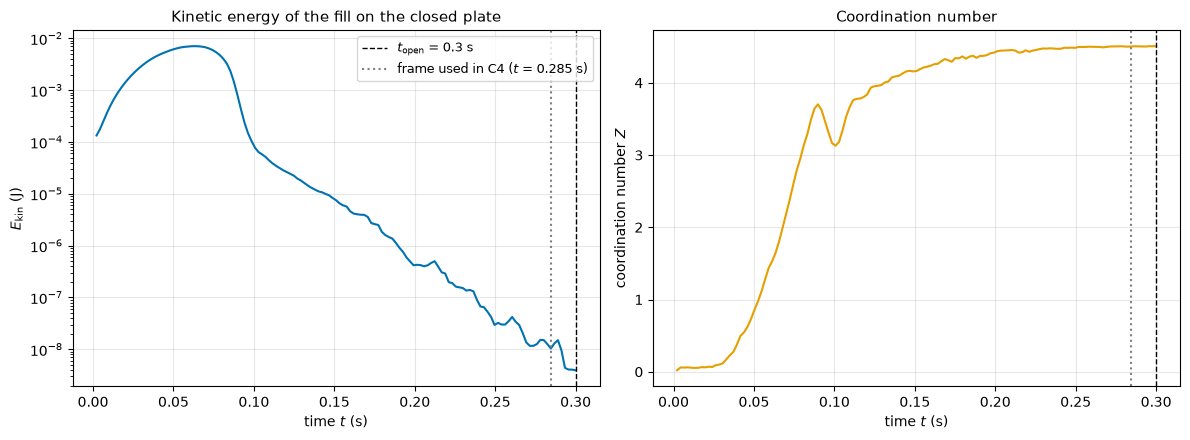

E_kin: maximum 0.0071 J at t = 0.063 s; at t_open 3.9e-09 J = 5.6e-07 of the maximum
rms speed at t_open (translation + rotation, an upper bound): 0.32 mm/s
median E_kin during the discharge (t > t_open + 0.1 s) / E_kin at t_open: 2.1e+05
N_silo = 7500 at t = 0 and at least 7500 up to t_open; lattice phi_0 = 0.366; bed 57.0 mm high


**Table C.3: the last four frames before $t_\mathrm{open}$ (core of C4 re-defined in every frame)**

| $t$ (s) | highest centre (mm) | mean height of centres (mm) | $\phi_\mathrm{core}$ | $\rho_b$ (kg/m³) | $Z$ of core particles |
|---|---|---|---|---|---|
| 0.2189 | 110.150 | 81.5569 | 0.59718 | 1492.9 | 4.799 |
| 0.2408 | 110.147 | 81.5564 | 0.59720 | 1493.0 | 4.805 |
| 0.2627 | 110.147 | 81.5563 | 0.59720 | 1493.0 | 4.819 |
| 0.2846 | 110.148 | 81.5563 | 0.59720 | 1493.0 | 4.819 |
| change (max − min) | 0.002 | 0.0006 | 2.7e-05 | 0.07 | +0.020 |

change of phi_core / statistical error of phi (C4, 0.0046) = 6e-03


In [14]:
# Figure C3a and Table C.3: the fill is at rest before t_open (data/D7.dat; frames: data/C_settling_frames.csv)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].semilogy(t[pre], Ekin[pre], color=BLUE)
ax[0].set_ylabel(r"$E_\mathrm{kin}$ (J)")
ax[0].set_title("Kinetic energy of the fill on the closed plate")
ax[1].plot(t[pre], Z[pre], color=ORANGE)
ax[1].set_ylabel(r"coordination number $Z$")
ax[1].set_title("Coordination number")
for a in ax:
    a.set_xlabel("time $t$ (s)")
    a.axvline(t_open, color="k", ls="--", lw=1, label=r"$t_\mathrm{open}$ = %.1f s" % t_open)
    a.axvline(t_frame, color="gray", ls=":", lw=1.5, label="frame used in C4 ($t$ = %.3f s)" % t_frame)
ax[0].legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

m_tot = rho_p * Vp.sum()
v_rms = np.sqrt(2.0 * Ekin[k_open] / m_tot)
late = t > t_open + 0.1
print(f"E_kin: maximum {Ekin[pre].max():.2g} J at t = {t[pre][np.argmax(Ekin[pre])]:.3f} s; at t_open {Ekin[k_open]:.2g} J = {Ekin[k_open] / Ekin[pre].max():.1e} of the maximum")
print(f"rms speed at t_open (translation + rotation, an upper bound): {1e3 * v_rms:.2f} mm/s")
print(f"median E_kin during the discharge (t > t_open + 0.1 s) / E_kin at t_open: {np.median(Ekin[late]) / Ekin[k_open]:.1e}")
print(f"N_silo = {int(Nsilo[0])} at t = 0 and at least {int(Nsilo[pre].min())} up to t_open; lattice phi_0 = {Vp.mean() / (2.2 * R.max())**3:.3f}; "
      f"bed {1e3 * (z_top - z_silo):.1f} mm high")
cs = np.loadtxt("data/C_settling_frames.csv", delimiter=",")   # frame time z_top z_p99 z_cm phi_core rho_b Z_core Z_all N_core
last = cs[-4:]
rows = [[f"{r_[1]:.4f}", f"{1e3 * r_[2]:.3f}", f"{1e3 * r_[4]:.4f}", f"{r_[5]:.5f}", f"{r_[6]:.1f}", f"{r_[7]:.3f}"] for r_ in last]
rows.append(["change (max − min)", f"{1e3 * np.ptp(last[:, 2]):.3f}", f"{1e3 * np.ptp(last[:, 4]):.4f}", f"{np.ptp(last[:, 5]):.1e}", f"{np.ptp(last[:, 6]):.2f}",
             f"{last[-1, 7] - last[0, 7]:+.3f}"])
show_table("Table C.3: the last four frames before $t_\\mathrm{open}$ (core of C4 re-defined in every frame)",
           ["$t$ (s)", "highest centre (mm)", "mean height of centres (mm)", "$\\phi_\\mathrm{core}$", "$\\rho_b$ (kg/m³)", "$Z$ of core particles"], rows)
print(f"change of phi_core / statistical error of phi (C4, {phi_stat:.4f}) = {np.ptp(last[:, 5]) / phi_stat:.0e}")

**Figure C3a.** Left: $E_\mathrm{kin}$ falls by more than six orders of magnitude after its maximum. Right: $Z$ rises while the fill compacts. The dashed line is $t_\mathrm{open}$, the dotted one the frame used for the packing in C4.

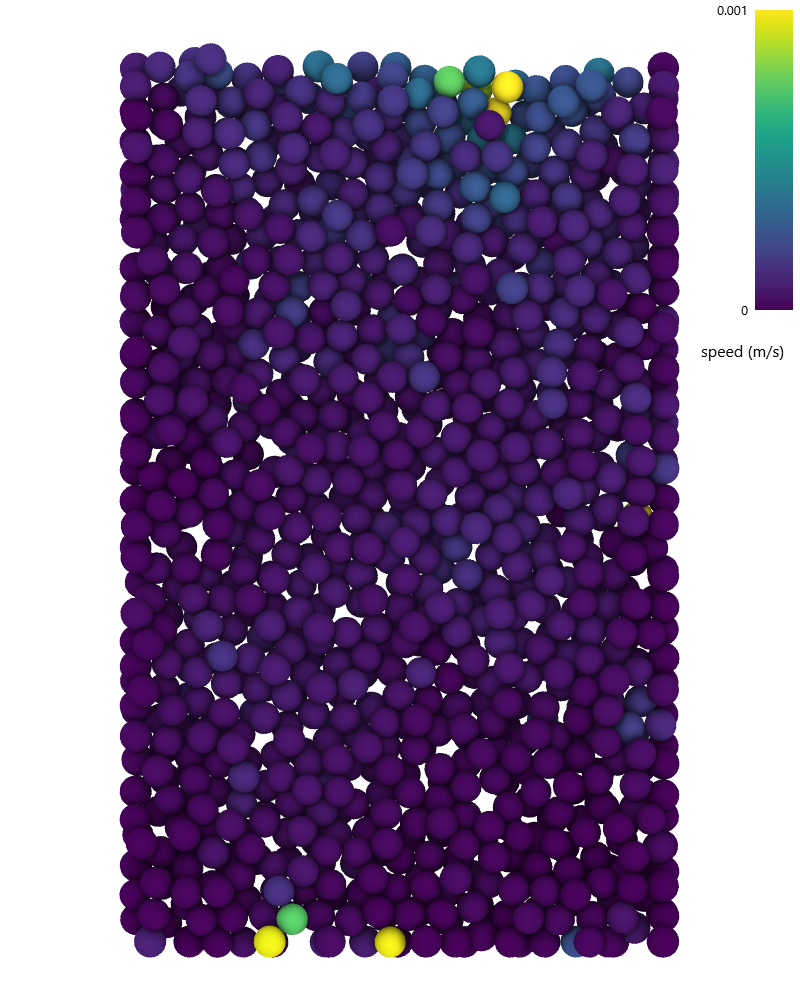

frame t = 0.2846 s: 99 % of the grains move slower than 0.4 mm/s


In [15]:
# Figure C3b: the settled bed, OVITO snapshot (made by code/render_ovito.py, see the build log)
display(Image(filename="data/C_snapshot_settled.png", width=420))
print(f"frame t = {t_frame:.4f} s: 99 % of the grains move slower than {1e3 * np.percentile(speed, 99):.1f} mm/s")

**Figure C3b.** The settled bed at $t = 0.2846$ s (OVITO), 4 mm slab through the axis; colour = speed from 0 to 1 mm/s (unit under the colour bar, scale in m/s). 99 % of the grains move slower than 0.4 mm/s. Grains at the wall and on the plate sit in columns and a row, the interior looks random.

<a id="C4"></a>

### C4 The packing

Files: [C_frame_before_open.dat](data/C_frame_before_open.dat) (frame 13 of the silo run, $t = 0.2846$ s; [`extract_frame.py`](code/extract_frame.py)), [D7.dat](data/D7.dat) for $Z$; numbers in the printed lines and Figures C4a, C4b.

**Definitions.** $d_p = 2.0$ mm. The core is away from the walls: centres closer than $R_\mathrm{cyl} - 2d_p = 13.70$ mm to the axis, between $2d_p$ above the plate and $3d_p$ below the highest centre (110.15 mm), i.e. $57.10 < z < 104.15$ mm; it holds 3958 centres. With $V_i$ the volume of particle $i$ and $\rho_p = 2500$ kg/m³:

$$\phi = \frac{\sum_i V_i}{V_\mathrm{core}}, \qquad \rho_b = \phi\,\rho_p$$

where the sum runs over the particles whose centre is in the core and $V_\mathrm{core} = 27.74$ cm³ is the volume of the core.

**Key numbers**

- **$\phi = 0.597 \pm 0.005$** (stat), systematic $-0.013$ (wall margin).
- **$\rho_b = 1493 \pm 12\ \mathrm{kg/m^3}$** (stat), $-34$ (syst). This is the density used for Beverloo in D3.
- **$Z = 4.51$**, see below.

**Error of $\phi$.** Statistical: the standard error of four azimuthal quarters of the core (0.591, 0.611, 0.591, 0.596). Systematic: each margin of the core varied alone, the other two as specified (Figure C4a).

- The bottom and top margins hardly matter (ranges 0.004 and 0.002).
- The **wall margin** does, since $\phi$ follows the layering (0.570 at $1.5\,d_p$, 0.605 at $1.25\,d_p$), and margins below $2\,d_p$ cut into the wall layer. For 2 to $4.5\,d_p$ (1570 centres left) $\phi$ lies between 0.584 and 0.597, mean 0.590; for 3.5 to $4.5\,d_p$, outside the layering, 0.591.
- The specified core is the top of the range, hence $^{+0.000}_{-0.013}$. The task's number stays the headline.

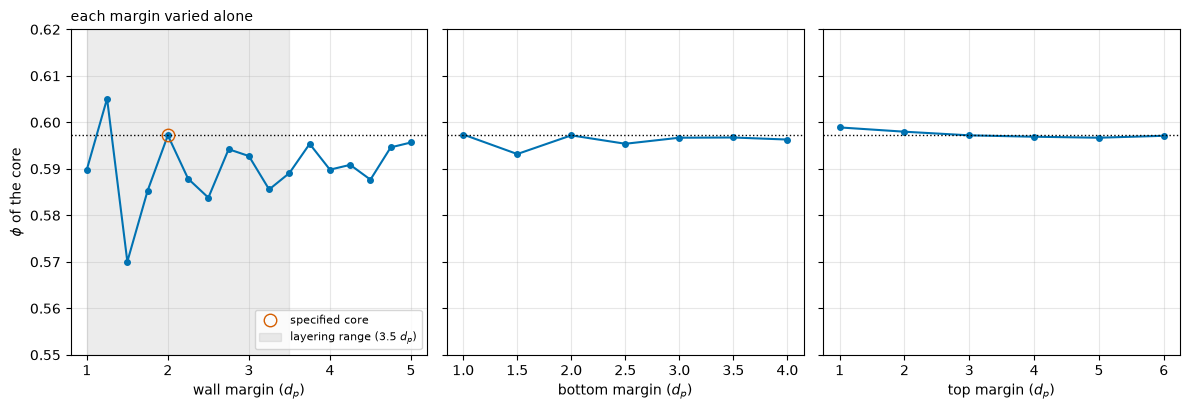

core: r < 13.70 mm, 57.10 < z < 104.15 mm, 3958 centres, volume 27.74 cm^3
highest centre 110.15 mm; phi = 0.5972, rho_b = 1493 kg/m^3
four quarters [0.591 0.611 0.591 0.596]: standard error 0.0046 (rho_b: 12)
ranges of phi: bottom margin 0.0042, top margin 0.0022
wall margin 1.5 d_p: 0.570, 1.25 d_p: 0.605
wall margin 2 to 4.5 d_p (1570 centres left): 0.584 to 0.597, mean 0.590; 3.5 to 4.5 d_p: 0.591
=> phi = 0.597 +- 0.005 (stat), -0.013 / +0.000 (syst)
=> rho_b = 1493 +- 12 (stat), -34 / +0 (syst) kg/m^3


In [16]:
# Figure C4a: phi of the core, each margin varied alone (the other two as specified: wall 2 d_p, bottom 2 d_p, top 3 d_p)
m_wall = np.arange(1.0, 5.01, 0.25)
m_bot = np.arange(1.0, 4.01, 0.5)
m_top = np.arange(1.0, 6.01, 1.0)
scan_w = np.array([core(m)[0] for m in m_wall])
n_w = np.array([core(m)[1].sum() for m in m_wall])
scan_b = np.array([core(2.0, m)[0] for m in m_bot])
scan_t = np.array([core(2.0, 2.0, m)[0] for m in m_top])

fig, ax = plt.subplots(1, 3, figsize=(12, 4.2), sharey=True)
for a, m, p, lab in ((ax[0], m_wall, scan_w, "wall margin ($d_p$)"), (ax[1], m_bot, scan_b, "bottom margin ($d_p$)"), (ax[2], m_top, scan_t, "top margin ($d_p$)")):
    a.plot(m, p, "o-", ms=4, color=BLUE)
    a.axhline(phi, color="k", ls=":", lw=1)
    a.set_xlabel(lab)
ax[0].plot([2.0], [phi], "o", color=RED, ms=9, mfc="none", label="specified core")
ax[0].axvspan(1.0, 3.5, color="gray", alpha=0.15, label="layering range (3.5 $d_p$)")
ax[0].set_ylabel(r"$\phi$ of the core")
ax[0].legend(fontsize=8, loc="lower right")
ax[0].set_title("each margin varied alone", fontsize=10, loc="left")
ax[0].set_ylim(0.55, 0.62)
plt.tight_layout()
plt.show()

legit = (m_wall >= 2.0) & (m_wall <= 4.5)                  # from the specified margin to the one that leaves 1500 centres
free = (m_wall >= 3.5) & (m_wall <= 4.5)                   # margins outside the measured layering range (3.5 d_p, see below)
print(f"core: r < {1e3 * r_max:.2f} mm, {1e3 * z_lo:.2f} < z < {1e3 * z_hi:.2f} mm, {sel.sum()} centres, volume {1e6 * V_core:.2f} cm^3")
print(f"highest centre {1e3 * z_top:.2f} mm; phi = {phi:.4f}, rho_b = {rho_b:.0f} kg/m^3")
print(f"four quarters {np.round(phi_sector, 3)}: standard error {phi_stat:.4f} (rho_b: {rho_p * phi_stat:.0f})")
print(f"ranges of phi: bottom margin {np.ptp(scan_b):.4f}, top margin {np.ptp(scan_t):.4f}")
print(f"wall margin 1.5 d_p: {scan_w[m_wall == 1.5][0]:.3f}, 1.25 d_p: {scan_w[m_wall == 1.25][0]:.3f}")
print(f"wall margin 2 to 4.5 d_p ({n_w[m_wall == 4.5][0]} centres left): {scan_w[legit].min():.3f} to {scan_w[legit].max():.3f}, mean {scan_w[legit].mean():.3f}; "
      f"3.5 to 4.5 d_p: {scan_w[free].mean():.3f}")
print(f"=> phi = {phi:.3f} +- {phi_stat:.3f} (stat), {scan_w[legit].min() - phi:+.3f} / +0.000 (syst)")
print(f"=> rho_b = {rho_b:.0f} +- {rho_p * phi_stat:.0f} (stat), {rho_p * (scan_w[legit].min() - phi):+.0f} / +0 (syst) kg/m^3")

**Figure C4a.** $\phi$ of the core against each margin, the others as specified; the dotted line is the specified value, the red circle the specified wall margin. Only the wall margin moves $\phi$: it follows the layering of the packing near the wall.

**Coordination number.** $Z$ counts particle-particle contacts (wall contacts are not in it), over all particles:

$$Z = \frac{2N_c}{N}$$

where $N_c$ is the number of pairs with $|\mathbf r_i - \mathbf r_j| < R_i + R_j$ and $N$ the number of particles. We take the table value at $t_\mathrm{open}$: 4.508, so $Z = 4.51$ (4.491 to 4.508 in the last 50 ms; a recount from the frame gives 4.501). The particles of the core have 4.82.

In [17]:
# Z of the packing: the table counts particle-particle contacts only, over all particles (wall contacts are not in it)
xyz = np.c_[x, y, z]
pairs = cKDTree(xyz).query_pairs(2.0 * R.max(), output_type="ndarray")
pairs = pairs[np.linalg.norm(xyz[pairs[:, 0]] - xyz[pairs[:, 1]], axis=1) < R[pairs[:, 0]] + R[pairs[:, 1]]]
n_contacts = np.bincount(pairs.ravel(), minlength=len(R))
print(f"Z (table, t_open) = {Z[k_open]:.3f}; last 50 ms: {Z[(t > t_open - 0.05) & pre].min():.3f} to {Z[(t > t_open - 0.05) & pre].max():.3f}; "
      f"recount from the frame: {2 * len(pairs) / len(R):.3f}")
print(f"Z of the particles in the core (all their contacts): {n_contacts[sel].mean():.2f}")

Z (table, t_open) = 4.508; last 50 ms: 4.491 to 4.508; recount from the frame: 4.501
Z of the particles in the core (all their contacts): 4.82


**Radial profile.** The number of centres per volume in thin cylindrical shells of 0.2 mm over the core height, times the mean particle volume $\bar V_p$:

$$n(r)\,V_p = \frac{N_\mathrm{shell}\,\bar V_p}{V_\mathrm{shell}}, \qquad V_\mathrm{shell} = \pi\,(r_2^2 - r_1^2)\,(z_\mathrm{hi} - z_\mathrm{lo})$$

where $N_\mathrm{shell}$ is the number of centres in the shell between $r_1$ and $r_2$. Near the wall this is *not* a local volume fraction, and it can exceed 0.74: the centres of a layer of spheres against a wall all sit at one distance from it. To measure the period and the range of the oscillation we fit a damped cosine around the bulk value, for distances $d$ from the wall above $0.7\,d_p$ (descriptive only):

$$n(d)\,V_p = \phi \left[ 1 + A\,e^{-d/\xi}\cos\left( \frac{2\pi d}{\lambda} + \theta \right) \right]$$

with the amplitude $A$, the decay length $\xi$, the period $\lambda$ and a phase $\theta$ as fit parameters.

**Key numbers** (printed below, marked in Figure C4b)

- **Wall layer:** a sharp maximum 4.13 at $0.50\,d_p$, the centres of the grains touching the wall (not a volume fraction).
- **Layering:** maxima at 1.40, 2.20, 3.20 $d_p$ (1.41, 0.82, 0.69), minima at 0.80, 1.70, 2.70 $d_p$ (0.17, 0.32, 0.45). Beyond $\approx3.5\,d_p$ the profile is flat at 0.597 within the Poisson noise (11 % per shell).
- **Period and range.** The maxima are 0.8 to 1.0 $d_p$ apart. The fit has $\lambda = 0.86 \pm 0.01\,d_p$, $\xi = 1.3\,d_p$ and falls below the noise at $3.5\,d_p$, about four layers. It is only descriptive: $\chi^2$/dof = 2.6, and it gives 0.93 where the second maximum is 1.41.

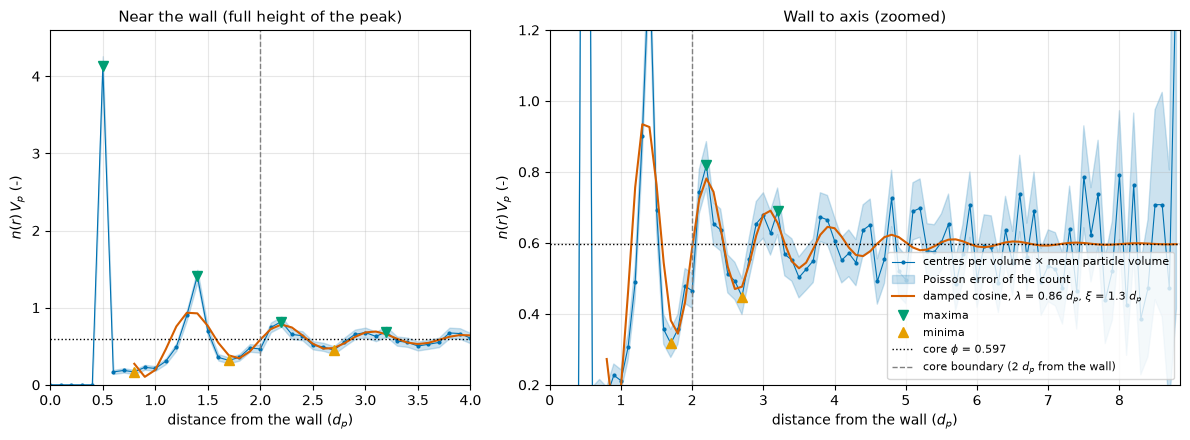

maxima (d_p, value): 0.50 (4.13), 1.40 (1.41), 2.20 (0.82), 3.20 (0.69)
minima (d_p, value): 0.80 (0.17), 1.70 (0.32), 2.70 (0.45)
fit for d > 0.7 d_p: lambda = 0.863 +- 0.009 d_p, xi = 1.31 +- 0.13 d_p, chi2/dof = 2.6
second maximum (1.40 d_p): fit 0.93, data 1.41
noise per shell 11 %: the amplitude falls below it at d = xi ln(|A|/noise) = 3.5 d_p
mean of the profile for 5 < d < 8 d_p: 0.597
R_cyl = 8.85 d_p; layer-free core radius 5.35 d_p = 37 % of the cross-section
in units of the orifice radius: 1.5 for D = 7 d_p, 1.2 for D = 9 d_p


In [18]:
# Figure C4b: radial profile of the centres in thin shells over the core height; damped cosine fitted for d > 0.7 d_p
dr = 0.2e-3
edges = np.arange(0.0, R_cyl + dr, dr)
inz = (z > z_lo) & (z < z_hi)             # over the core height
n_shell, _ = np.histogram(rc[inz], bins=edges)
V_shell = np.pi * (edges[1:]**2 - edges[:-1]**2) * (z_hi - z_lo)
profile = n_shell * Vp.mean() / V_shell   # centres per volume times the mean particle volume
dist = (R_cyl - 0.5 * (edges[1:] + edges[:-1]))[::-1] / d_p      # distance of the shell from the wall, in d_p
profile, n_shell = profile[::-1], n_shell[::-1]
err = profile / np.sqrt(np.maximum(n_shell, 1))                  # Poisson error of the count in a shell

fit_mask = (dist > 0.7) & (n_shell > 0)
osc = lambda d, A, xi, lam, th: phi * (1.0 + A * np.exp(-d / xi) * np.cos(2.0 * np.pi * d / lam + th))
best = None
for lam0 in (0.7, 0.85, 1.0):
    for th0 in (0.0, 1.5, 3.0, 4.5):
        try:
            popt, pcov = curve_fit(osc, dist[fit_mask], profile[fit_mask], p0=(1.0, 1.5, lam0, th0), sigma=err[fit_mask], absolute_sigma=True, maxfev=20000)
        except RuntimeError:
            continue
        chi2 = np.sum(((profile[fit_mask] - osc(dist[fit_mask], *popt)) / err[fit_mask])**2)
        if best is None or chi2 < best[0]:
            best = (chi2, popt, pcov)
chi2, (A, xi, lam, th), pcov = best
dA, dxi, dlam, dth = np.sqrt(np.diag(pcov))
noise = np.mean(1.0 / np.sqrt(n_shell[(dist > 3.0) & (dist < 5.0)]))   # relative Poisson noise of a shell far from the wall
d_noise = xi * np.log(abs(A) / noise)
pk, _ = find_peaks(profile, prominence=0.1)
pk = pk[dist[pk] < 3.5]
tr, _ = find_peaks(-profile, prominence=0.1)
tr = tr[dist[tr] < 3.0]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 1.5]})
for a, ylim, xlim in ((ax[0], (0, 4.6), (0, 4.0)), (ax[1], (0.2, 1.2), (0, R_cyl / d_p))):
    a.plot(dist, profile, ".-", ms=4, lw=0.8, color=BLUE, label="centres per volume $\\times$ mean particle volume")
    a.fill_between(dist, profile - err, profile + err, alpha=0.2, color=BLUE, label="Poisson error of the count")
    a.plot(dist[fit_mask], osc(dist[fit_mask], A, xi, lam, th), "-", color=RED, lw=1.5, label=f"damped cosine, $\\lambda$ = {lam:.2f} $d_p$, $\\xi$ = {xi:.1f} $d_p$")
    a.plot(dist[pk], profile[pk], "v", color=GREEN, ms=7, label="maxima")
    a.plot(dist[tr], profile[tr], "^", color=ORANGE, ms=7, label="minima")
    a.axhline(phi, color="k", ls=":", lw=1, label=f"core $\\phi$ = {phi:.3f}")
    a.axvline(2.0, color="gray", ls="--", lw=1, label="core boundary (2 $d_p$ from the wall)")
    a.set_xlim(*xlim)
    a.set_ylim(*ylim)
    a.set_xlabel("distance from the wall ($d_p$)")
    a.set_ylabel(r"$n(r)\,V_p$ (-)")
ax[0].set_title("Near the wall (full height of the peak)")
ax[1].set_title("Wall to axis (zoomed)")
ax[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

print("maxima (d_p, value): " + ", ".join(f"{dist[i]:.2f} ({profile[i]:.2f})" for i in pk))
print("minima (d_p, value): " + ", ".join(f"{dist[i]:.2f} ({profile[i]:.2f})" for i in tr))
print(f"fit for d > 0.7 d_p: lambda = {lam:.3f} +- {dlam:.3f} d_p, xi = {xi:.2f} +- {dxi:.2f} d_p, chi2/dof = {chi2 / (fit_mask.sum() - 4):.1f}")
print(f"second maximum ({dist[pk[1]]:.2f} d_p): fit {osc(dist[pk[1]], A, xi, lam, th):.2f}, data {profile[pk[1]]:.2f}")
print(f"noise per shell {100 * noise:.0f} %: the amplitude falls below it at d = xi ln(|A|/noise) = {d_noise:.1f} d_p")
print(f"mean of the profile for 5 < d < 8 d_p: {profile[(dist > 5) & (dist < 8)].mean():.3f}")
r_free = R_cyl / d_p - 3.5                                      # radius of the layer-free core in d_p, for a wall ring of 3.5 d_p
print(f"R_cyl = {R_cyl / d_p:.2f} d_p; layer-free core radius {r_free:.2f} d_p = {100 * (r_free / (R_cyl / d_p))**2:.0f} % of the cross-section")
print(f"in units of the orifice radius: {r_free / 3.5:.1f} for D = 7 d_p, {r_free / 4.5:.1f} for D = 9 d_p")

**Figure C4b.** The profile against the distance from the wall: left, the full height of the wall-layer peak; right, wall to axis. Green triangles: maxima, orange: minima, red: the damped cosine. The profile is flat at the core value beyond about $3.5\,d_p$.

- **Period.** The period is a little below the $d_p$ of the task text. *Hypothesis, untested:* layers nest into the gaps of the previous one (close-packed layers are $0.82\,d_p$ apart).
- **Why it oscillates.** Spheres cannot enter the wall, so the first layer sits one radius from it; each layer excludes the next centres from its gaps and favours the following layer. The order fades because the radii differ by 5 % and the packing is random.

**Implication for the silo width.** With a wall ring of $3.5\,d_p$ the layer-free core of our silo ($R_\mathrm{cyl} = 8.85\,d_p$) has radius

$$r_\mathrm{free} = R_\mathrm{cyl} - 3.5\,d_p = 5.35\,d_p, \qquad \frac{r_\mathrm{free}^2}{R_\mathrm{cyl}^2} = 0.37$$

i.e. 37 % of the cross-section: 1.5 times the orifice radius for $D = 7\,d_p$, 1.2 times for $D = 9\,d_p$. The silo must be many $d_p$ wide and wide compared with the orifice, at least $D + 2\times3.5\,d_p$ and several $D$ to be safe; ours (17.7 $d_p$) just meets the first for $D = 9\,d_p$.

<details>
<summary><b>Oral prep</b> (click to open)</summary>

- **Q:** What is the wall-function contract?  
  **A:** `bool wall(p, radius, r, &riw, &vw)`, registered in `wall_function[n]` and counted in `num_walls`. It returns true if the sphere overlaps, and then sets $\mathbf r_{iw}$ = centre minus the closest wall point (with its square length) and the wall velocity there. [`forces.c`](code/forces.c) takes overlap $R - |\mathbf r_{iw}|$, normal $\mathbf r_{iw}/|\mathbf r_{iw}|$ and $\mathbf v - \mathbf v_w$ from it and knows nothing else of the wall.
- **Q:** Walk through your cylinder and your edge, and why the edge point is the closest.  
  **A:** Cylinder: nothing below the plate; contact if $r_c > R_\mathrm{cyl} - R$; $\mathbf r_{iw} = (r_c - R_\mathrm{cyl})\mathbf e_r$. Edge: open orifice, $r_c < R_\mathrm{orifice}$, within one radius of the plane; every plate point has the same vertical distance and a horizontal one of at least $R_\mathrm{orifice} - r_c$ (triangle inequality), equal at the rim in the particle's azimuth: $\mathbf r_{iw} = ((r_c - R_\mathrm{orifice})\mathbf e_r, z - z_\mathrm{silo})$. On the axis any rim point does. Checked against brute force.
- **Q:** What happens at the edge without that code, and why only 16 % faster?  
  **A:** The particle does not feel the rim: a centre inside $R_\mathrm{orifice}$ falls through while overlapping, so the hole is effectively wider. Five seeds: $16 \pm 2\,\%$ faster, not the 50 % of a hole wider by $d_p$. 84 % of the extra grains cross at $r > 5$ mm, where the flux per area is low; that this is the slow boundary zone is our untested hypothesis, and $r_c$ is only good to about a radius.
- **Q:** Why does the fill need no separate randomisation?  
  **A:** Radii spread by 5 %, shifts of up to $0.04R_\mathrm{max}$, and dissipative settling (restitution 0.92 and 0.85, friction) destroy the lattice: about 100 mm of lattice collapses to 57 mm. The result is random: $\phi = 0.60$ (simple cubic 0.52, fcc 0.74), $Z = 4.5$, no layering beyond $3.5\,d_p$ from the wall.
- **Q:** Is the fill really settled at $t_\mathrm{open}$?  
  **A:** On the scale of the flow, yes: $E_\mathrm{kin}$ is $5.6\times10^{-7}$ of its maximum. Over the last 66 ms $\phi$ changes by $3\times10^{-5}$, the bed height by 0.002 mm; only $Z$ of the core creeps (+0.02).
- **Q:** How sure is $\phi$, and why that core?  
  **A:** $0.597 \pm 0.005$ statistical. The core is the task's; its wall margin lies inside the layering, so $\phi$ moves with it (0.584 to 0.597 for 2 to 4.5 $d_p$, the task's value at the top). We keep it and give $-0.013$ systematic.
- **Q:** How do you read the packing profile, and which $\rho_b$ goes into Beverloo?  
  **A:** Centre density times a particle volume against distance from the wall: the 4.1 at $0.5\,d_p$ is the layer touching the wall, then a damped oscillation, then bulk. $\rho_b = \phi\rho_p = 1493\ \mathrm{kg/m^3}$ from the core, since the wall layer, plate and free surface are not the bulk that flows to the orifice.
- **Q:** Why is the period $0.86\,d_p$, and how far does the layering reach?  
  **A:** Fitted $0.86 \pm 0.01\,d_p$, maxima 0.8 to 1.0 apart; below $d_p$ perhaps because layers nest into gaps (untested). It reaches $3.5\,d_p$, about four layers, where it falls below the Poisson noise: that is why the silo must be wide.

</details>

## Part D: Discharge and the Beverloo law

*In the oral you should be able to:* explain why the discharge rate does
not depend on the fill height (and why a liquid's does); derive which
quantities the Beverloo scaling can be built from dimensionally; explain
what happens at small orifices and why.

Write `count_in_silo`: then the last column of the table is $N(t)$, the
number of particles still in the silo. Time zero of the discharge is
$t_\mathrm{open} = 0.3$ s.

### D1) Discharge

From the silo run at $D = 7\,d_p$, deliver **snapshots** at three times
(early, middle, late), sliced through the axis and coloured by speed,
and mark on them where the material flows and where it is stagnant.
Describe the shape of the flowing region and say what it means for how a
silo empties: which grains leave first, those at the top or those at the
bottom?

### D2) Discharge rate

From the same run, extract the steady discharge rate $Q$, in particles
per second and in g/s (mean particle mass above).

Deliver:

- a **figure** of $N(t)$ with the fitted window marked. Fit from the
  moment 10 % of the particles has left until 60 % has left (or the run
  ends): the start-up and the last, shallow part of the fill are not
  steady;
- a **figure** of the rate against the number of particles left (a
  running slope over about 0.1 s), which is where the constancy is
  actually visible;
- a **number**: $Q$ with an error estimate, and evidence that it is
  constant while the fill height drops. Fit the first and the second half
  of the window separately and compare: that is the signature which
  distinguishes a silo from a water clock.

Then explain the physics: why does the head of material above the orifice
not matter, and why does it matter for a draining water tank?

### D3) Beverloo scaling

Add orifices of 6, 8 and 9 $d_p$ (run table) to your 7 $d_p$.

Deliver:

- a **table** of $D$, $D/d_p$, $Q$ and its error, per run;
- a **figure** of $Q^{2/5}$ against $D$ with a linear fit, since Beverloo
  predicts a straight line whose intercept gives $k\,d_p$;
- **numbers**: your fitted $k$ and $C$ with uncertainties, using your
  $\rho_b$ from C4, next to the literature values, and a quantitative
  statement about the quality of the fit;
- a sentence on which of your fitted constants you trust more, and why.

Then derive, dimensionally, why the exponent is $5/2$ for a
three-dimensional silo, and state what it would be in two dimensions.

Finally, the cost of doing better. At $D = 9\,d_p$ the silo is only two
orifices wide, while Beverloo assumes a silo much wider than its
orifice. Estimate, from your own run times, what the four D3 runs would
cost in a silo twice as wide with the same fill height. Say which
factors of that estimate scale with the number of particles and which
do not, and why the time step does not change.

### D4) The small-orifice limit

Run $D = 3\,d_p$.

Deliver a **figure** of $N(t)$ for this run next to your $7\,d_p$ run on
the same axes, a **snapshot** of the blocked orifice, and a description
of what you observe. Explain the mechanism qualitatively, and say what
this implies for the range of validity of the Beverloo correlation you
fitted in D3.

In [19]:
# Part D setup: imports, figure style, constants, the tables of the five runs, the rate function, the speed map (no output)
import re
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler
from IPython.display import Markdown, display
from matplotlib.image import imread
from scipy.stats import chi2 as chi2_dist, spearmanr

BLUE, RED, GREEN, ORANGE = "#0072B2", "#D55E00", "#009E73", "#E69F00"   # colour-blind-safe; D7 = blue, D3 = red, fits = red
plt.rcParams.update({"figure.figsize": (8, 4.5), "font.size": 10, "axes.titlesize": 11, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.prop_cycle": cycler(color=[BLUE, RED, GREEN, ORANGE])})


def show_table(title, header, rows):
    """Show a captioned markdown pipe table (LaTeX is allowed in the header and in the cells)."""
    lines = [f"**{title}**", "", "| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


# --- constants and the tables of the five runs (data/D3, D6, D7, D8, D9.dat) ---
m_p = 1.046e-5                 # mean particle mass in kg (task text)
g_acc = 9.81                   # m/s^2 (GRAVITY of the code)
rho_b, d_rho_b = 1493.0, 27.0  # bulk density from C4 and the error used in the fit (kg/m^3)
N0 = 7500
runs = {3: "D3", 6: "D6", 7: "D7", 8: "D8", 9: "D9"}   # D / d_p -> file name
tabs, hdr = {}, {}
for n_or, name in runs.items():
    tabs[n_or] = np.loadtxt(f"data/{name}.dat")                   # step, time, Z, Epot, Ekin, Etot, N_silo
    hdr[n_or] = open(f"data/{name}.dat").readline()
par = lambda n_or, key: float(re.search(key + r"\s+(\S+)", hdr[n_or]).group(1))
D_or = {n_or: 2.0 * par(n_or, "R_orifice") for n_or in runs}     # orifice diameter in m, from the table header
d_p = D_or[7] / 7.0                                              # mean particle diameter 2 R_mean (m): the exact value of the code
R_cyl, z_silo, t_open, dt = par(7, "R_cyl"), par(7, "z_silo"), par(7, "t_open"), par(7, "dt")


# --- the rate: the definitions used for every run ---
def slope_rate(t, N):
    """Particles per second leaving: minus the slope of a straight-line fit of N(t)."""
    return -np.polyfit(t, N, 1)[0]


def fit_window(tab, lo=0.10, hi=0.60):
    """First row with 10 % of the particles gone to the first row with 60 % gone (the last row if the run ends before)."""
    gone = N0 - tab[:, 6]
    i0 = int(np.argmax(gone >= lo * N0))
    i1 = int(np.argmax(gone >= hi * N0)) if np.any(gone >= hi * N0) else len(tab) - 1
    return i0, i1


def rate(tab, K=4):
    """Q from a fit of N(t) over the window. Error: the window is cut into K pieces of equal duration, each fitted alone; the
    error is the standard error of the mean of the K slopes. (The formal error of the single fit is useless: the residuals
    of a cumulative count are correlated from row to row.) Also the fits of the first and the second half of the window."""
    i0, i1 = fit_window(tab)
    t, N = tab[:, 1], tab[:, 6]
    w = slice(i0, i1 + 1)
    Q = slope_rate(t[w], N[w])
    edges = np.linspace(t[i0], t[i1], K + 1)
    parts = np.array([slope_rate(t[(t >= a) & (t <= b)], N[(t >= a) & (t <= b)]) for a, b in zip(edges[:-1], edges[1:])])
    tm = 0.5 * (t[i0] + t[i1])
    h1, h2 = (t >= t[i0]) & (t <= tm), (t >= tm) & (t <= t[i1])
    return dict(Q=Q, sQ=parts.std(ddof=1) / np.sqrt(K), parts=parts, i0=i0, i1=i1, t0=t[i0], t1=t[i1], tm=tm,
                Q1=slope_rate(t[h1], N[h1]), Q2=slope_rate(t[h2], N[h2]), N1=N[h1].mean(), N2=N[h2].mean(),
                gone_end=(N0 - N[i1]) / N0, sQ_ols=np.sqrt(np.polyfit(t[w], N[w], 1, cov=True)[1][0, 0]))


res = {n_or: rate(tabs[n_or]) for n_or in (6, 7, 8, 9)}
t7, N7 = tabs[7][:, 1], tabs[7][:, 6]
r7 = res[7]

# --- the speed map of D7: mean descent velocity in bins of 1 mm (r, z - z_silo), averaged over 0.58 to 1.92 s (code/analyse_d.py) ---
smap = np.loadtxt("data/D_speedmap_D7.csv", delimiter=",")    # r, z - z_silo, speed, v_z, count  (SI, bins of 1 mm)
rb, zb = np.unique(smap[:, 0]), np.unique(smap[:, 1])
V = np.full((len(zb), len(rb)), np.nan)
for r_, z_, _, vz_, _ in smap:
    V[np.searchsorted(zb, z_), np.searchsorted(rb, r_)] = -vz_ * 1e3          # downward velocity in mm/s
jj = int(np.argmin(abs(1e3 * zb - 30.5)))                                    # the bin 30 mm above the plate
ok_ = np.isfinite(V[jj])
v_bulk = np.sum(V[jj, ok_] * rb[ok_]) / np.sum(rb[ok_])                      # area-weighted mean there (mm/s)
j_b = int(np.argmin(abs(1e3 * zb + 3.0)))                                    # the bin 3.5 mm below the plate
v_below = -1e3 * smap[(smap[:, 1] == zb[j_b]) & (smap[:, 0] == rb[0]), 3][0]

### Definitions and constants used in Part D

Files: [`count_in_silo`](code/walls.c) (written in Part C), [`analyse_d.py`](code/analyse_d.py), [`render_ovito.py`](code/render_ovito.py), [`run_d.sh`](code/run_d.sh), [`collect_times.sh`](code/collect_times.sh); data: [D7.dat](data/D7.dat), [D6.dat](data/D6.dat), [D8.dat](data/D8.dat), [D9.dat](data/D9.dat), [D3.dat](data/D3.dat), [D_walltimes.csv](data/D_walltimes.csv), and the files named in each block.

- $N(t)$ is the table column `N_silo` (centres above the plate). Time zero of the discharge is $t_\mathrm{open} = 0.3$ s.
- **Window.** First row with 10 % gone to first row with 60 % gone, or the last row if the run ends first (D6 ends at 34 %, D8 at 57 %).
- **Rate.** $Q$ is minus the slope of a straight-line fit of $N(t)$ in the window:

$$Q = -\frac{\mathrm{d}N}{\mathrm{d}t}\ \Big|_\mathrm{window}$$

- **Error of $Q$.** The standard error of the mean of the slopes $Q_j$ of $K = 4$ equal pieces of the window,

$$\sigma_Q = \frac{1}{\sqrt{K}}\ \sqrt{\frac{1}{K-1}\sum_{j=1}^{K}\left(Q_j - \bar Q\right)^2}$$

  The formal least-squares error is far too small: the residuals of a cumulative count are correlated (D2).
- **Constants.** $d_p = 1.99875$ mm (exact mean of the code), $D = $ `D_ORIFICE` $d_p$ from the table header, $m_p = 1.046\times10^{-5}$ kg (task text), $\rho_b = 1493 \pm 27$ kg/m³ from C4. The error 27 is the standard deviation over 48 variants of the core in the first version of C4; C4 now gives $\pm12$ (stat) and $-34$ (syst), the same size.

In [20]:
# The constants and the sizes of the five runs (from the table headers)
print(f"d_p = {1e3 * d_p:.5f} mm, m_p = {m_p} kg, rho_b = {rho_b:.0f} +- {d_rho_b:.0f} kg/m^3, g = {g_acc} m/s^2, dt = {dt:.5g} s")
print("D = " + ", ".join(f"{n} d_p = {1e3 * D_or[n]:.2f}" for n in (3, 6, 7, 8, 9)) + " mm")
print(f"R_cyl = {1e3 * R_cyl:.2f} mm")

d_p = 1.99875 mm, m_p = 1.046e-05 kg, rho_b = 1493 +- 27 kg/m^3, g = 9.81 m/s^2, dt = 1.0947e-05 s
D = 3 d_p = 6.00, 6 d_p = 11.99, 7 d_p = 13.99, 8 d_p = 15.99, 9 d_p = 17.99 mm
R_cyl = 17.70 mm


<a id="D1"></a>

### D1 Where the material flows

Files: [D_D7_early.png](data/D_D7_early.png), [D_D7_middle.png](data/D_D7_middle.png), [D_D7_late.png](data/D_D7_late.png) ([`render_ovito.py`](code/render_ovito.py)), [D_speedmap_D7.csv](data/D_speedmap_D7.csv), [D_exit_D7.csv](data/D_exit_D7.csv) ([`analyse_d.py`](code/analyse_d.py)); numbers in Tables D.1 to D.3 and the printed lines.

Snapshots of the $D = 7\,d_p$ run at 90 %, 60 % and 30 % left, sliced through the axis and coloured by speed (Figure D1a). On them, **flowing** means a mean descent velocity above 10 mm/s (red line = 10 mm/s, white dashed = 60 mm/s), taken from the speed map: mean descent velocity in bins of 1 mm, averaged over the frames of 0.58 to 1.92 s.

**Key numbers** (Table D.1)

- **Bulk:** one nearly rigid column. 30 mm above the plate it descends at 32, 31, 29, 24 mm/s at $r$ = 0, 4, 8, 12 mm, and only 7 mm/s at 16 mm (wall). The area-weighted mean there is 22.9 mm/s; $Q$ with $\phi = 0.597$ and the silo area gives 20.0 mm/s (15 % apart, the flowing bulk is probably a bit more dilute: not measured).
- **Funnel over the orifice:** the flow converges. On the axis the descent velocity grows 32, 84, 241 mm/s at 30, 12, 3 mm above the plate; the region above 60 mm/s is a dome reaching $r$ = 6.5 mm and 16.5 mm above the plate (bin centres). Below the plate the stream falls at 0.41 m/s (3.5 mm below, on the axis).
- **Stagnant:** the corners at the plate and a layer along the wall. 3 mm above the plate the velocity is 3 mm/s at $r$ = 12 mm and 0 at 16 mm, against 241 mm/s on the axis. The red line is at $r$ = 10.0, 13.6, 15.7 mm at 3, 12, 24 mm above the plate (wall at 17.7 mm): a wedge in each corner that narrows steeply upwards into the slow layer along the wall.
- **Free surface:** it becomes a crater, lowest on the axis (middle and late snapshot), because the centre sinks faster than the rim.

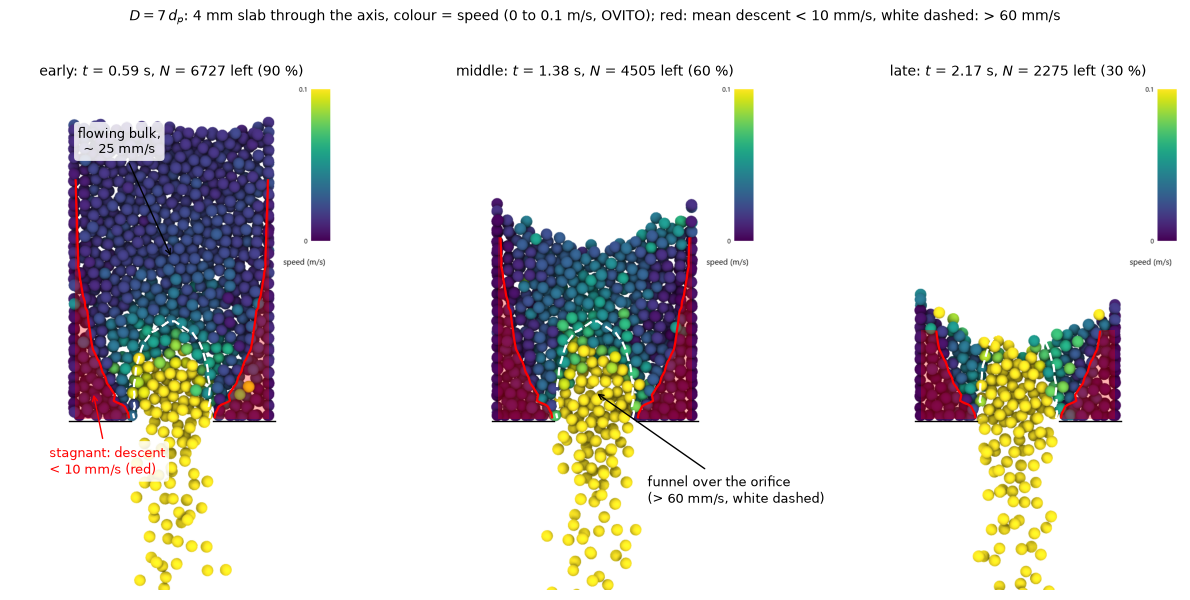

**Table D.1: mean descent velocity (mm/s)**

| mm above the plate | $r$ = 0 mm | $r$ = 4 mm | $r$ = 8 mm | $r$ = 12 mm | $r$ = 16 mm |
|---|---|---|---|---|---|
| 3 | 241 | 147 | 20 | 3 | 0 |
| 12 | 84 | 67 | 35 | 13 | 1 |
| 30 | 32 | 31 | 29 | 24 | 7 |

area-weighted mean at 30 mm: 22.9 mm/s; from Q, phi = 0.597 and the silo area: 20.0 mm/s
the 10 mm/s line is at r = 10.0, 13.6, 15.7 mm at 3, 12, 24 mm above the plate (wall 17.7 mm)
above 60 mm/s: r up to 6.5 mm, up to 16.5 mm above the plate (bin centres)
on the axis 3.5 mm below the plate the descent velocity is 414 mm/s (free fall from the orifice)


In [21]:
# Figure D1a and Table D.1: the three snapshots with the flowing and stagnant regions marked (data/D_speedmap_D7.csv)
# The images are OVITO renders (code/render_ovito.py). Pixel -> position: orthographic view along y, z range 25 to 110 mm, band of
# half width 22 mm, image 640 x 1000: scale = 500 px / fov, fov = 1.02 x 42.5 mm (the numbers of render_ovito.py), the axis in the
# middle column, z = 67.5 mm in the middle row.
scale = 500.0 / (1.02 * 42.5)                       # px per mm
px = lambda r_mm: 320.0 + scale * np.asarray(r_mm)  # column of a point at signed distance r from the axis (mm)
pz = lambda z_mm: 500.0 - scale * (np.asarray(z_mm) - 67.5)   # row of a point at height z (mm)
snap = [("early", 0.5911), ("middle", 1.3793), ("late", 2.1674)]              # frame times printed by render_ovito.py
X = 1e3 * np.r_[-rb[::-1], rb]                                                # signed r (mm), both sides of the axis
Vs = np.hstack([V[:, ::-1], V])
fig, axs = plt.subplots(1, 3, figsize=(12, 6.5))
for a, (nm, tt) in zip(axs, snap):
    k = np.argmin(abs(t7 - tt))
    a.imshow(imread(f"data/D_D7_{nm}.png"))
    h_s = 1e3 * z_silo * N7[k] / N0                                           # mean surface height above the plate (mm): fill height x N/N0
    rows = (zb >= 0) & (1e3 * zb <= h_s)
    Zr = pz(1e3 * z_silo + 1e3 * zb[rows])
    Vm = np.ma.masked_invalid(Vs[rows])
    a.contourf(px(X), Zr, Vm, levels=[0, 10], colors=["red"], alpha=0.30)
    a.contour(px(X), Zr, Vm, levels=[10], colors="red", linewidths=1.6)
    a.contour(px(X), Zr, Vm, levels=[60], colors="white", linewidths=1.6, linestyles="--")
    for sgn in (-1, 1):                                                       # the plate, drawn on the image to check the scale
        a.plot(px([sgn * 1e3 * R_cyl, sgn * 1e3 * D_or[7] / 2]), pz([1e3 * z_silo] * 2), "k-", lw=1)
    a.set_xlim(0, 640)
    a.set_ylim(1000, 0)
    a.set_title(f"{nm}: $t$ = {t7[k]:.2f} s, $N$ = {int(N7[k])} left ({100 * N7[k] / N0:.0f} %)", fontsize=10)
    a.axis("off")
box = dict(boxstyle="round", fc="white", ec="none", alpha=0.85)
axs[0].annotate("stagnant: descent\n< 10 mm/s (red)", xy=(px(-13.5), pz(1e3 * z_silo + 5)), xytext=(px(-21), pz(1e3 * z_silo - 9)),
                color="red", fontsize=9, bbox=box, arrowprops=dict(arrowstyle="->", color="red"))
axs[0].annotate("flowing bulk,\n~ 25 mm/s", xy=(px(0), pz(1e3 * z_silo + 28)), xytext=(px(-9), pz(1e3 * z_silo + 46)),
                color="k", fontsize=9, ha="center", bbox=box, arrowprops=dict(arrowstyle="->", color="k"))
axs[1].annotate("funnel over the orifice\n(> 60 mm/s, white dashed)", xy=(px(0), pz(1e3 * z_silo + 5)), xytext=(px(9), pz(1e3 * z_silo - 14)),
                color="k", fontsize=9, bbox=box, arrowprops=dict(arrowstyle="->", color="k"))
fig.suptitle("$D = 7\\,d_p$: 4 mm slab through the axis, colour = speed (0 to 0.1 m/s, OVITO); red: mean descent < 10 mm/s, white dashed: > 60 mm/s",
             fontsize=10)
plt.tight_layout()
plt.show()

radii = (0, 4, 8, 12, 16)
rows = [[z_] + [f"{V[int(np.argmin(abs(1e3 * zb - (z_ + 0.5)))), int(np.argmin(abs(1e3 * rb - (r_ + 0.5))))]:.0f}" for r_ in radii] for z_ in (3, 12, 30)]
show_table("Table D.1: mean descent velocity (mm/s)", ["mm above the plate"] + [f"$r$ = {r_} mm" for r_ in radii], rows)


def cross10(z_mm):
    """Radius (mm) at which the mean descent velocity first falls below 10 mm/s going outwards at the height z_mm above the plate."""
    v = V[int(np.argmin(abs(1e3 * zb - (z_mm + 0.5))))]
    i = np.flatnonzero(np.isfinite(v) & (v < 10))[0]
    return 1e3 * (rb[i - 1] + (v[i - 1] - 10) / (v[i - 1] - v[i]) * (rb[i] - rb[i - 1]))


fast = np.isfinite(V) & (V > 60) & (zb[:, None] >= 0)
print(f"area-weighted mean at 30 mm: {v_bulk:.1f} mm/s; from Q, phi = 0.597 and the silo area: "
      f"{r7['Q'] * np.pi / 6 * d_p**3 / 0.597 / (np.pi * R_cyl**2) * 1e3:.1f} mm/s")
print("the 10 mm/s line is at r = " + ", ".join(f"{cross10(z_):.1f}" for z_ in (3, 12, 24)) + f" mm at 3, 12, 24 mm above the plate (wall {1e3 * R_cyl:.1f} mm)")
print(f"above 60 mm/s: r up to {1e3 * rb[fast.any(0)].max():.1f} mm, up to {1e3 * zb[fast.any(1)].max():.1f} mm above the plate (bin centres)")
print(f"on the axis {-1e3 * zb[j_b]:.1f} mm below the plate the descent velocity is {v_below:.0f} mm/s (free fall from the orifice)")

**Figure D1a.** Snapshots at 90 %, 60 % and 30 % left. Red: stagnant (mean descent below 10 mm/s), the corners at the plate and a layer along the wall; white dashed: the fast dome over the orifice (above 60 mm/s); between them the bulk descends as one column. The marks are drawn below the mean surface height.

**Who leaves first** ([D_exit_D7.csv](data/D_exit_D7.csv); the grains are followed by index, the code never reorders them; exit time = first frame below the plate, frames 0.022 s apart): **the bottom ones, in the central column** (Tables D.2, D.3, Figure D1b).

- Median exit time by initial height (quarters, bottom to top): 0.55, 0.88, 1.36, 1.90 s; rank correlation of height and exit time 0.79.
- In the column above the orifice the order is strictly bottom to top (rank correlation 0.997).
- The corners are the exception: outside $r$ = 12 mm only 51 % of the grains have left by 2.3 s, and of the bottom layer outside the orifice only 43 %.
- So the silo is first-in first-out in its flowing core, and its bottom corners are last.

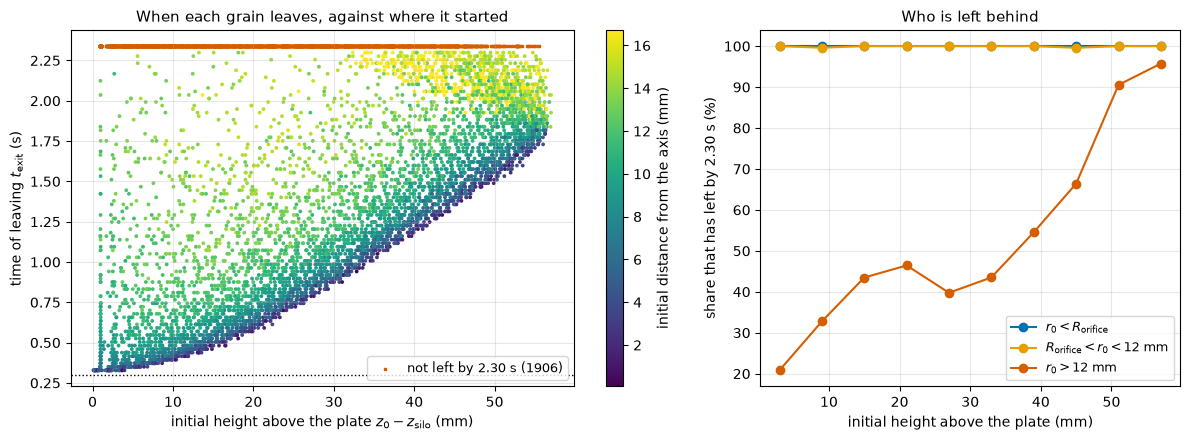

**Table D.2: exit by initial height (quarters of the grains)**

| initial height (mm) | median exit time (s) | share left by the end |
|---|---|---|
| 0.1 to 14.4 | 0.55 | 64 % |
| 14.4 to 28.6 | 0.88 | 71 % |
| 28.6 to 42.5 | 1.36 | 73 % |
| 42.5 to 57.0 | 1.90 | 91 % |

**Table D.3: exit by initial distance from the axis**

| zone | grains | median exit time (s) | share left by the end |
|---|---|---|---|
| $r < R_\mathrm{orifice}$ | 1211 | 0.88 | 100 % |
| $R_\mathrm{orifice} < r < 12$ mm | 2384 | 1.07 | 100 % |
| $12$ mm $< r <$ wall | 3905 | 1.95 | 51 % |

5594 of 7500 grains leave before the end (2.30 s); rank correlation height/exit time: 0.79
rank correlation in the column above the orifice: 0.997
bottom layer outside the orifice (height < 2 mm): 164 grains, 43 % left


In [22]:
# Figure D1b and Tables D.2, D.3: which grains leave first (data/D_exit_D7.csv: initial position at t_open, time of the first frame below the plate)
ex = np.loadtxt("data/D_exit_D7.csv", delimiter=",")                          # x0, y0, z0, radius, t_exit
axis_xy = 0.5 * par(7, "box")
h0 = 1e3 * (ex[:, 2] - z_silo)                                                # initial height above the plate (mm)
r0 = 1e3 * np.hypot(ex[:, 0] - axis_xy, ex[:, 1] - axis_xy)                   # initial distance from the axis (mm)
t_ex = ex[:, 4]
left = np.isfinite(t_ex)
Ro_mm = 0.5e3 * D_or[7]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1.5, 1]})
sc = ax[0].scatter(h0[left], t_ex[left], c=r0[left], s=3, cmap="viridis")
ax[0].scatter(h0[~left], np.full((~left).sum(), t7[-1] + 0.04), c=RED, s=3, marker="s", label=f"not left by {t7[-1]:.2f} s ({(~left).sum()})")
plt.colorbar(sc, ax=ax[0], label="initial distance from the axis (mm)")
ax[0].axhline(t_open, color="k", ls=":", lw=1)
ax[0].set_xlabel("initial height above the plate $z_0 - z_\\mathrm{silo}$ (mm)")
ax[0].set_ylabel("time of leaving $t_\\mathrm{exit}$ (s)")
ax[0].set_title("When each grain leaves, against where it started")
ax[0].legend(loc="lower right", fontsize=9)
bins = np.arange(0, 60, 6.0)
for lo_, hi_, c_, lab in ((0, Ro_mm, BLUE, "$r_0 < R_\\mathrm{orifice}$"), (Ro_mm, 12, ORANGE, "$R_\\mathrm{orifice} < r_0 < 12$ mm"), (12, 18, RED, "$r_0 > 12$ mm")):
    m_ = (r0 >= lo_) & (r0 < hi_)
    fr = [left[m_ & (h0 >= b0) & (h0 < b0 + 6)].mean() if (m_ & (h0 >= b0) & (h0 < b0 + 6)).sum() > 10 else np.nan for b0 in bins]
    ax[1].plot(bins + 3, 100 * np.array(fr), "o-", color=c_, label=lab)
ax[1].set_xlabel("initial height above the plate (mm)")
ax[1].set_ylabel(f"share that has left by {t7[-1]:.2f} s (%)")
ax[1].set_title("Who is left behind")
ax[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

qs = np.quantile(h0, [0, 0.25, 0.5, 0.75, 1.0])
show_table("Table D.2: exit by initial height (quarters of the grains)", ["initial height (mm)", "median exit time (s)", "share left by the end"],
           [[f"{lo_:.1f} to {hi_:.1f}", f"{np.nanmedian(t_ex[(h0 >= lo_) & (h0 <= hi_)]):.2f}", f"{100 * left[(h0 >= lo_) & (h0 <= hi_)].mean():.0f} %"]
            for lo_, hi_ in zip(qs[:-1], qs[1:])])
zones = ((0, Ro_mm, "$r < R_\\mathrm{orifice}$"), (Ro_mm, 12.0, "$R_\\mathrm{orifice} < r < 12$ mm"), (12.0, 18.0, "$12$ mm $< r <$ wall"))
show_table("Table D.3: exit by initial distance from the axis", ["zone", "grains", "median exit time (s)", "share left by the end"],
           [[nm, ((r0 >= lo_) & (r0 < hi_)).sum(), f"{np.nanmedian(t_ex[(r0 >= lo_) & (r0 < hi_)]):.2f}", f"{100 * left[(r0 >= lo_) & (r0 < hi_)].mean():.0f} %"]
            for lo_, hi_, nm in zones])
cen = r0 < Ro_mm
corner = (h0 < 2.0) & (r0 > Ro_mm + 1.0)
print(f"{left.sum()} of {len(ex)} grains leave before the end ({t7[-1]:.2f} s); rank correlation height/exit time: {spearmanr(h0[left], t_ex[left])[0]:.2f}")
print(f"rank correlation in the column above the orifice: {spearmanr(h0[cen & left], t_ex[cen & left])[0]:.3f}")
print(f"bottom layer outside the orifice (height < 2 mm): {corner.sum()} grains, {100 * left[corner].mean():.0f} % left")

**Figure D1b.** Left: each grain's exit time against its initial height, coloured by its initial distance from the axis; the grains over the orifice (dark) leave in order, bottom first. Right: share that has left by the end of the run, by initial height, for three zones: the corner zone ($r_0 > 12$ mm) is last.

<a id="D2"></a>

### D2 Discharge rate

Files: [D7.dat](data/D7.dat); window, fit and error as defined above; numbers in the printed lines and Figure D2.

Steady discharge rate of the $D = 7\,d_p$ run, in particles per second and in g/s (mean particle mass $m_p$): $Q_\mathrm{g/s} = Q\,m_p$.

**Key numbers**

- **$Q = 2804 \pm 18$ particles/s** (0.6 %) $= 29.33 \pm 0.18$ g/s; window 0.58 to 1.92 s, $N$ = 6747 to 2997. Error from 4 pieces; 2, 3, 5, 6, 8 pieces give 21, 20, 27, 20, 25 /s.
- **The formal error is useless:** the least-squares error of the single line is 0.8 /s, but the residuals of a cumulative count have lag-1 autocorrelation 0.96.
- **Constant while the head drops.** Fit of the first and the second half of the window: 2842 /s and 2800 /s ($-1.5$ %), a difference of 1.2 times its error. A water tank would give $-18$ % (see below).
- **Running slope over 0.1 s** stays between 2565 and 3073 /s inside the window (Poisson scatter of 0.1 s counts: 167 /s), and is 2879 /s at $N$ = 2000 to 2500, the shallow end of the fill: no sign of slowing down.

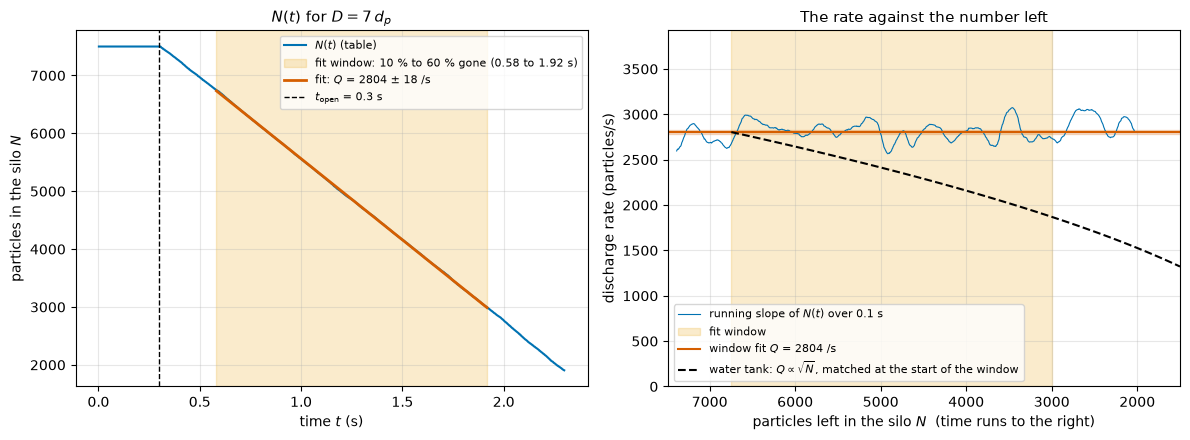

window 0.582 to 1.918 s (N = 6747 to 2997); Q = 2804 +- 18 /s (0.6 %) = 29.33 +- 0.18 g/s
error of Q from 2, 3, 4, 5, 6, 8 pieces of the window: 21, 20, 18, 27, 20, 25 /s
formal least-squares error 0.8 /s; lag-1 autocorrelation of the residuals 0.96
halves: 2842 /s (mean N = 5799) and 2800 /s (mean N = 3927): ratio 0.985 (-1.5 %)
difference 42 /s = 1.2 x its error 2 sQ = 35 /s
water tank: sqrt(3927/5799) = 0.823 (-18 %)
running slope in the window: 2565 to 3073 /s (Poisson scatter 167 /s); at N = 2000 to 2500: 2879 /s


In [23]:
# Figure D2: N(t) with the fitted window, and the running rate against the number left (D = 7 d_p)
tw = (t7 >= r7["t0"]) & (t7 <= r7["t1"])
p_fit = np.polyfit(t7[tw], N7[tw], 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(t7, N7, color=BLUE, lw=1.5, label="$N(t)$ (table)")
ax[0].axvspan(r7["t0"], r7["t1"], color=ORANGE, alpha=0.2, label=f"fit window: 10 % to 60 % gone ({r7['t0']:.2f} to {r7['t1']:.2f} s)")
ax[0].plot(t7[tw], np.polyval(p_fit, t7[tw]), "-", color=RED, lw=2, label=f"fit: $Q$ = {r7['Q']:.0f} $\\pm$ {r7['sQ']:.0f} /s")
ax[0].axvline(t_open, color="k", ls="--", lw=1, label="$t_\\mathrm{open}$ = 0.3 s")
ax[0].set_xlabel("time $t$ (s)")
ax[0].set_ylabel("particles in the silo $N$")
ax[0].set_title("$N(t)$ for $D = 7\\,d_p$")
ax[0].legend(fontsize=8)
# running slope over 0.1 s, plotted against the number left
half = 0.05
rows_run = [k for k in range(len(t7)) if t7[k] - half >= t_open and t7[k] + half <= t7[-1]]
run_Q = np.array([slope_rate(t7[(t7 >= t7[k] - half) & (t7 <= t7[k] + half)], N7[(t7 >= t7[k] - half) & (t7 <= t7[k] + half)]) for k in rows_run])
N_run = N7[rows_run]
ax[1].plot(N_run, run_Q, color=BLUE, lw=0.8, label="running slope of $N(t)$ over 0.1 s")
ax[1].axvspan(N7[r7["i1"]], N7[r7["i0"]], color=ORANGE, alpha=0.2, label="fit window")
ax[1].axhline(r7["Q"], color=RED, lw=1.5, label=f"window fit $Q$ = {r7['Q']:.0f} /s")
ax[1].axhspan(r7["Q"] - r7["sQ"], r7["Q"] + r7["sQ"], color=RED, alpha=0.2)
N_w = np.linspace(N7[r7["i0"]], 1500, 100)
ax[1].plot(N_w, r7["Q"] * np.sqrt(N_w / N7[r7["i0"]]), "k--", lw=1.5, label="water tank: $Q \\propto \\sqrt{N}$, matched at the start of the window")
ax[1].set_xlim(N7[rows_run[0]] + 100, 1500)
ax[1].set_ylim(0, 1.4 * r7["Q"])
ax[1].set_xlabel("particles left in the silo $N$  (time runs to the right)")
ax[1].set_ylabel("discharge rate (particles/s)")
ax[1].set_title("The rate against the number left")
ax[1].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

inw = (N_run <= N7[r7["i0"]]) & (N_run >= N7[r7["i1"]])
resid = N7[tw] - np.polyval(p_fit, t7[tw])
print(f"window {r7['t0']:.3f} to {r7['t1']:.3f} s (N = {int(N7[r7['i0']])} to {int(N7[r7['i1']])}); Q = {r7['Q']:.0f} +- {r7['sQ']:.0f} /s "
      f"({100 * r7['sQ'] / r7['Q']:.1f} %) = {r7['Q'] * m_p * 1e3:.2f} +- {r7['sQ'] * m_p * 1e3:.2f} g/s")
print("error of Q from 2, 3, 4, 5, 6, 8 pieces of the window: " + ", ".join(f"{rate(tabs[7], K)['sQ']:.0f}" for K in (2, 3, 4, 5, 6, 8)) + " /s")
print(f"formal least-squares error {r7['sQ_ols']:.1f} /s; lag-1 autocorrelation of the residuals {np.corrcoef(resid[:-1], resid[1:])[0, 1]:.2f}")
print(f"halves: {r7['Q1']:.0f} /s (mean N = {r7['N1']:.0f}) and {r7['Q2']:.0f} /s (mean N = {r7['N2']:.0f}): "
      f"ratio {r7['Q2'] / r7['Q1']:.3f} ({100 * (r7['Q2'] / r7['Q1'] - 1):+.1f} %)")
print(f"difference {r7['Q1'] - r7['Q2']:.0f} /s = {abs(r7['Q1'] - r7['Q2']) / (2 * r7['sQ']):.1f} x its error 2 sQ = {2 * r7['sQ']:.0f} /s")
print(f"water tank: sqrt({r7['N2']:.0f}/{r7['N1']:.0f}) = {np.sqrt(r7['N2'] / r7['N1']):.3f} ({100 * (np.sqrt(r7['N2'] / r7['N1']) - 1):+.0f} %)")
print(f"running slope in the window: {run_Q[inw].min():.0f} to {run_Q[inw].max():.0f} /s (Poisson scatter {np.sqrt(0.1 * r7['Q']) / 0.1:.0f} /s); "
      f"at N = 2000 to 2500: {run_Q[(N_run < 2500) & (N_run > 2000)].mean():.0f} /s")

**Figure D2.** Left: $N(t)$ of the $D = 7\,d_p$ run with the fitted window (orange) and the fit (red); the start-up and the shallow end are left out. Right: the running slope against the number left. It stays flat around the window fit (red band: its error) while the water-tank curve (dashed) would fall steadily.

**Why the head does not matter.** Grains pass stress sideways into the wall (Janssen): wall friction carries most of the weight, and the pressure at the bottom stops growing with the fill height. What sets the flow is the free-falling region of size about $D$ above the orifice, which looks the same at 90 % and at 30 % full (see the snapshots in [D1](#D1)).

**Why it matters for water.** The pressure is $\rho g h$ and the outflow speed follows Torricelli's law, so $Q$ falls as the tank empties:

$$v = \sqrt{2 g h}, \qquad Q \propto \sqrt{h} \propto \sqrt{N}, \qquad \frac{Q_2}{Q_1} = \sqrt{\frac{\bar N_2}{\bar N_1}} = \sqrt{\frac{3927}{5799}} = 0.82$$

where $\bar N_1$, $\bar N_2$ are the mean numbers of grains left in the first and second half of the window ($h \propto N$ at constant cross-section). Limit of our test: the fill is only $3R_\mathrm{cyl}$ = 53 mm deep, so we did not test a very deep silo.

<a id="D3"></a>

### D3 Beverloo scaling

Files: [D6.dat](data/D6.dat), [D7.dat](data/D7.dat), [D8.dat](data/D8.dat), [D9.dat](data/D9.dat), [`run_d.sh`](code/run_d.sh), [D_walltimes.csv](data/D_walltimes.csv); numbers in Tables D.4, D.5 and the printed lines.

The orifices $D = 6, 8, 9\,d_p$ are added to the $7\,d_p$ of D2; $Q$ and its error of each run are defined as above (Table D.4). Beverloo's law predicts a straight line for $Q^{2/5}$ against $D$ whose intercept gives $k\,d_p$:

$$Q = C\,\rho_b\sqrt{g}\,\left(D - k\,d_p\right)^{5/2}$$

$$Q^{2/5} = s\,\left(D - k\,d_p\right) = s\,D + b, \qquad b = -s\,k\,d_p$$

$$C = \frac{s^{5/2}}{\rho_b\sqrt{g}}, \qquad k = -\frac{b}{s\,d_p}$$

We fit the line to $Q^{2/5}$ in $(\mathrm{kg/s})^{2/5}$, weighted with the propagated error

$$\sigma_{Q^{2/5}} = 0.4\,Q^{-0.6}\,\sigma_Q$$

and use $\rho_b$ from C4.

In [24]:
# Table D.4: the four runs of the Beverloo fit (data/D6, D7, D8, D9.dat; wall-clock: data/D_walltimes.csv)
nn = np.array([6, 7, 8, 9])
Dm = np.array([D_or[n] for n in nn])
Qp = np.array([res[n]["Q"] for n in nn])
sQp = np.array([res[n]["sQ"] for n in nn])
Qk, sQk = Qp * m_p, sQp * m_p                                  # kg/s
y, sy = Qk**0.4, 0.4 * Qk**-0.6 * sQk                          # Q^(2/5) and its propagated error
wt = np.genfromtxt("data/D_walltimes.csv", delimiter=",", names=True, dtype=None, encoding="utf-8")   # run, D_over_dp, wall_s, t_end_s, steps
wall = {r_["run"]: r_["wall_s"] for r_ in wt}
show_table("Table D.4: discharge rate of the four runs", ["$D/d_p$", "$D$ (mm)", "window (s)", "window ends at", "$Q$ (particles/s)", "$Q$ (g/s)",
           "$Q^{2/5}$ ((kg/s)$^{2/5}$)", "first / second half (/s)"],
           [[n, f"{1e3 * Dm[i]:.2f}", f"{res[n]['t0']:.2f} to {res[n]['t1']:.2f}", f"{100 * res[n]['gone_end']:.0f} % gone", f"{Qp[i]:.0f} ± {sQp[i]:.0f}",
             f"{1e3 * Qk[i]:.2f} ± {1e3 * sQk[i]:.2f}", f"{y[i]:.4f} ± {sy[i]:.4f}", f"{res[n]['Q1']:.0f} / {res[n]['Q2']:.0f}"] for i, n in enumerate(nn)])

**Table D.4: discharge rate of the four runs**

| $D/d_p$ | $D$ (mm) | window (s) | window ends at | $Q$ (particles/s) | $Q$ (g/s) | $Q^{2/5}$ ((kg/s)$^{2/5}$) | first / second half (/s) |
|---|---|---|---|---|---|---|---|
| 6 | 11.99 | 0.74 to 1.80 | 34 % gone | 1690 ± 13 | 17.68 ± 0.14 | 0.1990 ± 0.0006 | 1674 / 1693 |
| 7 | 13.99 | 0.58 to 1.92 | 60 % gone | 2804 ± 18 | 29.33 ± 0.18 | 0.2437 ± 0.0006 | 2842 / 2800 |
| 8 | 15.99 | 0.49 to 1.30 | 57 % gone | 4332 ± 36 | 45.31 ± 0.37 | 0.2901 ± 0.0010 | 4310 / 4336 |
| 9 | 17.99 | 0.43 to 1.04 | 60 % gone | 6148 ± 61 | 64.31 ± 0.63 | 0.3337 ± 0.0013 | 6186 / 6030 |

**Key numbers** (Table D.5, Figure D3)

- **Fit:** $s = 22.57 \pm 0.20$ and intercept $b = -0.0717 \pm 0.0028$ $(\mathrm{kg/s})^{2/5}$, anticorrelated ($-0.99$).
- **$k = 1.59 \pm 0.05$** ($+1.8\sigma$ from the literature value 1.5).
- **$C = 0.518 \pm 0.015$** (0.012 from the fit, 0.009 from $\rho_b$): $-4.2\sigma$ from the literature value 0.58 and $-2.2\sigma$ from the lower end 0.55 of the literature range 0.55 to 0.65. We report this as it is; we did not tune anything.
- **Quality:** $\chi^2 = 1.39$ for 2 dof ($p = 0.50$), residuals $+0.15, -0.53, +0.93, -0.48\ \sigma$, largest relative residual of $Q^{2/5}$ 0.31 %, $R^2 = 0.99987$. The $\sigma$ come from 4 pieces each (3 dof), so $\chi^2$ is only a rough guide. Unweighted fit: $k = 1.58$, $C = 0.515$; leaving one run out: $k$ = 1.56 to 1.62, $C$ = 0.510 to 0.524. The straight line is a good description of the four points.

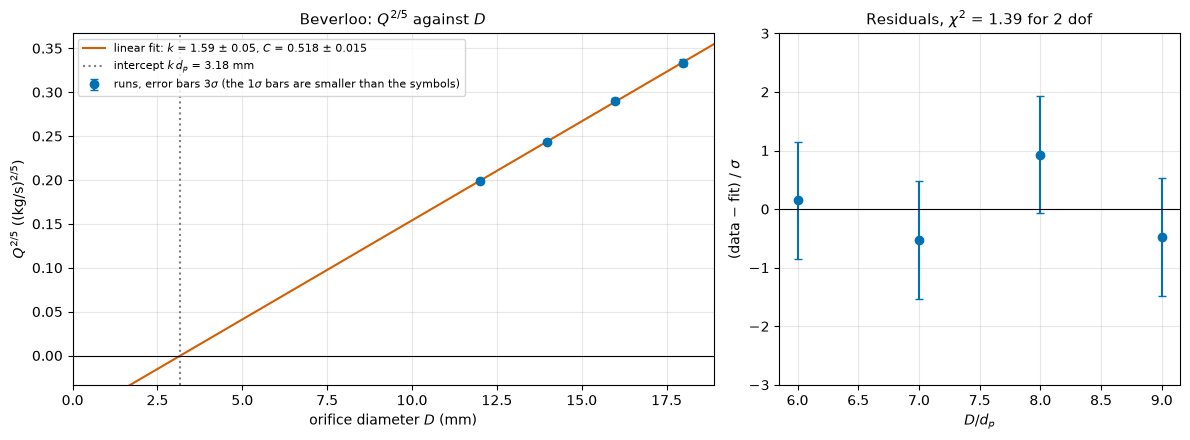

**Table D.5: Beverloo fit**

| quantity | value | literature | distance |
|---|---|---|---|
| $s$ ((kg/s)$^{2/5}$/m) | 22.57 ± 0.20 |  |  |
| $b$ ((kg/s)$^{2/5}$) | -0.0717 ± 0.0028 |  |  |
| $k$ | 1.59 ± 0.05 | about 1.5 | +1.8 $\sigma$ |
| $C$ | 0.518 ± 0.015 | 0.58 (0.55 to 0.65) | -4.2 $\sigma$ / -2.2 $\sigma$ (lower end) |

C: statistical 0.0117, from rho_b 0.0094; corr(s, b) = -0.991
chi2 = 1.39 for 2 dof (p = 0.50); residuals/sigma [ 0.15 -0.53  0.93 -0.48]
R^2 = 0.99987; largest relative residual of Q^(2/5) 0.31 %
unweighted: k = 1.577, C = 0.5149; leave one run out: k = 1.56 to 1.62, C = 0.510 to 0.524
relative errors: k 3.1 %, C 2.9 % (rho_b: 1.8 %); intercept 5.9 d_p from the data centre (7.5 d_p)
scaling check at D = 7 d_p: sqrt(g D) = 0.37 m/s; descent on the axis 3 mm above the plate 0.24 m/s


In [25]:
# Figure D3 and Table D.5: weighted straight-line fit of Q^(2/5) against D (Beverloo), residuals, robustness
def beverloo_fit(x, yv, sv):
    """Weighted straight line yv = s x + b. Returns s, b, covariance, chi^2, residuals/sigma, and k (x-intercept in d_p), C."""
    p, cov = np.polyfit(x, yv, 1, w=1.0 / sv, cov="unscaled")
    s_, b_ = p
    r_ = (yv - np.polyval(p, x)) / sv
    return s_, b_, cov, np.sum(r_**2), r_, -b_ / (s_ * d_p), s_**2.5 / (rho_b * np.sqrt(g_acc))


s_fit, b_fit, cov_fit, chi2_val, resid, k_fit, C_fit = beverloo_fit(Dm, y, sy)
ss, sb, cov_sb = np.sqrt(cov_fit[0, 0]), np.sqrt(cov_fit[1, 1]), cov_fit[0, 1]
sk = np.sqrt((sb**2 + (b_fit / s_fit)**2 * ss**2 - 2 * (b_fit / s_fit) * cov_sb) / (s_fit * d_p)**2)   # error propagation, with the covariance
sC_stat = C_fit * 2.5 * ss / s_fit
sC = C_fit * np.hypot(2.5 * ss / s_fit, d_rho_b / rho_b)
ndof = len(nn) - 2

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
xx = np.linspace(0, 1.05 * Dm.max(), 100)
ax[0].errorbar(1e3 * Dm, y, 3 * sy, fmt="o", color=BLUE, capsize=3, label="runs, error bars $3\\sigma$ (the $1\\sigma$ bars are smaller than the symbols)")
ax[0].plot(1e3 * xx, s_fit * xx + b_fit, "-", color=RED, label=f"linear fit: $k$ = {k_fit:.2f} $\\pm$ {sk:.2f}, $C$ = {C_fit:.3f} $\\pm$ {sC:.3f}")
ax[0].axvline(1e3 * k_fit * d_p, color="gray", ls=":", label=f"intercept $k\\,d_p$ = {1e3 * k_fit * d_p:.2f} mm")
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_xlim(0, 1.05e3 * Dm.max())
ax[0].set_ylim(-0.1 * y.max(), 1.1 * y.max())
ax[0].set_xlabel("orifice diameter $D$ (mm)")
ax[0].set_ylabel("$Q^{2/5}$ ($(\\mathrm{kg/s})^{2/5}$)")
ax[0].set_title("Beverloo: $Q^{2/5}$ against $D$")
ax[0].legend(fontsize=8, loc="upper left")
ax[1].errorbar(Dm / d_p, resid, 1.0, fmt="o", color=BLUE, capsize=3)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_ylim(-3, 3)
ax[1].set_xlabel("$D / d_p$")
ax[1].set_ylabel("(data $-$ fit) / $\\sigma$")
ax[1].set_title(f"Residuals, $\\chi^2$ = {chi2_val:.2f} for {ndof} dof")
plt.tight_layout()
plt.show()

fitted = np.polyval([s_fit, b_fit], Dm)
show_table("Table D.5: Beverloo fit", ["quantity", "value", "literature", "distance"],
           [["$s$ ((kg/s)$^{2/5}$/m)", f"{s_fit:.2f} ± {ss:.2f}", "", ""], ["$b$ ((kg/s)$^{2/5}$)", f"{b_fit:.4f} ± {sb:.4f}", "", ""],
            ["$k$", f"{k_fit:.2f} ± {sk:.2f}", "about 1.5", f"{(k_fit - 1.5) / sk:+.1f} $\\sigma$"],
            ["$C$", f"{C_fit:.3f} ± {sC:.3f}", "0.58 (0.55 to 0.65)", f"{(C_fit - 0.58) / sC:+.1f} $\\sigma$ / {(C_fit - 0.55) / sC:+.1f} $\\sigma$ (lower end)"]])
s_u, b_u = np.polyfit(Dm, y, 1)
loo = [beverloo_fit(np.delete(Dm, j), np.delete(y, j), np.delete(sy, j)) for j in range(4)]
print(f"C: statistical {sC_stat:.4f}, from rho_b {C_fit * d_rho_b / rho_b:.4f}; corr(s, b) = {cov_sb / (ss * sb):+.3f}")
print(f"chi2 = {chi2_val:.2f} for {ndof} dof (p = {chi2_dist.sf(chi2_val, ndof):.2f}); residuals/sigma {np.round(resid, 2)}")
print(f"R^2 = {1 - np.sum((y - fitted)**2) / np.sum((y - y.mean())**2):.5f}; largest relative residual of Q^(2/5) {100 * np.max(abs(y - fitted) / y):.2f} %")
print(f"unweighted: k = {-b_u / (s_u * d_p):.3f}, C = {s_u**2.5 / (rho_b * np.sqrt(g_acc)):.4f}; leave one run out: k = "
      f"{min(l_[5] for l_ in loo):.2f} to {max(l_[5] for l_ in loo):.2f}, C = {min(l_[6] for l_ in loo):.3f} to {max(l_[6] for l_ in loo):.3f}")
print(f"relative errors: k {100 * sk / k_fit:.1f} %, C {100 * sC / C_fit:.1f} % (rho_b: {100 * d_rho_b / rho_b:.1f} %); "
      f"intercept {Dm.mean() / d_p - k_fit:.1f} d_p from the data centre ({Dm.mean() / d_p:.1f} d_p)")
print(f"scaling check at D = 7 d_p: sqrt(g D) = {np.sqrt(g_acc * D_or[7]):.2f} m/s; "
      f"descent on the axis 3 mm above the plate {V[int(np.argmin(abs(1e3 * zb - 3.5))), 0] * 1e-3:.2f} m/s")

**Figure D3.** Left: $Q^{2/5}$ against $D$ with the weighted linear fit (red); the grey dotted line marks the intercept $k\,d_p$. Right: the residuals in units of their errors, all within $1\,\sigma$.

**Which constant we trust more: $k$.** It is a ratio of the intercept and the slope, so $\rho_b$, $m_p$ and $g$ cancel, and it agrees with the literature within 1.8 $\sigma$. Its weakness is the lever arm: the data sit at 6 to 9 $d_p$ and the intercept lies 5.9 $d_p$ from their centre, and the errors of slope and intercept are almost fully anticorrelated ($-0.99$). $C$ has the same relative error (2.9 %), but it takes the slope to the power 5/2 and carries $\rho_b$ (1.8 %). It is 11 % below the literature and 4 $\sigma$ from 0.58. *Hypothesis, untested:* a systematic we did not test; candidates are that the density of the flowing material is not that of the settled core, that the silo is only 2 orifices wide at $D = 9\,d_p$, and that the exponent is fixed at 5/2.

**Check of the scaling.** $\sqrt{gD}$ = 0.37 m/s at $D = 7\,d_p$; the descent velocity on the axis 3 mm above the plate is 0.24 m/s. Same order, as the free-fall argument says.

**Dimensional derivation of the exponent.** $Q$ [kg/s] is built from the bulk density $\rho_b$ [kg m$^{-3}$], $g$ [m s$^{-2}$] and the orifice size $D$ [m] (the grain size only enters through $D - k d_p$):

$$Q = \rho_b^{\,a}\, g^{\,b}\, D^{\,c}$$

Mass, time and length give three equations:

$$\text{mass:}\quad a = 1$$

$$\text{time:}\quad -1 = -2b \quad\Rightarrow\quad b = \frac{1}{2}$$

$$\text{length:}\quad 0 = -3a + b + c \quad\Rightarrow\quad c = 3 - \frac{1}{2} = \frac{5}{2}$$

So $Q \propto \rho_b\sqrt{g}\,D^{5/2}$ in three dimensions. In **two dimensions** the density is mass per area, so the length equation becomes

$$0 = -2a + b + c \quad\Rightarrow\quad c = \frac{3}{2}, \qquad Q \propto \rho\sqrt{g}\,\left(D - k\,d_p\right)^{3/2}$$

Physical picture: the grains fall freely over a length of order $D$, with speed $\sqrt{gD}$, through an area $D^2$ in 3D, and through the width $D$ in 2D.

**Cost of a silo twice as wide** (same fill height, so the number of particles is $N \to 4N = 30\,000$). At $D = 9\,d_p$ the silo is only two orifices wide, while Beverloo assumes a silo much wider than its orifice. We estimate the cost of the four D3 runs from our own run times (Table D.6):

$$\text{cost} = N \times n_\mathrm{steps} \times (\text{cost per particle-step})$$

- **Scales with $N$:** the number of particles ($\times4$), and the number of steps of the discharge: the same fraction has to leave, $t = \text{fraction}\cdot N/Q$ and $Q$ depends on $D$ only, so $\times4$.
- **Does not scale:** the cost per particle-step (cell list: constant work per particle at the same packing) and the settling steps (0.3 s, set by the fill height).
- **$\Delta t$ does not change:** $\Delta t = t_c/20$ and $t_c = \sqrt{m(\pi^2+\ln^2 e)/(2k_n)}$ is a property of the grain mass and the contact spring, not of the silo width or of $N$ (Part A tested the choice of 20 steps per contact).
- **Measured** (four runs in parallel, 20 cores): the cost per particle-step is $1.5$ to $2.3\times10^{-7}$ s. The spread is machine load, not physics.
- **Estimate.** With the discharge time $T$ of a run, the steps at $4N$ are $n_\mathrm{steps}\,(0.3 + 4T)/(0.3 + T)$, i.e. only the discharge time grows.

In [26]:
# Table D.6: cost of a silo twice as wide (N x 4, same fill height), from the measured run times (data/D_walltimes.csv)
T_dis = {6: 1.5, 7: 2.0, 8: 1.0, 9: 0.8}                       # discharge times of the four runs (the T_DISCHARGE flags; D7 is the default)
tot = np.zeros(4)
rows = []
for n in nn:
    r_ = wt[wt["run"] == f"D{n}"][0]
    steps, tw_ = r_["steps"], r_["wall_s"]
    steps_new = (t_open + 4 * T_dis[n]) / dt                    # settling time unchanged, the discharge time x4 for the same fraction gone
    cpps = tw_ / (N0 * steps)
    est = cpps * 4 * N0 * steps_new
    tot += np.array([tw_, 4 * tw_, est, 16 * tw_])
    rows.append([f"D{n}", f"{steps:.0f}", f"{tw_:.0f}", f"{cpps:.2e}", f"{steps_new:.0f}", f"{4 * tw_ / 60:.0f}", f"{est / 60:.0f}", f"{16 * tw_ / 60:.0f}"])
rows.append(["sum", "", f"{tot[0]:.0f} ({tot[0] / 60:.1f} min)", "", "", f"{tot[1] / 60:.0f} ({tot[1] / 3600:.1f} h)", f"{tot[2] / 60:.0f} ({tot[2] / 3600:.1f} h)",
             f"{tot[3] / 60:.0f} ({tot[3] / 3600:.1f} h)"])
show_table("Table D.6: measured and estimated cost", ["run", "steps", "wall-clock (s)", "cost per particle-step (s)", "steps at $4N$",
           "$\\times4$ (min)", "estimate (min)", "$\\times16$ (min)"], rows)
print(f"estimate / measured = {tot[2] / tot[0]:.1f}; longest single run of the estimate: "
      f"{max(wt[wt['run'] == f'D{n}'][0]['wall_s'] * 4 * (t_open + 4 * T_dis[n]) / (t_open + T_dis[n]) for n in nn) / 3600:.2f} h (the four in parallel)")

**Table D.6: measured and estimated cost**

| run | steps | wall-clock (s) | cost per particle-step (s) | steps at $4N$ | $\times4$ (min) | estimate (min) | $\times16$ (min) |
|---|---|---|---|---|---|---|---|
| D6 | 164400 | 270 | 2.19e-07 | 575521 | 18 | 63 | 72 |
| D7 | 210000 | 234 | 1.49e-07 | 758226 | 16 | 56 | 62 |
| D8 | 118600 | 202 | 2.27e-07 | 392816 | 13 | 45 | 54 |
| D9 | 100400 | 176 | 2.33e-07 | 319734 | 12 | 37 | 47 |
| sum |  | 882 (14.7 min) |  |  | 59 (1.0 h) | 201 (3.4 h) | 235 (3.9 h) |

estimate / measured = 13.7; longest single run of the estimate: 1.05 h (the four in parallel)


**Result.** The four runs cost 63, 56, 45, 37 min, **3.4 h in total ($\times13.7$)** against 14.7 min measured. Range: $\times4$ = 1.0 h if the number of steps did not grow, $\times16$ = 3.9 h if all steps grew; run in parallel, the longest takes about 1.05 h.

<a id="D4"></a>

### D4 Small orifice, $D = 3\,d_p$

Files: [D3.dat](data/D3.dat), [D_speedstats_D3.csv](data/D_speedstats_D3.csv) ([`analyse_d.py`](code/analyse_d.py) `--stats`), [D_D3_blocked.png](data/D_D3_blocked.png) ([`render_ovito.py`](code/render_ovito.py)); numbers in the printed lines and Figures D4a to D4c.

**What happens** (Figure D4a)

- 3 grains leave within 20 ms of the opening (the $7\,d_p$ run loses 114 in the first 50 ms). Then $N$ stays at 7497 until 0.869 s.
- 5 more grains leave between 0.869 and 1.079 s, and the run ends at 7492: 8 of 7500 grains in 0.8 s, against 5594 in 2.0 s for $D = 7\,d_p$.

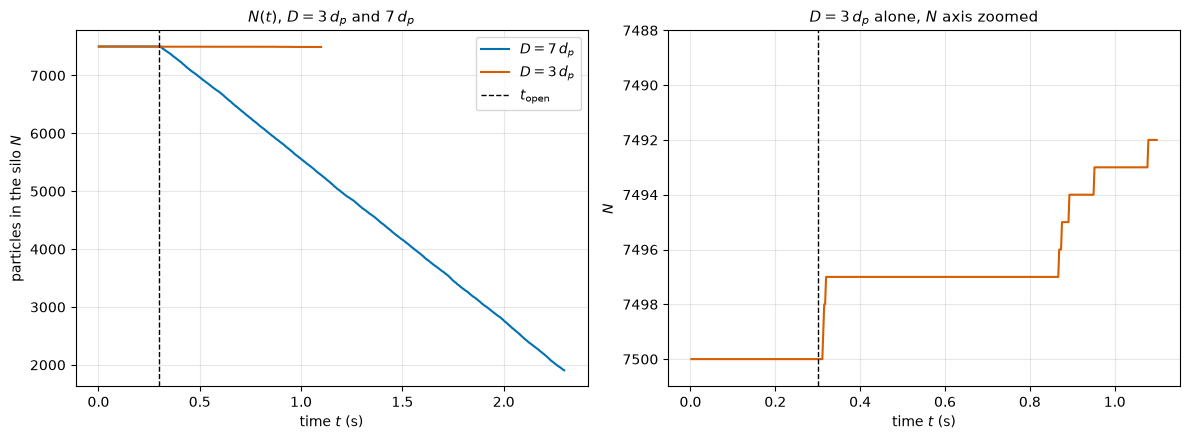

8 of 7500 grains leave in 0.80 s after the opening
departures (table rows) at t = 0.313, 0.315, 0.320, 0.869, 0.876, 0.893, 0.952, 1.079 s
N after the first 3 departures: 7497; at the end 7492
the first 3 are gone by t = 0.320 s (20 ms after the opening), then nothing until 0.869 s
the D = 7 d_p run loses 114 grains in the first 0.05 s after the opening, 5594 by the end


In [27]:
# Figure D4a: N(t) for D = 3 d_p next to the D = 7 d_p run, and D = 3 d_p alone with the N axis zoomed
t3, N3 = tabs[3][:, 1], tabs[3][:, 6]
dep = t3[1:][np.diff(N3) < 0]                                   # table rows in which N dropped
left3 = int(N0 - N3[-1])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(t7, N7, color=BLUE, label="$D = 7\\,d_p$")
ax[0].plot(t3, N3, color=RED, label="$D = 3\\,d_p$")
ax[0].axvline(t_open, color="k", ls="--", lw=1, label="$t_\\mathrm{open}$")
ax[0].set_xlabel("time $t$ (s)")
ax[0].set_ylabel("particles in the silo $N$")
ax[0].set_title("$N(t)$, $D = 3\\,d_p$ and $7\\,d_p$")
ax[0].legend()
ax[1].plot(t3, N3, color=RED)
ax[1].axvline(t_open, color="k", ls="--", lw=1)
ax[1].set_ylim(N0 + 1, N0 - 12)
ax[1].set_xlabel("time $t$ (s)")
ax[1].set_ylabel("$N$")
ax[1].set_title("$D = 3\\,d_p$ alone, $N$ axis zoomed")
plt.tight_layout()
plt.show()

k_stop = np.argmax(N3 <= N0 - 3)
print(f"{left3} of {N0} grains leave in {t3[-1] - t_open:.2f} s after the opening")
print("departures (table rows) at t = " + ", ".join(f"{x_:.3f}" for x_ in dep) + " s")
print(f"N after the first 3 departures: {int(N3[np.searchsorted(t3, 0.5)])}; at the end {int(N3[-1])}")
print(f"the first 3 are gone by t = {t3[k_stop]:.3f} s ({1e3 * (t3[k_stop] - t_open):.0f} ms after the opening), then nothing until {dep[3]:.3f} s")
print(f"the D = 7 d_p run loses {int(N0 - N7[np.argmin(abs(t7 - t_open - 0.05))])} grains in the first 0.05 s after the opening, {int(N0 - N7[-1])} by the end")

**Figure D4a.** Left: $N(t)$ of the $3\,d_p$ run (red) is flat on the scale of the $7\,d_p$ run (blue). Right: the same run with the $N$ axis zoomed to 12 grains: three early departures, a long plateau and five late ones.

**The arch is static.** In the quiet phase 0.40 to 0.80 s the median speed of the grains in the silo is 0.007 mm/s and the 99th percentile 0.044 mm/s (Figure D4b), against 25 mm/s for the bulk of the $7\,d_p$ silo.

- The fastest grain (1.5 to 3.6 mm/s) is in 67 % of the frames a grain at $r$ = 1.9 mm whose centre is 0.68 mm above the plate (a grain in the opening, held by its neighbours), otherwise a grain lying on the plate.
- The 5 late departures are small collapses of the arch (fastest grain up to 96 mm/s), after which it holds again.

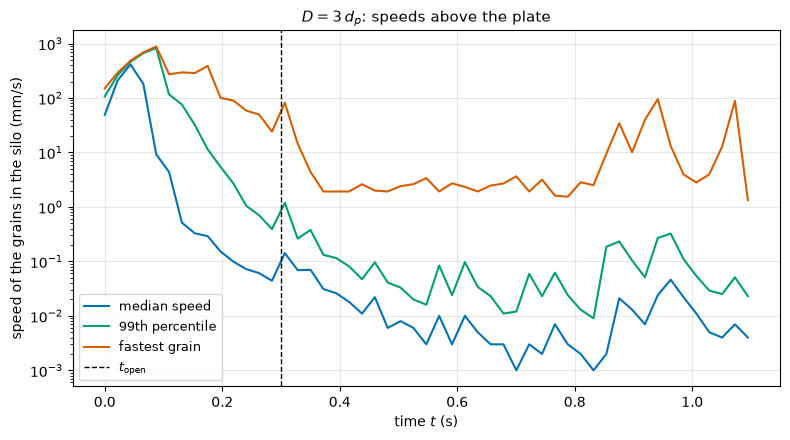

quiet phase 0.40 to 0.80 s: median speed 0.0069 mm/s, 99th percentile 0.044 mm/s
fastest grain in the quiet phase: 1.5 to 3.6 mm/s
it is over the opening (r < 3.0 mm) in 67 % of the frames: r = 1.9 mm, 0.68 mm above the plate
(a centre lower than one radius); otherwise on the plate, 11 mm from the axis
after 0.82 s (the late departures) the fastest grain reaches 96 mm/s
for comparison the D = 7 d_p bulk descends at 23 mm/s


In [28]:
# Figure D4b: speeds of the grains in the D = 3 d_p silo per frame (data/D_speedstats_D3.csv)
ss3 = np.loadtxt("data/D_speedstats_D3.csv", delimiter=",")     # t, n_silo, v_median, v_p99, v_max, r and z of the fastest grain
fig, ax = plt.subplots()
ax.semilogy(ss3[:, 0], 1e3 * ss3[:, 2], color=BLUE, label="median speed")
ax.semilogy(ss3[:, 0], 1e3 * ss3[:, 3], color=GREEN, label="99th percentile")
ax.semilogy(ss3[:, 0], 1e3 * ss3[:, 4], color=RED, label="fastest grain")
ax.axvline(t_open, color="k", ls="--", lw=1, label="$t_\\mathrm{open}$")
ax.set_xlabel("time $t$ (s)")
ax.set_ylabel("speed of the grains in the silo (mm/s)")
ax.set_title("$D = 3\\,d_p$: speeds above the plate")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

q_ = (ss3[:, 0] > 0.40) & (ss3[:, 0] < 0.80)
in_hole = ss3[q_, 5] < 0.5 * D_or[3]
print(f"quiet phase 0.40 to 0.80 s: median speed {1e3 * ss3[q_, 2].mean():.4f} mm/s, 99th percentile {1e3 * ss3[q_, 3].mean():.3f} mm/s")
print(f"fastest grain in the quiet phase: {1e3 * ss3[q_, 4].min():.1f} to {1e3 * ss3[q_, 4].max():.1f} mm/s")
print(f"it is over the opening (r < {0.5e3 * D_or[3]:.1f} mm) in {100 * in_hole.mean():.0f} % of the frames: r = "
      f"{1e3 * np.median(ss3[q_, 5][in_hole]):.1f} mm, {1e3 * np.median(ss3[q_, 6][in_hole]):.2f} mm above the plate")
print(f"(a centre lower than one radius); otherwise on the plate, {1e3 * np.median(ss3[q_, 5][~in_hole]):.0f} mm from the axis")
print(f"after 0.82 s (the late departures) the fastest grain reaches {1e3 * ss3[ss3[:, 0] > 0.82, 4].max():.0f} mm/s")
print(f"for comparison the D = 7 d_p bulk descends at {v_bulk:.0f} mm/s")

**Figure D4b.** Speeds of the grains above the plate. Before $t_\mathrm{open}$ the fill settles. After the opening the median speed falls to about $10^{-2}$ mm/s and the 99th percentile to about $10^{-1}$ mm/s; in the quiet phase the fastest grain stays at 2 to 4 mm/s, and it spikes at the late departures.

**Snapshot of the blocked orifice** (Figure D4c, below): the grains over and around the opening are almost at rest (colour scale 0 to 1 mm/s) and the opening, 3 grain diameters wide, is blocked.

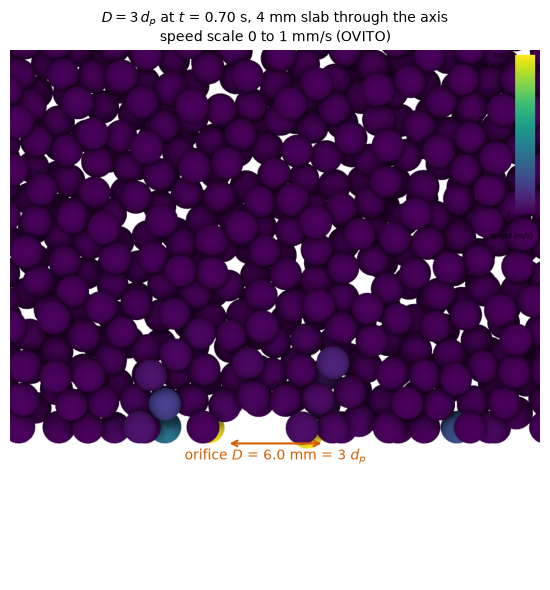

In [29]:
# Figure D4c: the blocked orifice, OVITO snapshot of the D = 3 d_p run at t = 0.70 s (code/render_ovito.py)
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(imread("data/D_D3_blocked.png"))
sc4 = 900 / (2 * 1.02 * 16.0)                                   # px per mm: zrange 45 to 77 mm, band half width 16 mm, 900 x 900 px (render_ovito.py)
cx_, rz_ = 450.0, 450.0 - sc4 * (1e3 * z_silo - 61.0)
ax.annotate("", xy=(cx_ - sc4 * 0.5e3 * D_or[3], rz_), xytext=(cx_ + sc4 * 0.5e3 * D_or[3], rz_), arrowprops=dict(arrowstyle="<->", color=RED, lw=1.5))
ax.text(cx_, rz_ + 28, f"orifice $D$ = {1e3 * D_or[3]:.1f} mm = 3 $d_p$", color=RED, ha="center", fontsize=10)
ax.set_title("$D = 3\\,d_p$ at $t$ = 0.70 s, 4 mm slab through the axis\nspeed scale 0 to 1 mm/s (OVITO)", fontsize=10)
ax.axis("off")
plt.tight_layout()
plt.show()

**Figure D4c.** The blocked orifice of the $D = 3\,d_p$ run at $t = 0.70$ s: a 4 mm slab through the axis, colour = speed from 0 to 1 mm/s. The red arrow is the orifice width, 6.0 mm $= 3\,d_p$. The grains around it are at rest.

In [30]:
# The fitted Beverloo law extrapolated to D = 3 d_p (an extrapolation; the run gives 8 grains)
Q3 = (s_fit * (3 * d_p - k_fit * d_p))**2.5 / m_p
print(f"fitted law at D = 3 d_p: {Q3:.0f} particles/s, about {Q3 * (t3[-1] - t_open):.0f} grains in {t3[-1] - t_open:.2f} s; observed {left3}")
print(f"the law has Q = 0 at D = k d_p = {k_fit:.1f} d_p")

fitted law at D = 3 d_p: 98 particles/s, about 78 grains in 0.80 s; observed 8
the law has Q = 0 at D = k d_p = 1.6 d_p


**Mechanism.** An arch of grains that touch and support each other spans the opening. With $D$ only $3\,d_p$ a few grains are enough to span it, and friction plus geometry carry the load (the weight above presses the grains into the arch). Once the arch exists nothing moves to break it up; it fails only in rare rearrangements.

**One run is one outcome.** Blocking is a random event: a different seed or a different fill could pass more grains or none. We do not give a probability.

**For the range of validity of Beverloo.** The law holds only where arches are rare: the fitted range is 6 to 9 $d_p$. The $(D - k d_p)^{5/2}$ form describes the flow of an open orifice and has no mechanism for arching.

- Extrapolated to $3\,d_p$ the fitted law gives 98 particles/s, about 78 grains in the 0.80 s of the run (printed above); the silo gives 8.
- The law has $Q = 0$ only at $D = k\,d_p = 1.6\,d_p$, but in our run the orifice is already blocked at $3\,d_p$.

<details>
<summary><b>Oral prep</b> (click to open)</summary>

- **Q:** Why does the discharge rate not depend on the fill height, and why does a liquid's?  
  **A:** Grains transmit stress sideways into the walls (Janssen): friction at the wall carries most of the weight, so the pressure at the bottom stops growing with the fill height, and the flow is set by the free-falling zone of size $D$ at the orifice, which looks the same at 90 % and at 30 % full. In our run $Q$ is 2842 /s in the first half and 2800 /s in the second half of the window ($-1.5$ %), and the running slope is flat (Figure D2). In water the pressure is $\rho g h$ and $v = \sqrt{2gh}$ (Torricelli), so $Q \propto \sqrt h$: the same two halves would differ by $-18$ %.
- **Q:** Which quantities can the Beverloo scaling be built from, and what is the derivation?  
  **A:** $Q$ [kg/s] from $\rho_b$ [kg/m³], $g$ [m/s²] and $D$ [m] (the grain size only enters through $D - k d_p$). $Q = \rho_b^a g^b D^c$: mass gives $a = 1$, time gives $b = 1/2$, length gives $c = 3 - 1/2 = 5/2$ (in 2D $c = 3/2$). Physically: grains fall freely over a length of order $D$, speed $\sqrt{gD}$, through an area $D^2$. We check it: $\sqrt{gD}$ = 0.37 m/s, the speed on the axis 3 mm above the plate is 0.24 m/s.
- **Q:** What happens at small orifices and why?  
  **A:** At $3\,d_p$ the silo blocked: 3 grains left in the first 20 ms, then the flow stopped (8 of 7500 grains in 0.8 s, speeds in the silo $\sim 10^{-2}$ mm/s). An arch of mutually supporting grains spans the opening; few grains are enough at this size, and friction plus the geometry carry the load. It is random (one run, no probability claimed). So Beverloo holds only for orifices large enough that arches are rare (our fit: 6 to 9 $d_p$); extrapolated to $3\,d_p$ it predicts about 98 grains/s where we see none.
- **Q:** How did you get the error of $Q$, and which of $k$ and $C$ do you trust?  
  **A:** The formal error of the fit is 0.8 /s but meaningless, because the residuals of a cumulative count are correlated (autocorrelation 0.96). We cut the window into 4 equal pieces, fit each, and take the standard error of the mean (18 /s for $D = 7\,d_p$). We trust $k$ more: it is a ratio of fit parameters, so $\rho_b$, $m_p$ and $g$ cancel, and it is within 1.8 $\sigma$ of 1.5. $C$ ($0.518 \pm 0.015$) is 4 $\sigma$ below 0.58, and depends on the density we used.

</details>

## Lessons learned

What would you do differently if you started over? What surprised you?
What in your results still bothers you? This is the last assignment of
the course: also say which of the four methods you would reach for first
if a new problem landed on your desk, and why.

*Lessons learned:* …

## Hand-in

One zip per group, layout exactly:

```
<group>_A4.zip
├── A4.ipynb     this notebook, filled in and executed
│                (all outputs present; task cells untouched)
├── A4.html      python3 nb2html.py A4.ipynb
├── code/        all .c/.h + README.md; must build with
│                gcc -O3 *.c -o dem -lm    (no binaries)
└── data/        every data file and image this notebook loads
                 (no trajectories)
```

Long runs are done in the terminal; record the exact commands in the
*Build & run log* and let the notebook load the saved output from
`data/`. Handed in executed, the notebook must open and display without
rerunning anything.

**Before you submit,** check your own zip:

```
python3 check_my_submission.py <group>_A4.zip --release A4.ipynb
```

where `--release` is a freshly downloaded, unmodified `A4.ipynb`. It
verifies the layout, that the task cells are untouched, that every cell
has been executed, that your C code compiles, and that every path and
link in the notebook is relative and present in the zip. Fix what it
reports, then submit. Setting up the Python environment
(`requirements.txt`, both helper scripts) is described on the Canvas page
*Working on the assignments*.

All four notebooks must be handed in before the oral examinations start.